# Biểu diễn trực quan dữ liệu – Chương 2: Biểu đồ
## Notebook đáp án hoàn chỉnh cho Đề thực hành nâng cao

Dữ liệu: `gap-every-five-years.xlsx` (country, year, lifeExp, pop, gdpPercap). Đặt file xlsx cùng thư mục với notebook rồi chạy **Run All**. Hình được lưu vào thư mục `output/`.

Câu 7 cần internet (tải GeoJSON) và các thư viện: `wordcloud`, `country_converter`, `shapely`; Câu 6j cần `squarify`; Câu 8 cần `networkx`, `matplotlib-venn`.

In [4]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

DATA = "gap-every-five-years.xlsx"          # đặt cùng thư mục với notebook
OUT = Path("output"); OUT.mkdir(exist_ok=True)

# Okabe-Ito: bảng mầu phân loại thân thiện người mù mầu (slide 21)
OKABE = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "axes.titleweight": "bold",
                     "font.size": 10, "axes.unicode_minus": False})

def show(name):
    """Lưu hình vào thư mục output/ rồi hiển thị."""
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

---
## Câu 1. Đọc và khám phá dữ liệu

### 1a) Đọc dữ liệu — **0.5 điểm**

> Đọc tập tin gap-every-five-years.xlsx vào dataframe. Cho biết số dòng, số cột, kiểu dữ liệu của từng cột và hiển thị 5 dòng đầu.

In [5]:
folder = 'C:/Users/DELL/Documents/Storage/UEH/Biểu diễn trực quan dữ liệu/SPROJECT6_UEH_DATA-VISUALISATION/Data'
df = pd.read_csv(folder + '/gap-every-five-years.csv', encoding = 'utf-8')
print(df)
print("Số dòng, số cột:", df.shape)
print(df.dtypes)
display(df.head())

          country  year  lifeExp         pop   gdpPercap
0     Afghanistan  1952   28.801   8425333.0  779.445314
1     Afghanistan  1957   30.332   9240934.0  820.853030
2     Afghanistan  1962   31.997  10267083.0  853.100710
3     Afghanistan  1967   34.020  11537966.0  836.197138
4     Afghanistan  1972   36.088  13079460.0  739.981106
...           ...   ...      ...         ...         ...
1699     Zimbabwe  1987   62.351   9216418.0  706.157306
1700     Zimbabwe  1992   60.377  10704340.0  693.420786
1701     Zimbabwe  1997   46.809  11404948.0  792.449960
1702     Zimbabwe  2002   39.989  11926563.0  672.038623
1703     Zimbabwe  2007   43.487  12311143.0  469.709298

[1704 rows x 5 columns]
Số dòng, số cột: (1704, 5)
country          str
year           int64
lifeExp      float64
pop          float64
gdpPercap    float64
dtype: object


,country,year,lifeExp,pop,gdpPercap
0,Afghanistan,1952,28.801,8425333.0,779.445314
1,Afghanistan,1957,30.332,9240934.0,820.853030
2,Afghanistan,1962,31.997,10267083.0,853.100710
3,Afghanistan,1967,34.020,11537966.0,836.197138
4,Afghanistan,1972,36.088,13079460.0,739.981106


**Nhận xét / đáp án:** Dữ liệu có **1704 dòng × 5 cột**: `country` (chuỗi), `year` (int64), `lifeExp` (float64), `pop` (int64), `gdpPercap` (float64).

### 1b) Kiểm tra dữ liệu  — **1.0 điểm**

> Kiểm tra giá trị thiếu. Cho biết số quốc gia và các năm có trong dữ liệu.
>
> Mở rộng: kiểm tra thêm dòng trùng, trùng khoá (country, year), tính cân bằng của panel (mỗi quốc gia có đủ số năm?) và viết assert kiểm tra miền giá trị hợp lý (lifeExp, pop, gdpPercap).

In [6]:
print(df.isna().sum())
print("Dòng trùng hoàn toàn:", df.duplicated().sum(),
      "| trùng khoá (country, year):", df.duplicated(["country", "year"]).sum())
print("Số quốc gia:", df["country"].nunique())
print("Các năm:", sorted(df["year"].unique()))
n_per = df.groupby("country")["year"].nunique()
print("Panel cân bằng (mỗi nước đủ 12 năm):", bool((n_per == 12).all()))
assert df["lifeExp"].between(20, 90).all() and (df["pop"] > 0).all() and (df["gdpPercap"] > 0).all()
display(df.describe().T)

country      0
year         0
lifeExp      0
pop          0
gdpPercap    0
dtype: int64
Dòng trùng hoàn toàn: 0 | trùng khoá (country, year): 0
Số quốc gia: 142
Các năm: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Panel cân bằng (mỗi nước đủ 12 năm): True


,count,mean,std,min,25%,50%,75%,max
year,1704.0,1.979500e+03,1.726533e+01,1952.000000,1.965750e+03,1.979500e+03,1.993250e+03,2.007000e+03
lifeExp,1704.0,5.947444e+01,1.291711e+01,23.599000,4.819800e+01,6.071250e+01,7.084550e+01,8.260300e+01
pop,1704.0,2.960121e+07,1.061579e+08,60011.000000,2.793664e+06,7.023596e+06,1.958522e+07,1.318683e+09
gdpPercap,1704.0,7.215327e+03,9.857455e+03,241.165876,1.202060e+03,3.531847e+03,9.325462e+03,1.135231e+05


**Nhận xét / đáp án:** Không có giá trị thiếu, không trùng dòng/khoá. **142 quốc gia**, 12 năm (1952–2007, cách 5 năm); panel cân bằng (142×12 = 1704).

### 1c) Biến dẫn xuất, lọc, xuất CSV  — **1.0 điểm**

> Thêm cột gdp = gdpPercap x pop. Lọc dữ liệu năm 2007, tìm 5 quốc gia có tuổi thọ cao nhất và lưu dữ liệu năm 2007 ra tập tin CSV.
>
> Bẫy: giải thích vì sao viết df.gdpPercap * df.pop gây lỗi và cách khắc phục. Top 5 phải xử lý được trường hợp đồng hạng (hòa điểm). File CSV phải mở đúng tiếng Việt trong Excel và phải đọc lại để chứng minh shape không đổi.

In [7]:
# df.pop là PHƯƠNG THỨC của DataFrame (df.pop("col")) nên df.pop * ... gây TypeError -> dùng df["pop"]
df["gdp"] = df["gdpPercap"] * df["pop"]
d07 = df[df["year"] == 2007].copy()
top5 = d07.nlargest(5, "lifeExp", keep="all")[["country", "lifeExp"]]   # keep="all": giữ cả các nước đồng hạng
display(top5)
d07.to_csv(OUT / "gapminder_2007.csv", index=False, encoding="utf-8-sig")   # utf-8-sig để Excel đọc đúng Unicode
chk = pd.read_csv(OUT / "gapminder_2007.csv")
assert chk.shape == d07.shape
print("Đã lưu:", OUT / "gapminder_2007.csv", chk.shape)

,country,lifeExp
803,Japan,82.603
671,"Hong Kong, China",82.208
695,Iceland,81.757
1487,Switzerland,81.701
71,Australia,81.235


Đã lưu: output\gapminder_2007.csv (142, 6)


**Nhận xét / đáp án:** Top 5 tuổi thọ 2007: Japan 82,6; Hong Kong, China 82,2; Iceland 81,8; Switzerland 81,7; Australia 81,2. `df.pop` là phương thức nên phải dùng `df["pop"]`; `keep="all"` giữ các nước đồng hạng; `utf-8-sig` giúp Excel đọc đúng Unicode.

### 1d) Phân tích biến động theo thời gian  `[Nâng cao]`  — **1.5 điểm**

> Với mỗi quốc gia, tính mức thay đổi tuổi thọ giữa hai kỳ liên tiếp (groupby + diff). Có bao nhiêu kỳ (quan sát) tuổi thọ GIẢM, thuộc bao nhiêu quốc gia? Liệt kê 5 trường hợp giảm mạnh nhất và đếm số trường hợp giảm theo từng năm. Nêu một giả thuyết (ngoài dữ liệu) giải thích cụm giảm nổi bật nhất.

In [8]:
s = df.sort_values(["country", "year"]).copy()
s["dLife"] = s.groupby("country")["lifeExp"].diff()
drops = s[s["dLife"] < 0]
print(f"Số kỳ giảm: {len(drops)} / {s['dLife'].notna().sum()} kỳ; số quốc gia từng giảm: {drops['country'].nunique()}")
display(drops.nsmallest(5, "dLife")[["country", "year", "lifeExp", "dLife"]])
print(drops.groupby("year").size())

Số kỳ giảm: 102 / 1562 kỳ; số quốc gia từng giảm: 52


,country,year,lifeExp,dLife
1292,Rwanda,1992,23.599,-20.421
1701,Zimbabwe,1997,46.809,-13.568
886,Lesotho,2002,44.593,-10.965
1462,Swaziland,2002,43.869,-10.420
165,Botswana,1997,52.556,-10.189


year
1962     1
1972     4
1977     5
1982     8
1987     7
1992    24
1997    23
2002    25
2007     5
dtype: int64


**Nhận xét / đáp án:** **102/1562** kỳ giảm, thuộc **52 quốc gia**. Giảm mạnh nhất: Rwanda 1992 (−20,4), Zimbabwe 1997 (−13,6), Lesotho 2002 (−11,0), Swaziland 2002 (−10,4), Botswana 1997 (−10,2). Cụm giảm tập trung ở 1992–2002 (24, 23, 25 trường hợp) — giả thuyết ngoài dữ liệu: đại dịch HIV/AIDS ở châu Phi hạ Sahara và xung đột/diệt chủng ở Rwanda.

### 1e) Tốc độ tăng trưởng kép  `[Nâng cao]`  — **1.0 điểm**

> Tính tốc độ tăng trưởng kép hằng năm (CAGR) của gdpPercap Việt Nam giai đoạn 1952–2007. Lưu ý số năm thực tế là bao nhiêu? So sánh với Thái Lan và Trung Quốc và cho biết sau 55 năm gdpPercap Việt Nam gấp bao nhiêu lần ban đầu.

In [9]:
def cagr(country, y0=1952, y1=2007):
    v = df[df["country"] == country].set_index("year")["gdpPercap"]
    return (v[y1] / v[y0]) ** (1 / (y1 - y0)) - 1, v[y1] / v[y0]

for c in ["Vietnam", "Thailand", "China"]:
    g, mult = cagr(c)
    print(f"{c:10s}: CAGR = {g:6.2%}/năm | gấp {mult:5.1f} lần sau 55 năm")

Vietnam   : CAGR =  2.57%/năm | gấp   4.0 lần sau 55 năm
Thailand  : CAGR =  4.25%/năm | gấp   9.8 lần sau 55 năm
China     : CAGR =  4.68%/năm | gấp  12.4 lần sau 55 năm


**Nhận xét / đáp án:** CAGR gdpPercap 1952–2007 (55 năm, không phải 56): Việt Nam **2,57%/năm** (gấp 4,0 lần), Thái Lan 4,25% (9,8 lần), Trung Quốc 4,68% (12,4 lần). Việt Nam xuất phát thấp và tăng chậm hơn hai nước kia trong giai đoạn này.

### 1f) Trung bình có trọng số  `[Nâng cao]`  — **1.5 điểm**

> Tính tuổi thọ trung bình toàn bộ dữ liệu theo từng năm theo hai cách: (i) trung bình thường các quốc gia, (ii) trung bình có trọng số dân số. Hai chuỗi khác nhau thế nào qua thời gian và vì sao? Cách nào phản ánh 'tuổi thọ của một người dân bất kỳ' hơn?

In [10]:
g = df.groupby("year").apply(lambda x: pd.Series({
    "TB_khong_trong_so": x["lifeExp"].mean(),
    "TB_theo_dan_so": np.average(x["lifeExp"], weights=x["pop"])}))
g["chenh_lech"] = g["TB_theo_dan_so"] - g["TB_khong_trong_so"]
display(g.round(2))

,TB_khong_trong_so,TB_theo_dan_so,chenh_lech
year,,,
1952,49.06,48.94,-0.11
1957,51.51,52.12,0.61
1962,53.61,52.32,-1.28
1967,55.68,56.98,1.31
1972,57.65,59.51,1.87
1977,59.57,61.24,1.67
1982,61.53,62.88,1.35
1987,63.21,64.42,1.20
1992,64.16,65.65,1.49


**Nhận xét / đáp án:** Hai chuỗi lệch nhau tối đa khoảng 2 năm (năm 2002: 67,8 so với 65,7). Từ 1967 trung bình theo dân số cao hơn vì Trung Quốc và Ấn Độ (đông dân) tăng tuổi thọ mạnh; năm 1962 thấp hơn do Trung Quốc giảm tuổi thọ (nạn đói). Trung bình có trọng số phản ánh 'một người dân bất kỳ'; trung bình thường phản ánh 'một quốc gia bất kỳ'.

### 1g) Rời rạc hoá biến liên tục  `[Nâng cao]`  — **1.0 điểm**

> Tạo hai cột phân nhóm trên dữ liệu năm 2007 bằng pd.cut: tier (nhóm thu nhập theo gdpPercap: <2.000, 2.000–10.000, >10.000) và lifeGrp (nhóm tuổi thọ: <60, 60–72, >72). Kiểm tra số quốc gia mỗi nhóm bằng bảng chéo (crosstab) và nêu ý kiến của em về việc chọn ngưỡng. Hai cột này được dùng cho các câu sau.

In [11]:
TIERS = ["Thấp", "Trung bình", "Cao"]
LIFES = ["<60", "60–72", ">72"]
d07["tier"] = pd.cut(d07["gdpPercap"], [0, 2000, 10000, np.inf], labels=TIERS)
d07["lifeGrp"] = pd.cut(d07["lifeExp"], [0, 60, 72, 100], labels=LIFES)
TIER_COL = dict(zip(TIERS, [OKABE[5], OKABE[1], OKABE[2]]))
display(pd.crosstab(d07["tier"], d07["lifeGrp"], margins=True))

lifeGrp,<60,60–72,>72,All
tier,,,,
Thấp,30,10,0,40
Trung bình,10,16,22,48
Cao,3,3,48,54
All,43,29,70,142


**Nhận xét / đáp án:** Bảng chéo: Thấp (30/10/0), Trung bình (10/16/22), Cao (3/3/48) theo lifeGrp <60 / 60–72 / >72. Ngưỡng là quy ước tuỳ ý: đổi ngưỡng sẽ đổi kích thước nhóm, nên phải nêu rõ cơ sở và kiểm tra độ nhạy.

---
## Câu 2. Line graph, dot plot và các biểu đồ theo trục thời gian

### 2a) Line graph  _(Slide 31)_  — **1.0 điểm**

> Vẽ line graph tuổi thọ (lifeExp) của Vietnam theo năm.
>
> Yêu cầu: ghi nhãn giá trị tại từng điểm, trục x chỉ hiện đúng các năm có dữ liệu, trục y KHÔNG bắt đầu từ 0 và giải thích vì sao điều đó chấp nhận được với đường/điểm nhưng không chấp nhận với thanh.

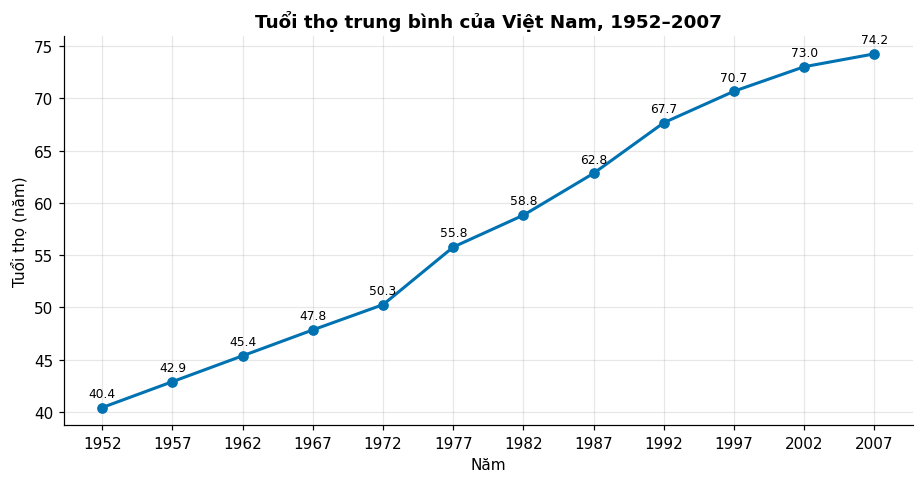

In [12]:
vn = df[df["country"] == "Vietnam"].sort_values("year")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(vn["year"], vn["lifeExp"], marker="o", color=OKABE[4], lw=2)
for y, v in zip(vn["year"], vn["lifeExp"]):
    ax.annotate(f"{v:.1f}", (y, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set(title="Tuổi thọ trung bình của Việt Nam, 1952–2007", xlabel="Năm", ylabel="Tuổi thọ (năm)",
       xticks=vn["year"])
show("2a_line_vietnam")

**Nhận xét / đáp án:** Tuổi thọ Việt Nam tăng liên tục từ 40,4 (1952) lên 74,2 (2007). Với đường/điểm, thông tin nằm ở vị trí và độ dốc nên trục không cần từ 0; với thanh, độ dài là thông tin nên trục phải từ 0.

### 2b) Line graph nhiều nhóm  _(Slide 31)_  — **1.0 điểm**

> Vẽ line graph so sánh tuổi thọ của Vietnam, Thailand, Japan, United States (mỗi quốc gia một mầu, có chú thích).
>
> Yêu cầu: dùng bảng mầu Okabe-Ito, gắn nhãn trực tiếp ở đầu mỗi đường (direct labeling) NGOÀI chú thích, và tính năm đầu tiên mỗi quốc gia vượt ngưỡng 70 tuổi. Khoảng cách tuổi thọ Nhật – Việt Nam thu hẹp từ bao nhiêu xuống bao nhiêu?

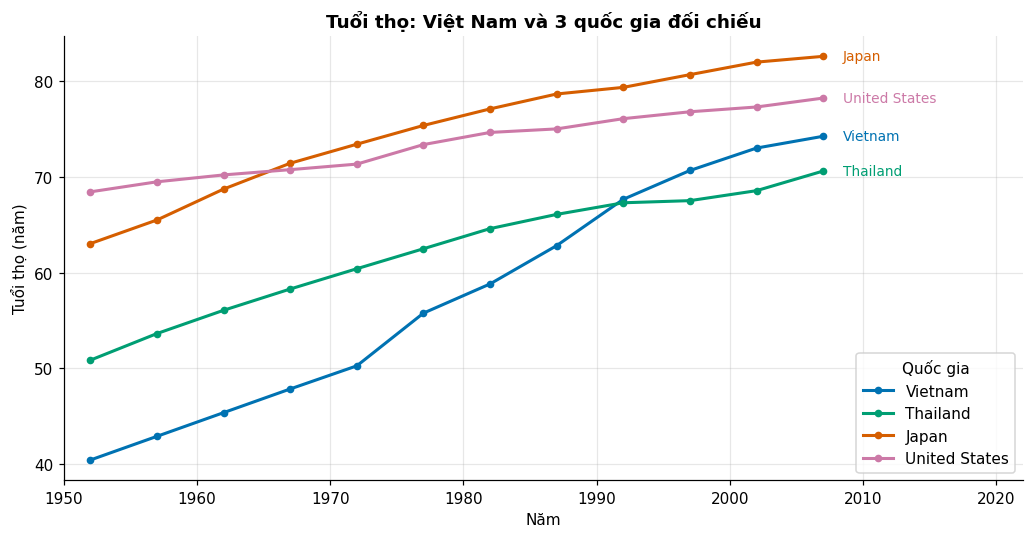

Vietnam        vượt 70 tuổi lần đầu năm: 1997
Thailand       vượt 70 tuổi lần đầu năm: 2007
Japan          vượt 70 tuổi lần đầu năm: 1967
United States  vượt 70 tuổi lần đầu năm: 1962
Khoảng cách Nhật – Việt Nam: 22.6 (1952) -> 8.4 (2007)


In [13]:
cs = ["Vietnam", "Thailand", "Japan", "United States"]
cols = dict(zip(cs, [OKABE[4], OKABE[2], OKABE[5], OKABE[6]]))
fig, ax = plt.subplots(figsize=(9.5, 5))
for c in cs:
    d = df[df["country"] == c].sort_values("year")
    ax.plot(d["year"], d["lifeExp"], marker="o", ms=4, lw=2, color=cols[c], label=c)
    ax.text(2008.5, d["lifeExp"].iloc[-1], c, color=cols[c], va="center", fontsize=9)
ax.set(title="Tuổi thọ: Việt Nam và 3 quốc gia đối chiếu", xlabel="Năm", ylabel="Tuổi thọ (năm)", xlim=(1950, 2022))
ax.legend(title="Quốc gia", loc="lower right")
show("2b_line_4countries")

for c in cs:
    d = df[df["country"] == c]
    hit = d.loc[d["lifeExp"] >= 70, "year"].min()
    print(f"{c:14s} vượt 70 tuổi lần đầu năm:", int(hit) if pd.notna(hit) else "chưa")
gap = (df[df.country == "Japan"].set_index("year")["lifeExp"] - df[df.country == "Vietnam"].set_index("year")["lifeExp"])
print(f"Khoảng cách Nhật – Việt Nam: {gap[1952]:.1f} (1952) -> {gap[2007]:.1f} (2007)")

**Nhận xét / đáp án:** Năm đầu vượt 70: Mỹ 1962, Nhật 1967, Việt Nam 1997, Thái Lan 2007. Khoảng cách Nhật – Việt Nam thu hẹp từ **22,6 xuống 8,4 năm**.

### 2c) Dot plot  _(Slide 29–30)_  — **1.0 điểm**

> Vẽ dot plot tuổi thọ năm 2007 của các quốc gia Đông Nam Á (Vietnam, Thailand, Cambodia, Indonesia, Malaysia, Myanmar, Philippines, Singapore), sắp xếp theo giá trị.
>
> Yêu cầu: dạng Cleveland (đường kẻ ngang nhạt nối từ trục tới chấm), biến phân loại nằm trục tung, trục giá trị cắt hợp lý và có chú thích rõ vì sao được cắt.

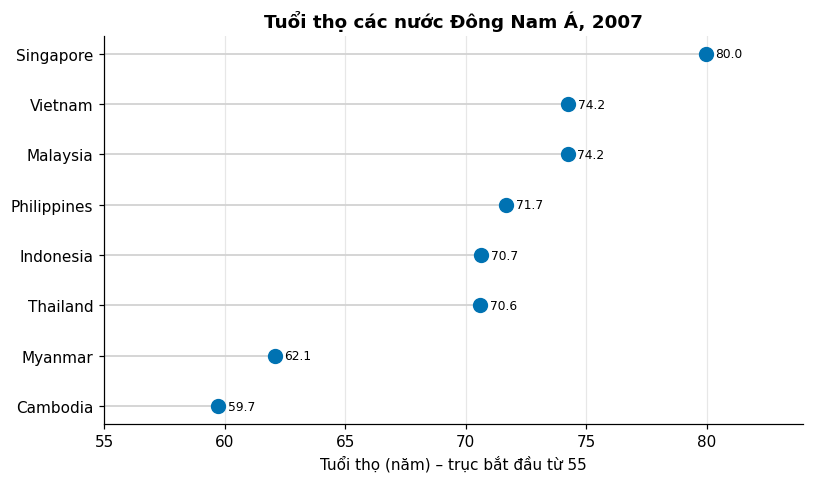

In [14]:
sea = ["Vietnam", "Thailand", "Cambodia", "Indonesia", "Malaysia", "Myanmar", "Philippines", "Singapore"]
d = d07[d07["country"].isin(sea)].sort_values("lifeExp")
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.hlines(d["country"], 55, d["lifeExp"], color="lightgray", lw=1.2)
ax.plot(d["lifeExp"], d["country"], "o", color=OKABE[4], ms=9)
for v, c in zip(d["lifeExp"], d["country"]):
    ax.text(v + .4, c, f"{v:.1f}", va="center", fontsize=8)
ax.set(title="Tuổi thọ các nước Đông Nam Á, 2007", xlabel="Tuổi thọ (năm) – trục bắt đầu từ 55", xlim=(55, 84))
ax.grid(axis="y", alpha=0)
show("2c_dotplot_sea")

**Nhận xét / đáp án:** Singapore (80,0) cao nhất, Myanmar (62,1) và Cambodia (59,7) thấp nhất; Việt Nam 74,2. Xếp theo giá trị giúp đọc thứ hạng ngay. Trục phải cắt dưới 59,7 vì Campuchia nằm dưới 60.

### 2d) Radar chart  `[Nâng cao]`  _(Slide 32, 17–18)_  — **1.0 điểm**

> Vẽ radar chart tuổi thọ của Vietnam, Thailand, Japan, United States với 12 nan hoa là 12 năm quan sát.
>
> Câu hỏi tư duy: radar dựa trên hệ toạ độ cực (slide 17–18) hợp với dữ liệu mang tính chu kỳ. Dữ liệu này có chu kỳ không? Việc đường nối khép kín từ 2007 về 1952 gây hiểu lầm gì? Đề xuất biểu đồ thay thế.

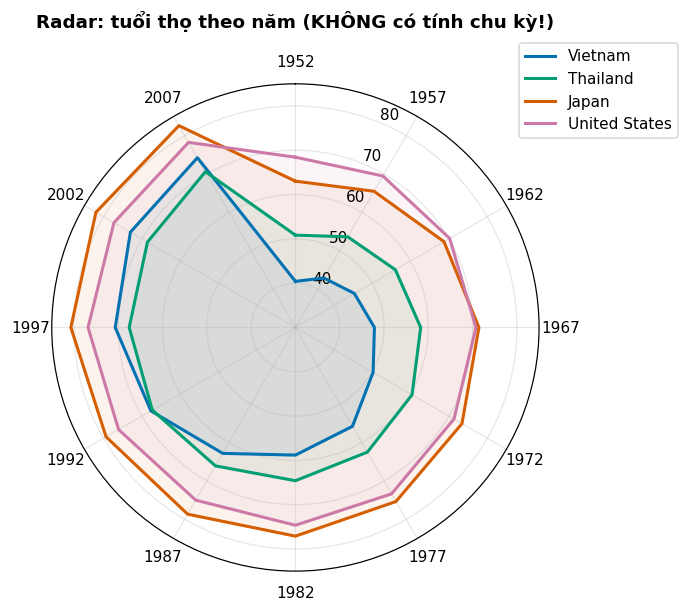

In [15]:
years = sorted(df["year"].unique())
ang = np.linspace(0, 2 * np.pi, len(years), endpoint=False)
fig = plt.figure(figsize=(6.5, 6.5)); ax = plt.subplot(111, polar=True)
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
for c in cs:
    v = df[df["country"] == c].sort_values("year")["lifeExp"].values
    a2, v2 = np.r_[ang, ang[0]], np.r_[v, v[0]]
    ax.plot(a2, v2, lw=2, color=cols[c], label=c); ax.fill(a2, v2, color=cols[c], alpha=.07)
ax.set_xticks(ang); ax.set_xticklabels(years); ax.set_ylim(30, 85)
ax.set_title("Radar: tuổi thọ theo năm (KHÔNG có tính chu kỳ!)", pad=18)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
show("2d_radar")

**Nhận xét / đáp án:** Dữ liệu năm 1952→2007 **không có chu kỳ**; đường khép kín nối 2007 về 1952 tạo quan hệ liền kề không có thật, và bán kính khó so sánh hơn độ dài thẳng. Thay thế: line graph.

### 2e) Area graph và stacked area graph  `[Nâng cao]`  _(Slide 33–34)_  — **1.5 điểm**

> Vẽ area graph dân số Việt Nam (triệu người) theo năm, và stacked area graph dân số 8 nước Đông Nam Á (sắp xếp thứ tự lớp xếp theo dân số 2007).
>
> Câu hỏi tư duy: vì sao trục y của area graph bắt buộc bắt đầu từ 0? Trên stacked area, có đọc chính xác được dân số của lớp nằm giữa không? Vì sao?

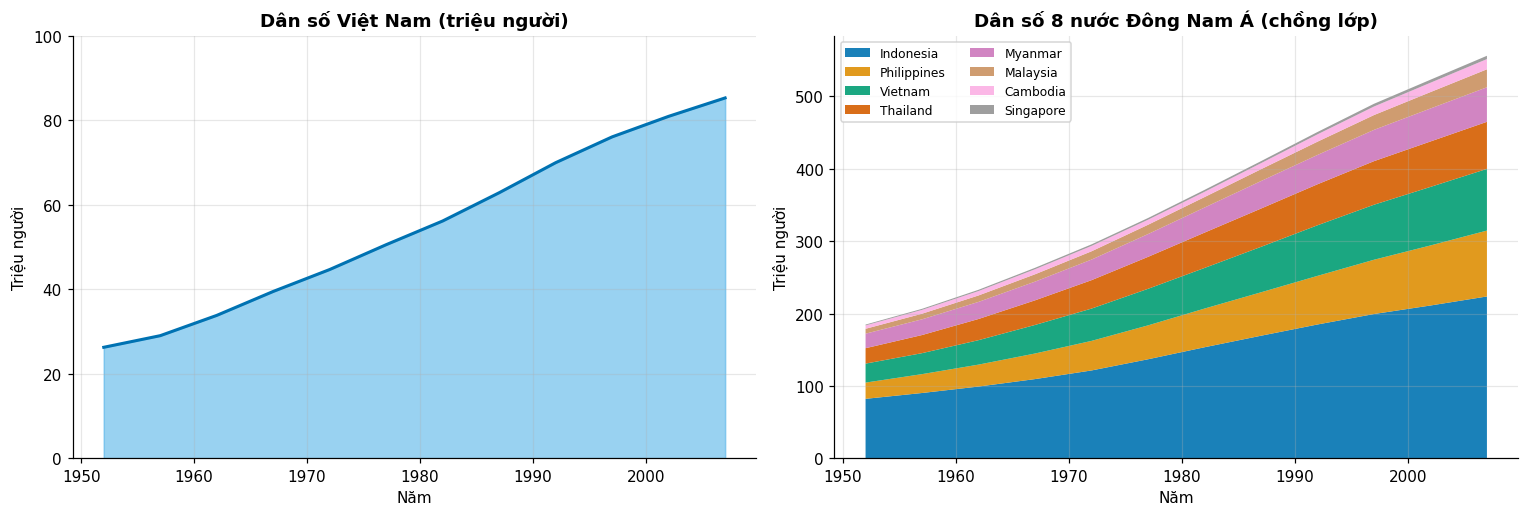

In [16]:
pv = df[df["country"].isin(sea)].pivot(index="year", columns="country", values="pop") / 1e6
pv = pv[pv.iloc[-1].sort_values(ascending=False).index]          # lớp lớn nhất ở đáy
pal8 = sns.color_palette("colorblind", 8)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
axs[0].fill_between(pv.index, pv["Vietnam"], color=OKABE[1], alpha=.6); axs[0].plot(pv.index, pv["Vietnam"], color=OKABE[4], lw=2)
axs[0].set(title="Dân số Việt Nam (triệu người)", ylim=(0, 100), xlabel="Năm", ylabel="Triệu người")
axs[1].stackplot(pv.index, pv.T.values, labels=pv.columns, colors=pal8, alpha=.9)
axs[1].set(title="Dân số 8 nước Đông Nam Á (chồng lớp)", xlabel="Năm", ylabel="Triệu người")
axs[1].legend(loc="upper left", fontsize=8, ncol=2)
show("2e_area_stacked")

**Nhận xét / đáp án:** Area bắt buộc trục từ 0 vì diện tích là thông tin; nếu cắt trục, tỉ lệ diện tích bị bóp méo. Ở stacked area chỉ lớp đáy có đường nền chung; lớp giữa có nền thay đổi nên khó đọc giá trị chính xác.

### 2f) Stream graph (ThemeRiver)  `[Nâng cao]`  _(Slide 35)_  — **1.0 điểm**

> Vẽ stream graph cho cùng dữ liệu dân số 8 nước Đông Nam Á ở câu e (đường nền dao động – baseline 'wiggle').
>
> Câu hỏi tư duy: stream graph khác stacked area ở điểm nào về đường nền? Cái được và cái mất khi dùng stream graph cho dữ liệu chỉ có 12 mốc thời gian?

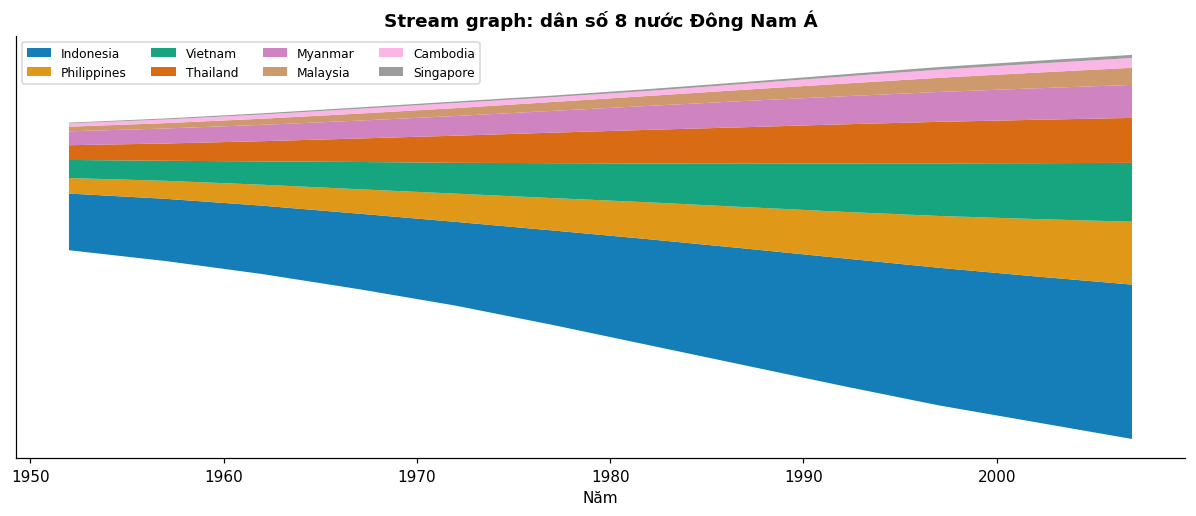

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.stackplot(pv.index, pv.T.values, baseline="wiggle", labels=pv.columns, colors=pal8, alpha=.92)
ax.set(title="Stream graph: dân số 8 nước Đông Nam Á", xlabel="Năm", yticks=[])
ax.legend(loc="upper left", fontsize=8, ncol=4); ax.grid(False)
show("2f_stream")

**Nhận xét / đáp án:** Stream graph dùng đường nền dao động (wiggle) thay vì nền bằng 0, giảm độ dốc tổng thể và nhấn mạnh hình dạng từng lớp; mất khả năng đọc giá trị tuyệt đối. Chỉ 12 mốc thời gian nên đường cong mượt gây cảm giác dữ liệu liên tục.

### 2g) So sánh dot – line – area  `[Nâng cao]`  _(Slide 29–33)_  — **1.5 điểm**

> So sánh trực tiếp: vẽ cạnh nhau dot plot, line graph, area graph (trục từ 0) và area graph (trục bị cắt) cho cùng chuỗi tuổi thọ Việt Nam. Viết 3–4 câu: biểu đồ nào nhấn mạnh 'giá trị', 'xu thế', 'khối lượng'? Biểu đồ nào dễ gây hiểu lầm nhất và vì sao?

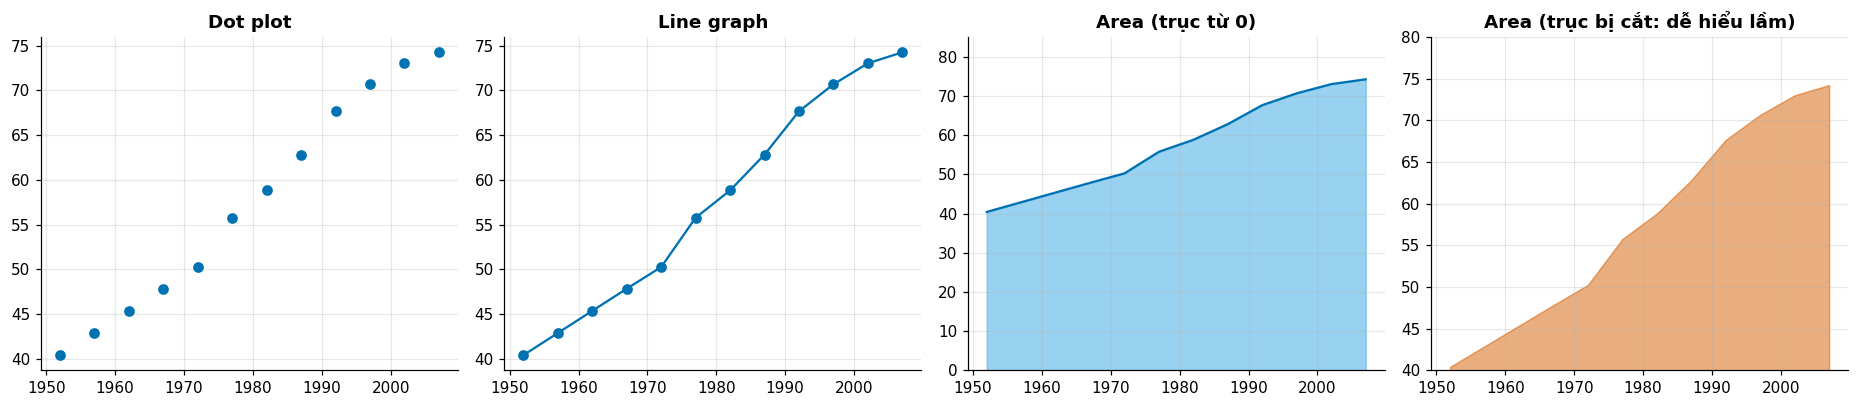

In [18]:
x, y = vn["year"], vn["lifeExp"]
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8), sharex=True)
axs[0].plot(x, y, "o", color=OKABE[4]); axs[0].set_title("Dot plot")
axs[1].plot(x, y, "-o", color=OKABE[4]); axs[1].set_title("Line graph")
axs[2].fill_between(x, y, color=OKABE[1], alpha=.6); axs[2].plot(x, y, color=OKABE[4]); axs[2].set(ylim=(0, 85), title="Area (trục từ 0)")
axs[3].fill_between(x, y, y2=40, color=OKABE[5], alpha=.5); axs[3].set(ylim=(40, 80), title="Area (trục bị cắt: dễ hiểu lầm)")
show("2g_dot_line_area")

**Nhận xét / đáp án:** Dot plot nhấn mạnh giá trị từng mốc; line graph nhấn mạnh xu thế; area nhấn mạnh khối lượng tích luỹ. Area bị cắt trục gây hiểu lầm nhất vì phần diện tích tô không còn tỉ lệ với giá trị.

---
## Câu 3. Bar chart và các biến thể

### 3a) Bar chart  _(Slide 36)_  — **1.0 điểm**

> Vẽ bar chart 10 quốc gia có gdpPercap cao nhất năm 2007.
>
> Yêu cầu: sắp xếp giảm dần, ghi nhãn giá trị trên đầu thanh, trục y bắt đầu từ 0, nhãn trục x xoay không chồng chữ.

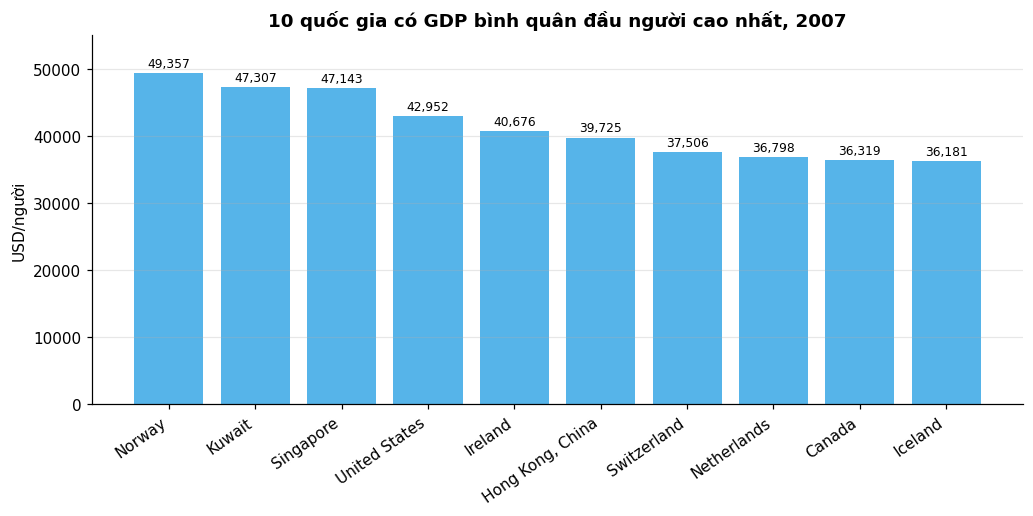

In [19]:
t10 = d07.nlargest(10, "gdpPercap")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.bar(t10["country"], t10["gdpPercap"], color=OKABE[1])
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in t10["gdpPercap"]], fontsize=8, padding=2)
ax.set(title="10 quốc gia có GDP bình quân đầu người cao nhất, 2007", ylabel="USD/người", ylim=(0, 55000))
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
ax.grid(axis="x", alpha=0)
show("3a_bar_top10")

**Nhận xét / đáp án:** Top 10 gdpPercap 2007: Norway (49,357), Kuwait (47,307), Singapore (47,143), United States (42,952), Ireland (40,676), Hong Kong, China (39,725), Switzerland (37,506), Netherlands (36,798), Canada (36,319), Iceland (36,181). Thanh bắt đầu từ 0.

### 3b) Bar chart ngang  _(Slide 37)_  — **1.0 điểm**

> Vẽ lại biểu đồ ở câu a bằng bar chart ngang (hoán đổi trục).
>
> Yêu cầu: quốc gia lớn nhất nằm TRÊN CÙNG (cẩn thận thứ tự trục tung mặc định của matplotlib). Giải thích khi nào nên dùng bar ngang thay bar đứng.

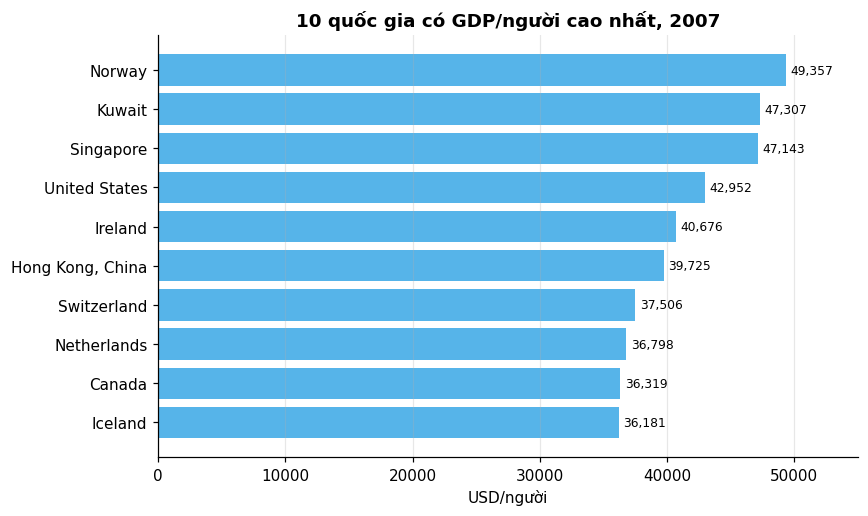

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.8))
b = ax.barh(t10["country"][::-1], t10["gdpPercap"][::-1], color=OKABE[1])
ax.bar_label(b, labels=[f"{v:,.0f}" for v in t10["gdpPercap"][::-1]], fontsize=8, padding=3)
ax.set(title="10 quốc gia có GDP/người cao nhất, 2007", xlabel="USD/người", xlim=(0, 55000))
ax.grid(axis="y", alpha=0)
show("3b_barh_top10")

**Nhận xét / đáp án:** Bar ngang dùng khi nhãn dài hoặc nhiều hạng mục. Trong matplotlib barh vẽ từ dưới lên nên phải đảo thứ tự (`[::-1]`) để lớn nhất ở trên.

### 3c) Grouped bar plot  _(Slide 41)_  — **1.0 điểm**

> Vẽ grouped bar plot tuổi thọ năm 1952 và 2007 của Vietnam, China, India, Japan, Brazil.
>
> Yêu cầu: hai năm dùng hai sắc độ của cùng một mầu (vì sao hợp lý?), ghi giá trị, và tính mức tăng tuyệt đối (năm) của từng nước; nước nào tăng nhiều nhất?

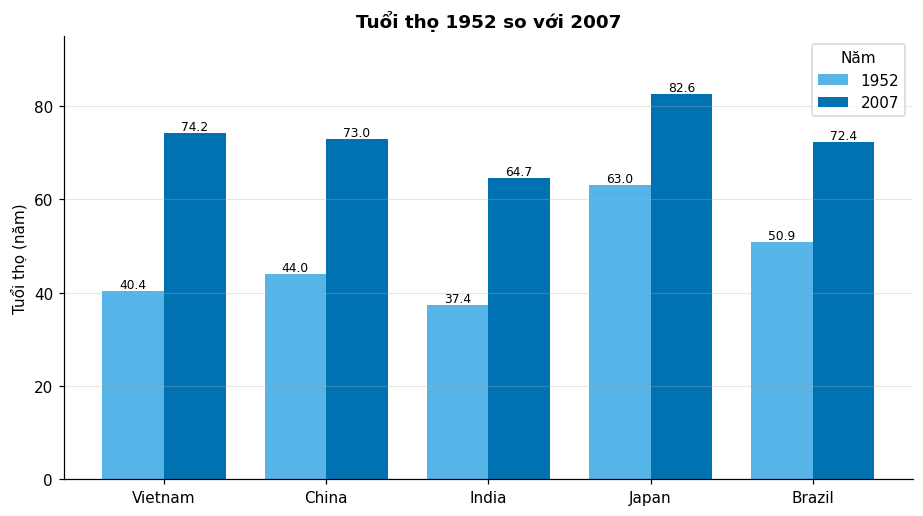

country
Vietnam    33.8
China      29.0
India      27.3
Brazil     21.5
Japan      19.6
dtype: float64


In [21]:
five = ["Vietnam", "China", "India", "Japan", "Brazil"]
g = (df[df["year"].isin([1952, 2007]) & df["country"].isin(five)]
     .pivot(index="country", columns="year", values="lifeExp").loc[five])
x = np.arange(len(five)); w = .38
fig, ax = plt.subplots(figsize=(8.5, 4.8))
b1 = ax.bar(x - w/2, g[1952], w, label="1952", color=OKABE[1])
b2 = ax.bar(x + w/2, g[2007], w, label="2007", color=OKABE[4])
ax.bar_label(b1, fmt="%.1f", fontsize=8); ax.bar_label(b2, fmt="%.1f", fontsize=8)
ax.set(xticks=x, xticklabels=five, ylabel="Tuổi thọ (năm)", ylim=(0, 95), title="Tuổi thọ 1952 so với 2007")
ax.legend(title="Năm"); ax.grid(axis="x", alpha=0)
show("3c_grouped_bar")
print((g[2007] - g[1952]).sort_values(ascending=False).round(1))

**Nhận xét / đáp án:** Mức tăng 1952→2007: Việt Nam **33,8**, Trung Quốc 29,0, Ấn Độ 27,3, Brazil 21,5, Nhật 19,6. Hai sắc độ của cùng một mầu thể hiện cùng một biến (tuổi thọ) ở hai thời điểm.

### 3d) Stacked bar plot  `[Nâng cao]`  _(Slide 42)_  — **1.0 điểm**

> Vẽ stacked bar plot dân số (triệu người) của 5 nước trên tại ba năm 1952, 1977, 2007; vẽ thêm phiên bản chuẩn hoá 100% bên cạnh.
>
> Câu hỏi tư duy: phiên bản nào trả lời câu hỏi 'quy mô tổng' và phiên bản nào trả lời 'cơ cấu'? Lớp nào khó so sánh giữa các cột nhất và vì sao?

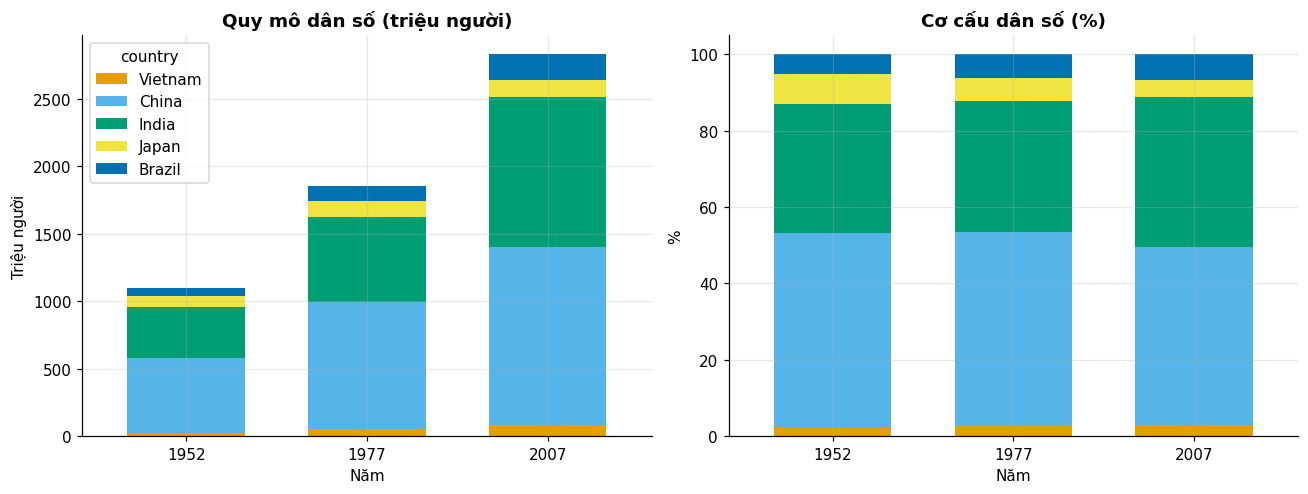

In [22]:
yrs = [1952, 1977, 2007]
p = (df[df["year"].isin(yrs) & df["country"].isin(five)]
     .pivot(index="year", columns="country", values="pop")[five] / 1e6)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
p.plot.bar(stacked=True, ax=axs[0], color=OKABE[:5], rot=0, width=.65)
axs[0].set(title="Quy mô dân số (triệu người)", xlabel="Năm", ylabel="Triệu người")
(p.div(p.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=axs[1], color=OKABE[:5], rot=0, width=.65, legend=False)
axs[1].set(title="Cơ cấu dân số (%)", xlabel="Năm", ylabel="%")
show("3d_stacked_bar")

**Nhận xét / đáp án:** Cột chồng thực tế đọc 'quy mô tổng', bản 100% đọc 'cơ cấu'. Lớp nằm giữa khó so sánh vì không chung đường nền.

### 3e) Grouped bar > 2 biến độc lập  `[Nâng cao]`  _(Slide 43)_  — **1.0 điểm**

> Vẽ grouped bar tuổi thọ của 5 nước tại bốn năm 1952, 1972, 1992, 2007.
>
> Câu hỏi tư duy: slide 43 đặt câu hỏi 'nhiều hơn 2 biến độc lập thì sao?'. Trong biểu đồ này năm là biến có thứ tự — chọn thang mầu nào (phân loại hay tuần tự) và vì sao? Khi nào nên chuyển sang line graph hoặc facet?

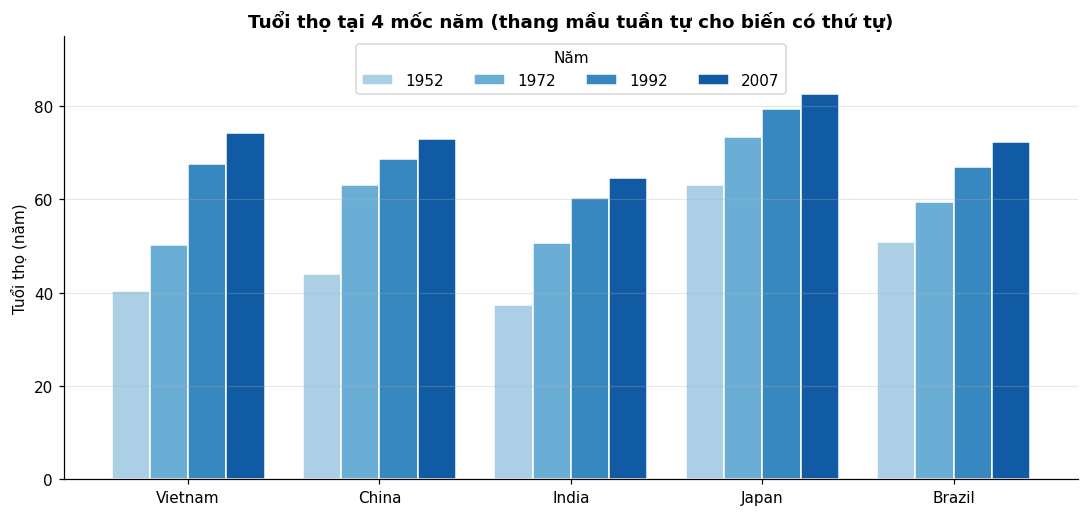

In [23]:
g4 = (df[df["year"].isin([1952, 1972, 1992, 2007]) & df["country"].isin(five)]
      .pivot(index="country", columns="year", values="lifeExp").loc[five])
fig, ax = plt.subplots(figsize=(10, 4.8))
g4.plot.bar(ax=ax, color=sns.color_palette("Blues", 5)[1:], rot=0, width=.8, edgecolor="white")
ax.set(title="Tuổi thọ tại 4 mốc năm (thang mầu tuần tự cho biến có thứ tự)", ylabel="Tuổi thọ (năm)", xlabel="", ylim=(0, 95))
ax.legend(title="Năm", ncol=4, loc="upper center"); ax.grid(axis="x", alpha=0)
show("3e_grouped_4years")

**Nhận xét / đáp án:** Năm là biến có thứ tự nên dùng thang mầu tuần tự. Khi nhiều biến hơn nên chuyển line graph hoặc facet.

### 3f) Radial bar chart  `[Nâng cao]`  _(Slide 38)_  — **1.5 điểm**

> Vẽ radial bar chart tuổi thọ năm 2007 của 8 nước Đông Nam Á (mỗi vòng tròn một nước, góc cung tỉ lệ với giá trị, thang đầy đủ = 90 tuổi).
>
> Câu hỏi tư duy (slide 38 hỏi 'bar chart?'): vì sao thanh ở vòng ngoài trông 'dài' hơn dù cùng giá trị? Liệt kê hai nhược điểm khi đọc giá trị.

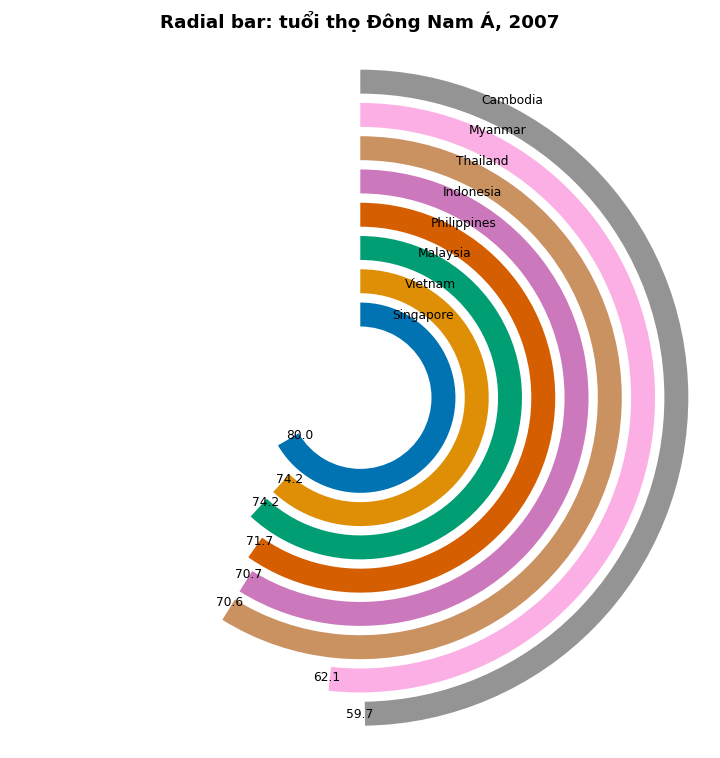

In [24]:
d = d07[d07["country"].isin(sea)].sort_values("lifeExp", ascending=False).reset_index(drop=True)
fig = plt.figure(figsize=(7, 7)); ax = plt.subplot(111, polar=True)
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
theta = d["lifeExp"].values / 90 * 1.5 * np.pi              # 90 tuổi = 3/4 vòng tròn
ax.barh(np.arange(len(d)), theta, height=.72, color=sns.color_palette("colorblind", 8))
for i, (t, v) in enumerate(zip(theta, d["lifeExp"])):
    ax.text(t + .06, i, f"{v:.1f}", va="center", fontsize=8)
ax.set_yticks(np.arange(len(d))); ax.set_yticklabels(d["country"], fontsize=8); ax.set_ylim(-2.5, len(d))
ax.set_xticks([]); ax.grid(False); ax.spines["polar"].set_visible(False)
ax.set_title("Radial bar: tuổi thọ Đông Nam Á, 2007", pad=14)
show("3f_radial_bar")

**Nhận xét / đáp án:** Vòng ngoài có chu vi lớn hơn nên cung cùng góc trông dài hơn; khó đọc giá trị chính xác và khó so sánh giữa các vòng.

### 3g) Radial column chart (star graph)  `[Nâng cao]`  _(Slide 39)_  — **1.5 điểm**

> Vẽ radial column chart (circular column graph) tuổi thọ năm 2007 của 8 nước Đông Nam Á: mỗi nước một nan hoa, bán kính là thang đo của biến phụ thuộc.
>
> Câu hỏi tư duy: với radial column, người đọc cảm nhận 'diện tích cột' hay 'chiều dài cột'? Điều đó làm sai lệch so sánh thế nào khi trục bán kính không bắt đầu từ 0?

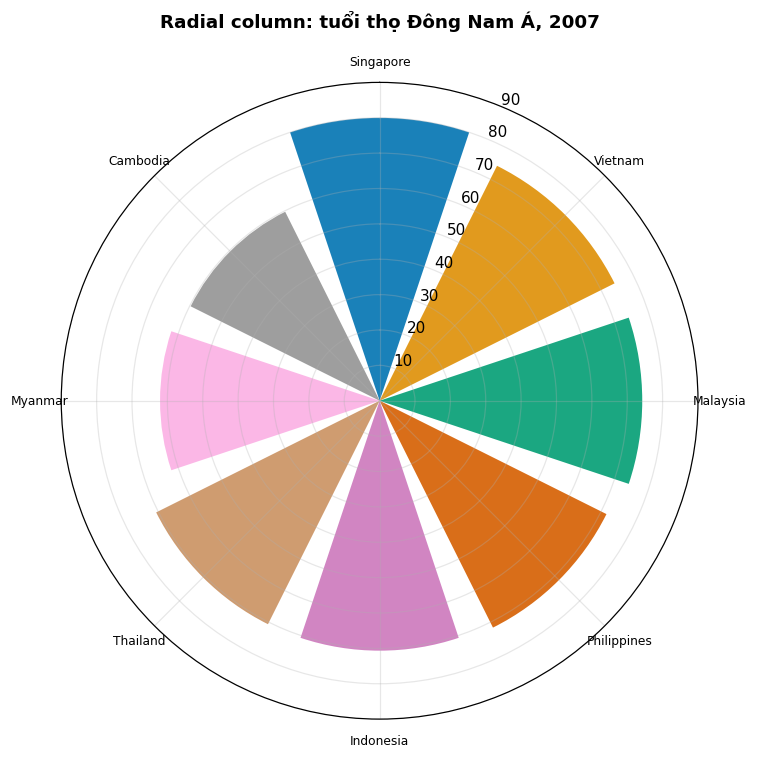

In [25]:
th = np.linspace(0, 2 * np.pi, len(d), endpoint=False)
fig = plt.figure(figsize=(7, 7)); ax = plt.subplot(111, polar=True)
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.bar(th, d["lifeExp"], width=2 * np.pi / len(d) * .82, color=sns.color_palette("colorblind", 8), alpha=.9)
ax.set_xticks(th); ax.set_xticklabels(d["country"], fontsize=8); ax.set_ylim(0, 90)
ax.set_title("Radial column: tuổi thọ Đông Nam Á, 2007", pad=18)
show("3g_radial_column")

**Nhận xét / đáp án:** Người đọc cảm nhận diện tích hình quạt (tăng theo bình phương bán kính) nên khoảng cách giữa các giá trị bị phóng đại, nhất là khi trục không bắt đầu từ 0.

### 3h) Spiral plot (time series spiral)  `[Nâng cao]`  _(Slide 40)_  — **1.5 điểm**

> Vẽ spiral plot tuổi thọ Việt Nam theo thời gian: mỗi vòng xoắn gồm 4 mốc quan sát (20 năm), độ dài cột tỉ lệ với (lifeExp − 30), bán kính nền tăng dần theo từng vòng, mầu theo giá trị.
>
> Câu hỏi tư duy: spiral plot sinh ra cho dữ liệu chuỗi thời gian dài và dày. Với chỉ 12 điểm, nó có đáng dùng không? So sánh với line graph ở Câu 2a.

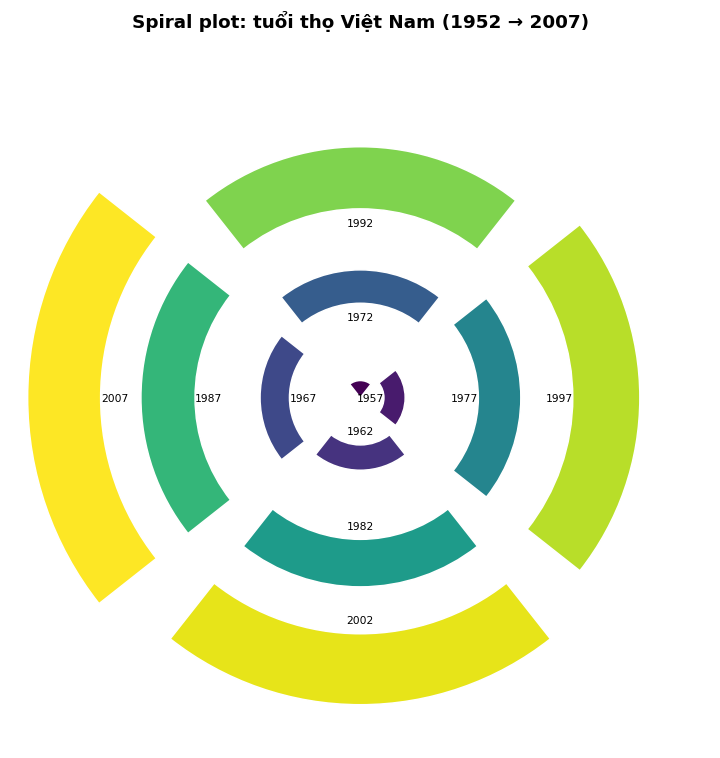

In [26]:
v = vn.reset_index(drop=True); n = len(v); lap = 4
theta = 2 * np.pi * np.arange(n) / lap
r_base = 3 + np.arange(n) / lap * 2.6
norm = mpl.colors.Normalize(v["lifeExp"].min(), v["lifeExp"].max())
fig = plt.figure(figsize=(7, 7)); ax = plt.subplot(111, polar=True)
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.bar(theta, (v["lifeExp"] - 30) / 22, width=2 * np.pi / lap * .85, bottom=r_base,
       color=plt.cm.viridis(norm(v["lifeExp"])), edgecolor="white")
for t, r, y in zip(theta, r_base, v["year"]):
    ax.text(t, r - .38, str(y), ha="center", va="center", fontsize=7)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.spines["polar"].set_visible(False)
ax.set_title("Spiral plot: tuổi thọ Việt Nam (1952 → 2007)", pad=14)
show("3h_spiral")

**Nhận xét / đáp án:** Chỉ 12 điểm nên spiral không có lợi thế; line graph ở 2a đọc nhanh hơn. Spiral hợp chuỗi dài, dày, có chu kỳ.

### 3i) Trục bị cắt: bar vs dot plot  `[Nâng cao]`  _(Slide 30, 36)_  — **1.5 điểm**

> Vẽ ba biểu đồ cạnh nhau cho tuổi thọ 8 nước Đông Nam Á năm 2007: bar ngang trục từ 0, bar ngang trục cắt tại 50, và dot plot trục cắt tại 50. Tính tỉ lệ độ dài thanh Singapore/Cambodia trong thực tế và tỉ lệ nhìn thấy ở biểu đồ cắt trục. Kết luận về quy tắc 'trục từ 0'.

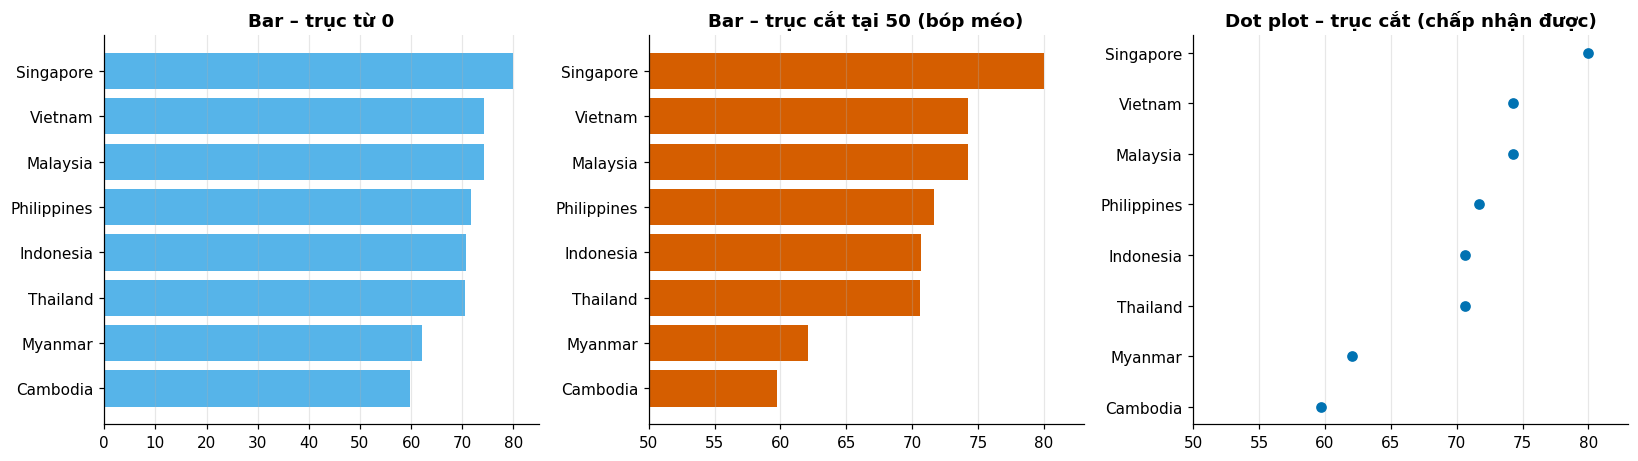

Tỉ lệ thật: 1.34 lần | tỉ lệ độ dài thanh khi cắt trục tại 50: 3.08 lần


In [27]:
dd = d07[d07["country"].isin(sea)].sort_values("lifeExp")
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
axs[0].barh(dd["country"], dd["lifeExp"], color=OKABE[1]); axs[0].set(xlim=(0, 85), title="Bar – trục từ 0")
axs[1].barh(dd["country"], dd["lifeExp"], color=OKABE[5]); axs[1].set(xlim=(50, 83), title="Bar – trục cắt tại 50 (bóp méo)")
axs[2].plot(dd["lifeExp"], dd["country"], "o", color=OKABE[4]); axs[2].set(xlim=(50, 83), title="Dot plot – trục cắt (chấp nhận được)")
for a in axs: a.grid(axis="y", alpha=0)
show("3i_truncated_axis")
sg, cb = dd.set_index("country").loc["Singapore", "lifeExp"], dd.set_index("country").loc["Cambodia", "lifeExp"]
print(f"Tỉ lệ thật: {sg/cb:.2f} lần | tỉ lệ độ dài thanh khi cắt trục tại 50: {(sg-50)/(cb-50):.2f} lần")

**Nhận xét / đáp án:** Singapore/Cambodia thật = **1,34 lần**; khi cắt trục tại 50, chiều dài thanh cho tỉ lệ ≈ 3,1 lần — bóp méo. Thanh cần trục từ 0; dot plot cắt trục chấp nhận được vì thông tin nằm ở vị trí điểm.

---
## Câu 4. Thang đo phi tuyến, scatter plot và bubble chart

### 4a) Scatter plot  _(Slide 75)_  — **1.0 điểm**

> Vẽ scatter plot giữa gdpPercap (trục x) và lifeExp (trục y) năm 2007.
>
> Yêu cầu: chọn biến độc lập/phụ thuộc có lý giải (slide 27), dùng điểm bán trong suốt để giảm chồng lấp, ghi nhãn Vietnam bằng mầu nhấn (accent color – slide 25).

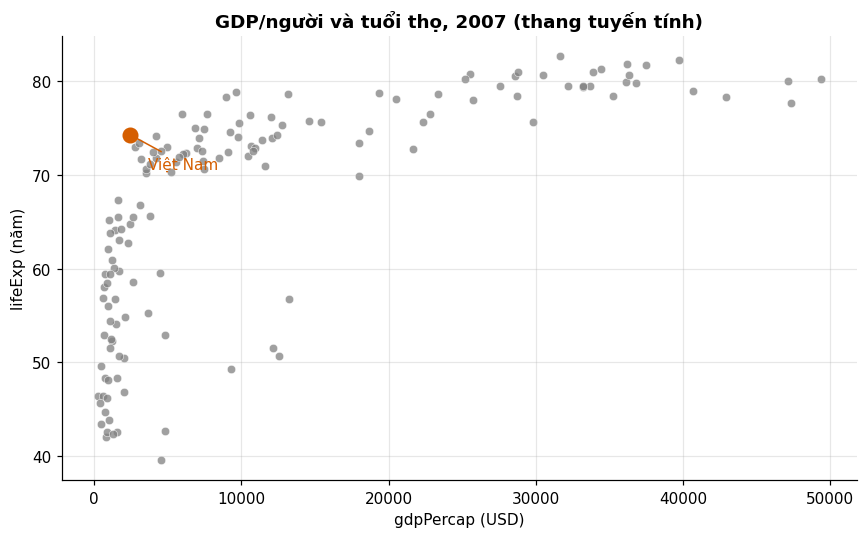

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(d07["gdpPercap"], d07["lifeExp"], s=30, alpha=.75, color="gray", edgecolor="white", lw=.4)
v = d07[d07["country"] == "Vietnam"].iloc[0]
ax.scatter(v["gdpPercap"], v["lifeExp"], s=90, color=OKABE[5], zorder=3)
ax.annotate("Việt Nam", (v["gdpPercap"], v["lifeExp"]), xytext=(12, -22), textcoords="offset points",
            color=OKABE[5], arrowprops=dict(arrowstyle="-", color=OKABE[5]))
ax.set(title="GDP/người và tuổi thọ, 2007 (thang tuyến tính)", xlabel="gdpPercap (USD)", ylabel="lifeExp (năm)")
show("4a_scatter_linear")

**Nhận xét / đáp án:** Quan hệ dương rõ nhưng cong; điểm dồn về bên trái do GDP/người lệch phải mạnh.

### 4b) Thang log  _(Slide 14–16)_  — **1.5 điểm**

> Vẽ lại biểu đồ ở câu a với trục x theo log scale. Nhận xét sự khác biệt.
>
> Yêu cầu: định lượng nhận xét — tính hệ số tương quan Pearson giữa lifeExp với gdpPercap và với log10(gdpPercap), và Spearman của cả hai. Vì sao Spearman không đổi? Nhãn trục log phải hiển thị số thường (không phải 10^x).

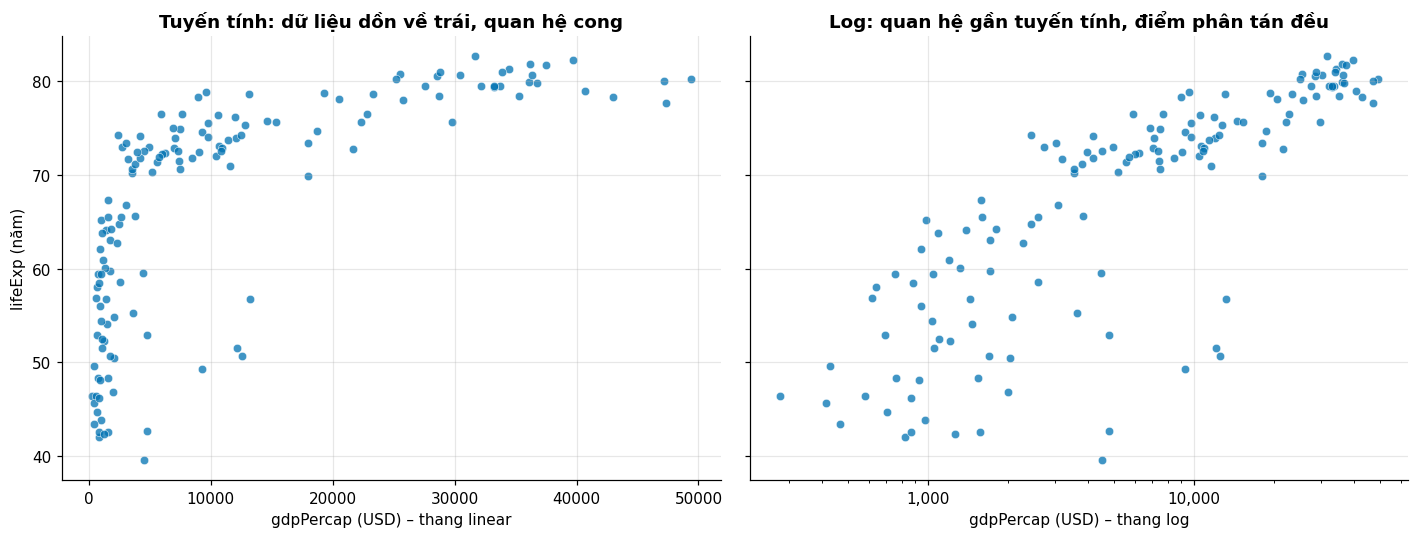

Pearson  (gdpPercap, lifeExp)        : 0.679
Pearson  (log10 gdpPercap, lifeExp)  : 0.809
Spearman (gdpPercap, lifeExp)        : 0.857
Spearman (log10 gdpPercap, lifeExp)  : 0.857


In [29]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, sc in zip(axs, ["linear", "log"]):
    ax.scatter(d07["gdpPercap"], d07["lifeExp"], s=30, alpha=.75, color=OKABE[4], edgecolor="white", lw=.4)
    ax.set_xscale(sc); ax.set_xlabel(f"gdpPercap (USD) – thang {sc}")
    if sc == "log":
        ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axs[0].set_ylabel("lifeExp (năm)"); axs[0].set_title("Tuyến tính: dữ liệu dồn về trái, quan hệ cong")
axs[1].set_title("Log: quan hệ gần tuyến tính, điểm phân tán đều")
show("4b_scatter_log")

x, y = d07["gdpPercap"], d07["lifeExp"]
print("Pearson  (gdpPercap, lifeExp)        :", round(np.corrcoef(x, y)[0, 1], 3))
print("Pearson  (log10 gdpPercap, lifeExp)  :", round(np.corrcoef(np.log10(x), y)[0, 1], 3))
print("Spearman (gdpPercap, lifeExp)        :", round(stats.spearmanr(x, y)[0], 3))
print("Spearman (log10 gdpPercap, lifeExp)  :", round(stats.spearmanr(np.log10(x), y)[0], 3))

**Nhận xét / đáp án:** Thang log trải đều các điểm và làm quan hệ gần tuyến tính. Pearson tăng từ **0,679 lên 0,809** khi dùng log; Spearman **0,857 không đổi** vì chỉ phụ thuộc thứ hạng, bất biến với phép biến đổi đơn điệu.

### 4c) Bubble chart  _(Slide 77)_  — **1.5 điểm**

> Vẽ bubble chart cho năm 2007: kích thước bong bóng theo pop, mầu theo lifeExp.
>
> Yêu cầu: diện tích (không phải bán kính) bong bóng tỉ lệ với pop, có chú giải kích thước và thanh mầu, trục x log, ghi nhãn 5 nước đông dân nhất. Phản biện: ở biểu đồ này mầu theo lifeExp trùng với trục y — đó là dư thừa hay hợp lý?

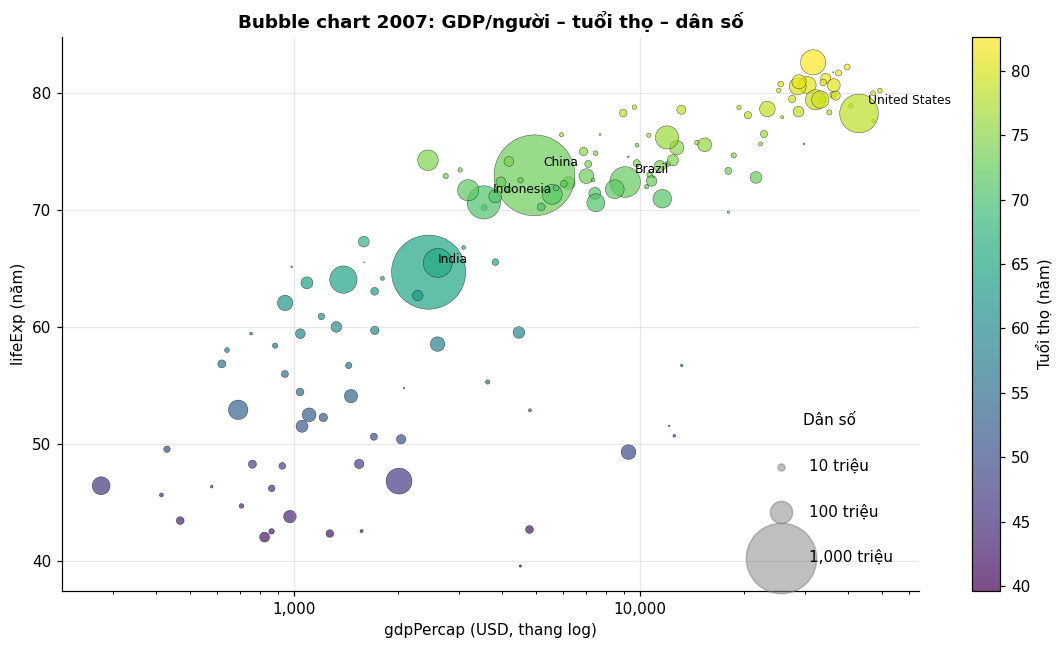

In [30]:
S = 2800 / d07["pop"].max()
fig, ax = plt.subplots(figsize=(10.5, 6))
sc = ax.scatter(d07["gdpPercap"], d07["lifeExp"], s=d07["pop"] * S, c=d07["lifeExp"], cmap="viridis",
                alpha=.7, edgecolor="k", lw=.3)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.colorbar(sc, ax=ax, label="Tuổi thọ (năm)")
for p in [1e7, 1e8, 1e9]:
    ax.scatter([], [], s=p * S, c="gray", alpha=.5, label=f"{p/1e6:,.0f} triệu")
ax.legend(title="Dân số", labelspacing=2, loc="lower right", frameon=False, borderpad=1.2)
for _, r in d07.nlargest(5, "pop").iterrows():
    ax.annotate(r["country"], (r["gdpPercap"], r["lifeExp"]), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set(title="Bubble chart 2007: GDP/người – tuổi thọ – dân số", xlabel="gdpPercap (USD, thang log)", ylabel="lifeExp (năm)")
show("4c_bubble")

**Nhận xét / đáp án:** Màu theo lifeExp trùng với trục y nên là mã hoá dư thừa (chỉ hữu ích để nhấn mạnh/đọc nhanh). Nên dùng màu cho biến thứ tư (nhóm thu nhập) như 4f.

### 4d) Square-root scale  `[Nâng cao]`  _(Slide 14)_  — **1.0 điểm**

> Vẽ cùng scatter ở câu a trên ba thang đo trục x: tuyến tính, log và căn bậc hai (square-root). Thang nào xử lý được giá trị bằng 0 và thang nào không? Với dữ liệu nào thì chọn căn bậc hai thay vì log?

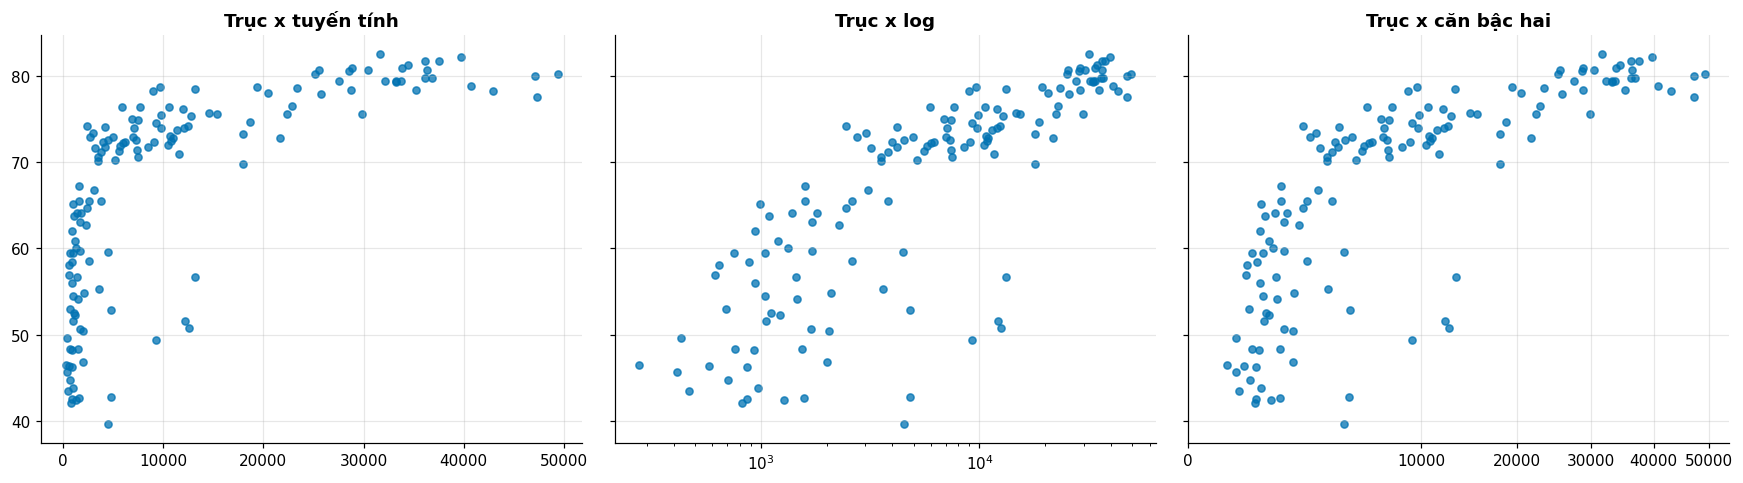

In [31]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (name, sc) in zip(axs, [("tuyến tính", "linear"), ("log", "log"), ("căn bậc hai", "sqrt")]):
    ax.scatter(d07["gdpPercap"], d07["lifeExp"], s=22, alpha=.75, color=OKABE[4])
    if sc == "sqrt":
        ax.set_xscale("function", functions=(np.sqrt, np.square)); ax.set_xlim(left=0)
    else:
        ax.set_xscale(sc)
    ax.set_title(f"Trục x {name}")
show("4d_scales")

**Nhận xét / đáp án:** Log và căn bậc hai đều giảm lệch; log không xử lý được giá trị 0, căn bậc hai thì xử lý được. Căn bậc hai hợp dữ liệu đếm/diện tích có thể bằng 0.

### 4e) Scatter có phân nhóm  `[Nâng cao]`  _(Slide 76, 21–22)_  — **1.0 điểm**

> Vẽ scatter plot (năm 2007, trục x log) có phân nhóm theo tier bằng CẢ mầu và hình dạng điểm. Vì sao dùng đồng thời hai kênh mã hoá là tốt cho người đọc mù mầu hoặc in đen trắng?

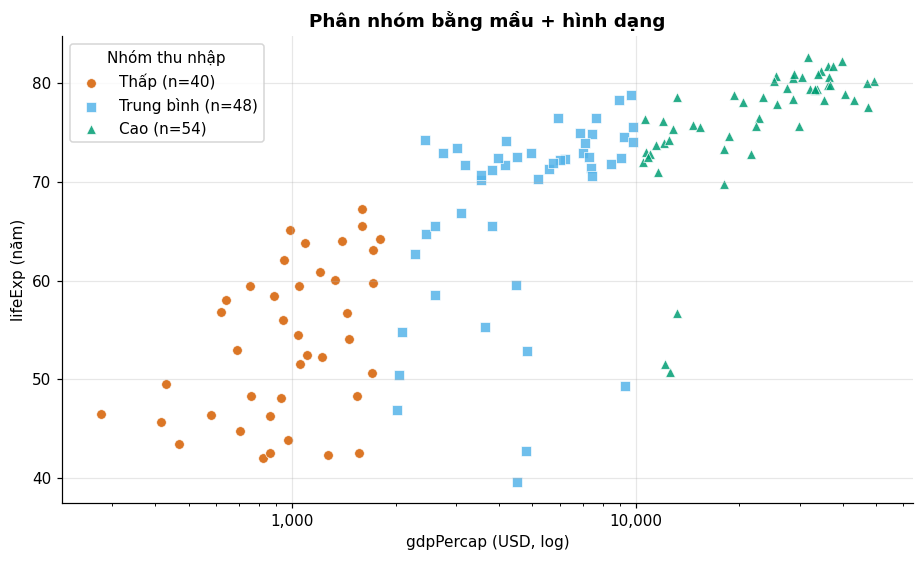

In [32]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for t, m in zip(TIERS, ["o", "s", "^"]):
    s_ = d07[d07["tier"] == t]
    ax.scatter(s_["gdpPercap"], s_["lifeExp"], marker=m, s=40, alpha=.85, color=TIER_COL[t],
               edgecolor="white", lw=.5, label=f"{t} (n={len(s_)})")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set(title="Phân nhóm bằng mầu + hình dạng", xlabel="gdpPercap (USD, log)", ylabel="lifeExp (năm)")
ax.legend(title="Nhóm thu nhập")
show("4e_scatter_groups")

**Nhận xét / đáp án:** Mã hoá đồng thời mầu và hình giúp người mù mầu và bản in đen trắng vẫn phân biệt các nhóm.

### 4f) Bubble chart k > 2 biến  `[Nâng cao]`  _(Slide 77)_  — **1.5 điểm**

> Vẽ bubble chart 2007 với bốn biến cùng lúc: x = gdpPercap (log), y = lifeExp, kích thước = pop, mầu = tier (phân loại). So sánh với Câu 4c: thiết kế nào truyền tải được nhiều thông tin mới hơn? Mỗi kênh mã hoá (vị trí, kích thước, mầu) đang đóng vai trò gì?

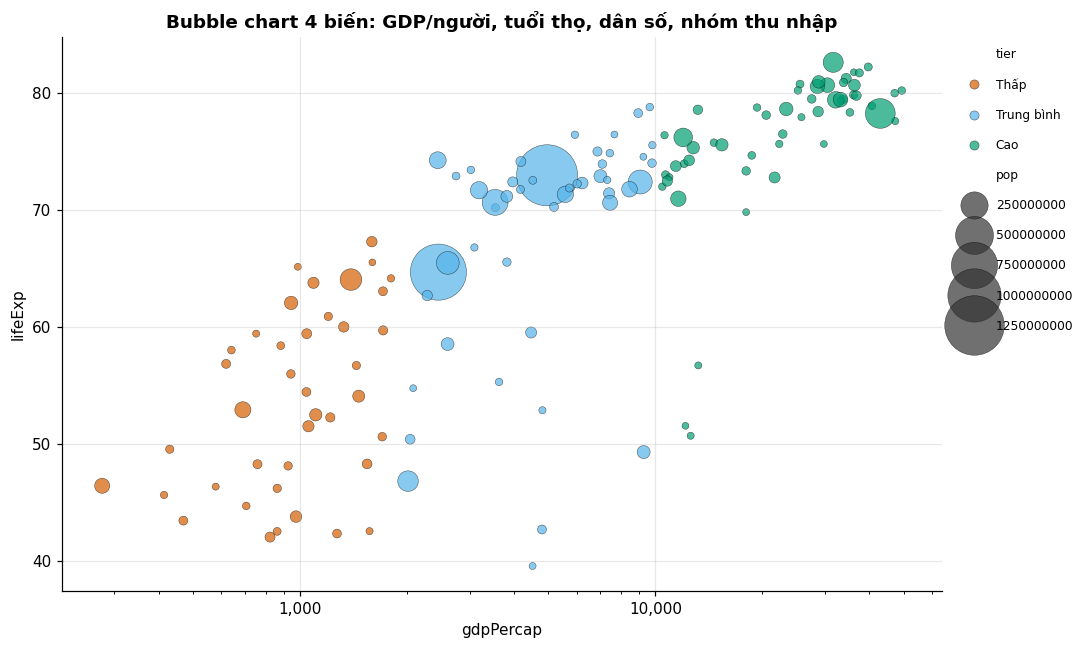

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=d07, x="gdpPercap", y="lifeExp", size="pop", hue="tier", hue_order=TIERS,
                palette=TIER_COL, sizes=(20, 1600), alpha=.7, edgecolor="k", linewidth=.3, ax=ax, legend="brief")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, labelspacing=1.4, fontsize=8)
ax.set(title="Bubble chart 4 biến: GDP/người, tuổi thọ, dân số, nhóm thu nhập")
show("4f_bubble_groups")

**Nhận xét / đáp án:** Thêm tier (mầu) cho thông tin mới: nhóm thu nhập thấp tách biệt ở góc dưới-trái. Vị trí = GDP & tuổi thọ, kích thước = dân số, mầu = nhóm thu nhập.

### 4g) Connected scatter plot  `[Nâng cao]`  _(Slide 83)_  — **1.5 điểm**

> Vẽ connected scatter plot gdpPercap (log) – lifeExp cho Vietnam, China, United States qua 12 năm; gắn nhãn năm 1952, 1977, 2007.
>
> Câu hỏi tư duy: thứ tự nối điểm ở đây là thời gian. Quỹ đạo nói điều gì mà hai line graph riêng rẽ (gdp theo năm, lifeExp theo năm) không nói được? Có nước nào đi 'lùi' không?

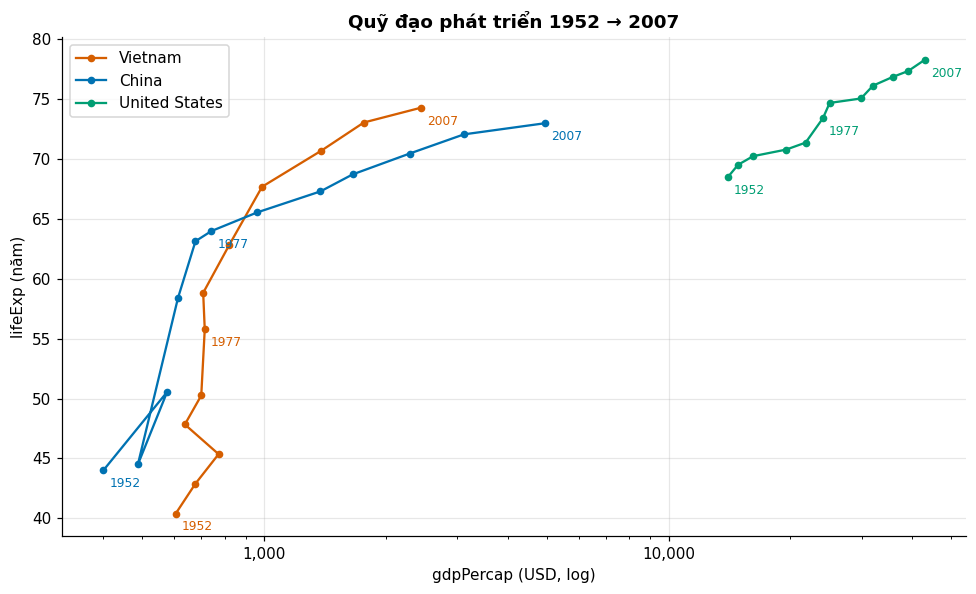

In [34]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for c, col in zip(["Vietnam", "China", "United States"], [OKABE[5], OKABE[4], OKABE[2]]):
    dd_ = df[df["country"] == c].sort_values("year")
    ax.plot(dd_["gdpPercap"], dd_["lifeExp"], "-o", ms=4, color=col, label=c)
    for y_ in [1952, 1977, 2007]:
        r = dd_[dd_["year"] == y_].iloc[0]
        ax.annotate(str(y_), (r["gdpPercap"], r["lifeExp"]), xytext=(4, -11), textcoords="offset points", fontsize=8, color=col)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set(title="Quỹ đạo phát triển 1952 → 2007", xlabel="gdpPercap (USD, log)", ylabel="lifeExp (năm)"); ax.legend()
show("4g_connected_scatter")

**Nhận xét / đáp án:** Quỹ đạo cho thấy hai biến cùng tiến theo thời gian, nhưng tốc độ khác nhau giữa các nước; quan sát độ dốc từng đoạn để thấy giai đoạn tuổi thọ tăng nhanh hơn thu nhập. Kiểm tra bằng số liệu từng nước trước khi kết luận.

### 4h) Confidence band  `[Nâng cao]`  _(Slide 79)_  — **1.5 điểm**

> Tự cài đặt hồi quy OLS lifeExp ~ log10(gdpPercap) năm 2007 (chỉ dùng numpy, KHÔNG dùng seaborn/statsmodels) và vẽ đường hồi quy kèm dải tin cậy 95% của giá trị trung bình.
>
> Hỏi thêm: bao nhiêu % điểm dữ liệu nằm trong dải tin cậy? Vì sao con số đó KHÔNG cần xấp xỉ 95%?

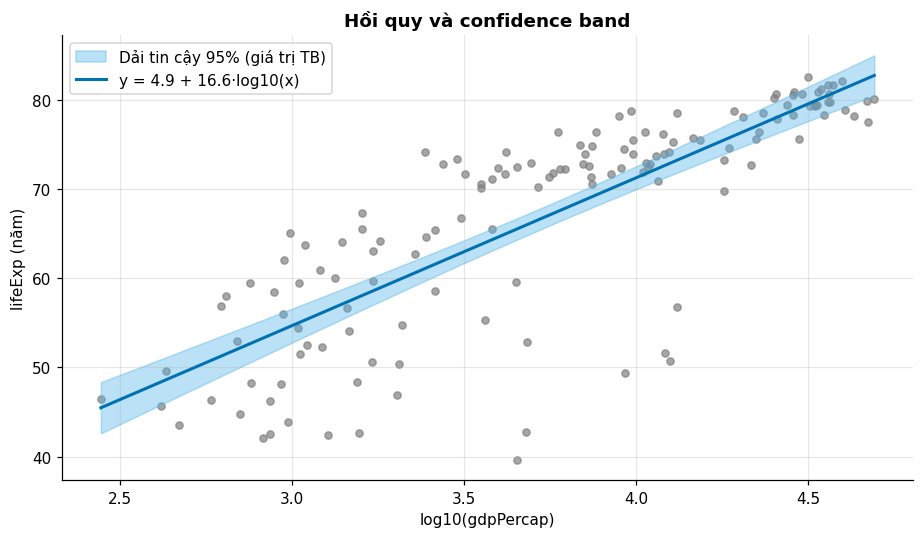

R² = 0.654 | % điểm nằm trong dải tin cậy: 26.1%


In [35]:
def ols(xv, yv, xs):
    n = len(xv); X = np.c_[np.ones(n), xv]
    b = np.linalg.lstsq(X, yv, rcond=None)[0]
    res = yv - X @ b; s = np.sqrt(res @ res / (n - 2)); sxx = ((xv - xv.mean()) ** 2).sum()
    yhat = b[0] + b[1] * xs
    se_mean = s * np.sqrt(1 / n + (xs - xv.mean()) ** 2 / sxx)
    se_pred = s * np.sqrt(1 + 1 / n + (xs - xv.mean()) ** 2 / sxx)
    return b, n, yhat, se_mean, se_pred

lx, ly = np.log10(d07["gdpPercap"].values), d07["lifeExp"].values
xs = np.linspace(lx.min(), lx.max(), 200)
b, n, yhat, se_mean, se_pred = ols(lx, ly, xs)
tcrit = stats.t.ppf(.975, n - 2)
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(lx, ly, s=22, color="gray", alpha=.7)
ax.fill_between(xs, yhat - tcrit * se_mean, yhat + tcrit * se_mean, color=OKABE[1], alpha=.4, label="Dải tin cậy 95% (giá trị TB)")
ax.plot(xs, yhat, color=OKABE[4], lw=2, label=f"y = {b[0]:.1f} + {b[1]:.1f}·log10(x)")
ax.set(title="Hồi quy và confidence band", xlabel="log10(gdpPercap)", ylabel="lifeExp (năm)"); ax.legend()
show("4h_confidence_band")
inside = np.mean(np.abs(ly - (b[0] + b[1] * lx)) <= tcrit * np.interp(lx, xs, se_mean))
print(f"R² = {np.corrcoef(lx, ly)[0,1]**2:.3f} | % điểm nằm trong dải tin cậy: {inside:.1%}")

**Nhận xét / đáp án:** R² = 0,654. Chỉ **26,1%** điểm nằm trong dải tin cậy 95% vì dải này mô tả độ bất định của đường trung bình, không phải của từng quan sát — không cần ≈ 95%.

### 4i) Graded confidence band + prediction band  `[Nâng cao]`  _(Slide 80)_  — **1.5 điểm**

> Vẽ graded confidence band (80%, 95%, 99%) cho đường hồi quy ở câu h, và vẽ thêm dải DỰ BÁO 95% (prediction band). Tính % điểm dữ liệu nằm trong dải dự báo 95%.
>
> Câu hỏi tư duy: dải tin cậy và dải dự báo khác nhau về câu hỏi thống kê mà chúng trả lời; vì sao dải dự báo rộng hơn rất nhiều và gần như không co lại ở giữa?

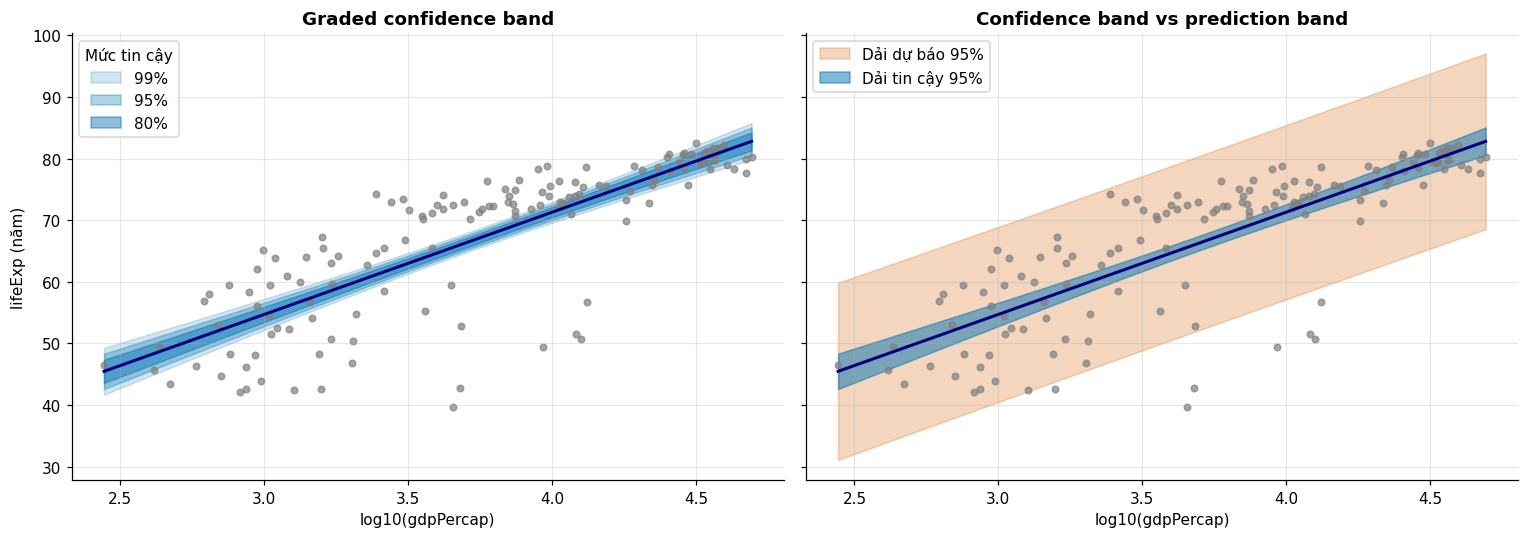

% điểm nằm trong dải dự báo 95%: 95.1%


In [36]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for lv, al in zip([.99, .95, .80], [.18, .3, .45]):
    t = stats.t.ppf((1 + lv) / 2, n - 2)
    axs[0].fill_between(xs, yhat - t * se_mean, yhat + t * se_mean, color=OKABE[4], alpha=al, label=f"{int(lv*100)}%")
axs[0].plot(xs, yhat, color="navy", lw=2); axs[0].scatter(lx, ly, s=18, color="gray", alpha=.7)
axs[0].set(title="Graded confidence band", xlabel="log10(gdpPercap)", ylabel="lifeExp (năm)"); axs[0].legend(title="Mức tin cậy")
tp = stats.t.ppf(.975, n - 2)
axs[1].fill_between(xs, yhat - tp * se_pred, yhat + tp * se_pred, color=OKABE[5], alpha=.25, label="Dải dự báo 95%")
axs[1].fill_between(xs, yhat - tp * se_mean, yhat + tp * se_mean, color=OKABE[4], alpha=.5, label="Dải tin cậy 95%")
axs[1].plot(xs, yhat, color="navy", lw=2); axs[1].scatter(lx, ly, s=18, color="gray", alpha=.7)
axs[1].set(title="Confidence band vs prediction band", xlabel="log10(gdpPercap)"); axs[1].legend()
show("4i_graded_band")
inside_p = np.mean(np.abs(ly - (b[0] + b[1] * lx)) <= tp * np.interp(lx, xs, se_pred))
print(f"% điểm nằm trong dải dự báo 95%: {inside_p:.1%}")

**Nhận xét / đáp án:** Dải dự báo 95% chứa **95,1%** điểm. Dải dự báo rộng hơn vì cộng thêm phương sai của sai số từng quan sát (σ²), phần này không co lại khi n lớn.

---
## Câu 5. Phân phối dữ liệu

### 5a) Histogram  _(Slide 44)_  — **1.0 điểm**

> Vẽ histogram tuổi thọ năm 2007.
>
> Yêu cầu: vẽ ba phiên bản với số bin khác nhau (5 bin, quy tắc Freedman–Diaconis, 30 bin); đánh dấu trung bình và trung vị; tính độ lệch (skewness). Hình dạng phân phối cho em biết gì và bin nào gây hiểu sai?

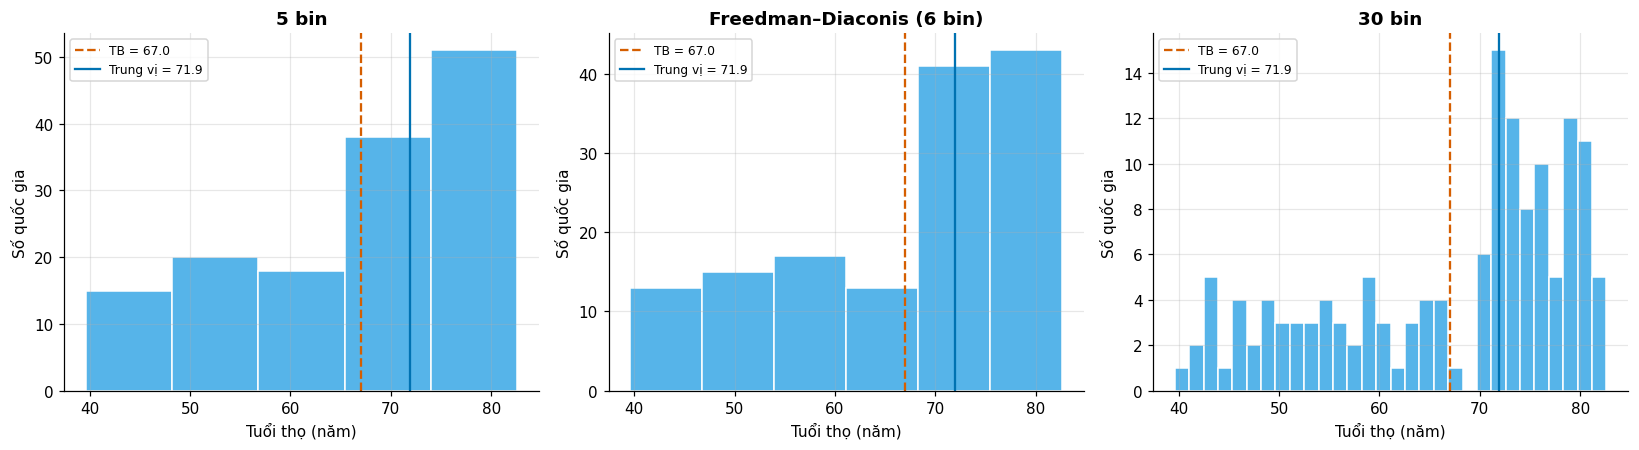

Skewness: -0.681 | trung bình < trung vị -> lệch trái


In [37]:
x = d07["lifeExp"]
bins = {"5 bin": 5, f"Freedman–Diaconis ({len(np.histogram_bin_edges(x, 'fd')) - 1} bin)": np.histogram_bin_edges(x, "fd"), "30 bin": 30}
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
for ax, (t, b) in zip(axs, bins.items()):
    ax.hist(x, bins=b, color=OKABE[1], edgecolor="white")
    ax.axvline(x.mean(), color=OKABE[5], ls="--", label=f"TB = {x.mean():.1f}")
    ax.axvline(x.median(), color=OKABE[4], ls="-", label=f"Trung vị = {x.median():.1f}")
    ax.set(title=t, xlabel="Tuổi thọ (năm)", ylabel="Số quốc gia"); ax.legend(fontsize=8)
show("5a_histogram")
print("Skewness:", round(stats.skew(x), 3), "| trung bình < trung vị -> lệch trái")

**Nhận xét / đáp án:** Phân phối lệch trái (skewness −0,68), trung bình < trung vị, có hai khối (nhóm <60 và nhóm >70). Quá ít bin che mất hai khối; quá nhiều bin gây nhiễu.

### 5b) Density plot  _(Slide 56)_  — **1.0 điểm**

> Vẽ density plot so sánh phân phối tuổi thọ năm 1952 và năm 2007.
>
> Yêu cầu: tìm (các) mode của từng năm từ ước lượng KDE; thử ba băng thông (bw_adjust = 0.5, 1, 2) cho năm 2007 và nói băng thông ảnh hưởng thế nào tới kết luận về số mode.

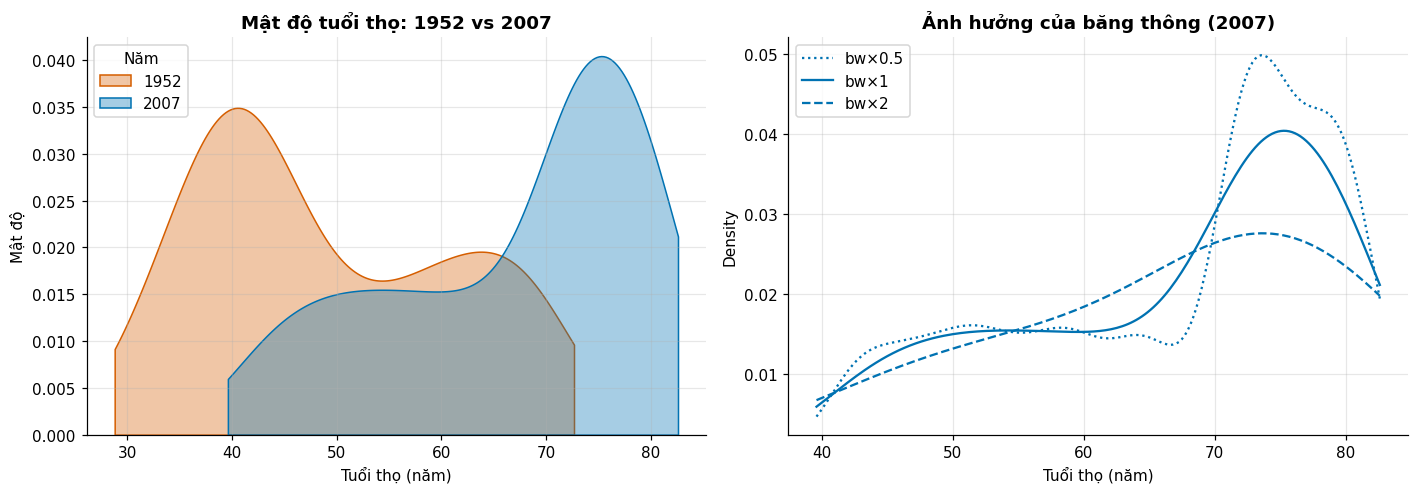

1952 -> các mode (đỉnh KDE) tại: [np.float64(40.6), np.float64(63.8)]
2007 -> các mode (đỉnh KDE) tại: [np.float64(54.4), np.float64(75.3)]


In [38]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for y_, col in [(1952, OKABE[5]), (2007, OKABE[4])]:
    sns.kdeplot(df[df["year"] == y_]["lifeExp"], fill=True, alpha=.35, color=col, label=str(y_), ax=axs[0], cut=0)
axs[0].set(title="Mật độ tuổi thọ: 1952 vs 2007", xlabel="Tuổi thọ (năm)", ylabel="Mật độ"); axs[0].legend(title="Năm")
for bw, ls in zip([.5, 1, 2], [":", "-", "--"]):
    sns.kdeplot(x, bw_adjust=bw, ls=ls, color=OKABE[4], label=f"bw×{bw}", ax=axs[1], cut=0)
axs[1].set(title="Ảnh hưởng của băng thông (2007)", xlabel="Tuổi thọ (năm)"); axs[1].legend()
show("5b_density")
grid = np.linspace(20, 90, 600)
for y_ in [1952, 2007]:
    dens = stats.gaussian_kde(df[df["year"] == y_]["lifeExp"])(grid)
    pk = [grid[i] for i in range(1, len(grid) - 1) if dens[i] > dens[i - 1] and dens[i] > dens[i + 1]]
    print(y_, "-> các mode (đỉnh KDE) tại:", [round(p, 1) for p in pk])

**Nhận xét / đáp án:** KDE 1952 có hai đỉnh (~40,6 và ~63,8); 2007 cũng hai đỉnh (~54,4 và ~75,3): cả phân phối dịch sang phải. Băng thông nhỏ tạo nhiều đỉnh giả, băng thông lớn xoá đỉnh thật.

### 5c) Boxplot  _(Slide 72–74)_  — **1.5 điểm**

> Vẽ boxplot tuổi thọ theo từng năm. Tính Q1, median, Q3 và IQR của năm 2007.
>
> Yêu cầu: tính tay hàng rào Tukey (Q1 − 1,5·IQR, Q3 + 1,5·IQR), liệt kê outlier năm 2007 (nếu có) và đối chiếu với matplotlib.cbook.boxplot_stats. Có outlier không? Vì sao phân phối lệch trái vẫn có thể không có outlier theo quy tắc 1,5·IQR?

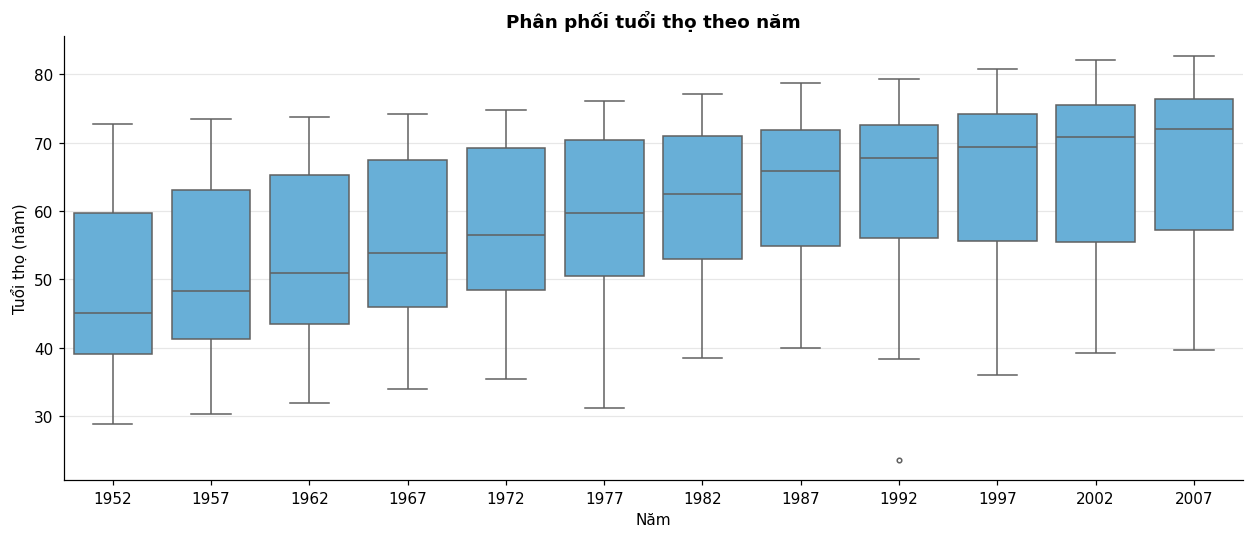

Q1=57.16 | median=71.94 | Q3=76.41 | IQR=19.25
Hàng rào: [28.28, 105.29] | min=39.6, max=82.6
Outlier năm 2007: không có
Đối chiếu matplotlib: {'q1': np.float64(57.16), 'med': np.float64(71.94), 'q3': np.float64(76.41), 'whislo': np.float64(39.61), 'whishi': np.float64(82.6)}


In [39]:
fig, ax = plt.subplots(figsize=(11.5, 5))
sns.boxplot(data=df, x="year", y="lifeExp", color=OKABE[1], fliersize=3, linewidth=1, ax=ax)
ax.set(title="Phân phối tuổi thọ theo năm", xlabel="Năm", ylabel="Tuổi thọ (năm)")
show("5c_boxplot_years")

q1, med, q3 = np.percentile(x, [25, 50, 75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1={q1:.2f} | median={med:.2f} | Q3={q3:.2f} | IQR={iqr:.2f}")
print(f"Hàng rào: [{lo:.2f}, {hi:.2f}] | min={x.min():.1f}, max={x.max():.1f}")
out = d07[(x < lo) | (x > hi)]
print("Outlier năm 2007:", out[["country", "lifeExp"]].values.tolist() or "không có")
st = mpl.cbook.boxplot_stats(x)[0]
print("Đối chiếu matplotlib:", {k: round(st[k], 2) for k in ["q1", "med", "q3", "whislo", "whishi"]})

**Nhận xét / đáp án:** Q1 = 57,16; median = 71,94; Q3 = 76,41; IQR = 19,25. Hàng rào [28,28; 105,29] nên **không có outlier** (min 39,6). IQR rất rộng và đuôi trái dài nhưng vẫn nằm trong hàng rào 1,5·IQR.

### 5d) Stacked density plot  `[Nâng cao]`  _(Slide 57)_  — **1.0 điểm**

> Vẽ stacked density plot tuổi thọ 2007 xếp chồng theo nhóm thu nhập (tier). Diện tích mỗi lớp phản ánh điều gì khi common_norm=True? Chỉ ra hạn chế khi đọc lớp giữa.

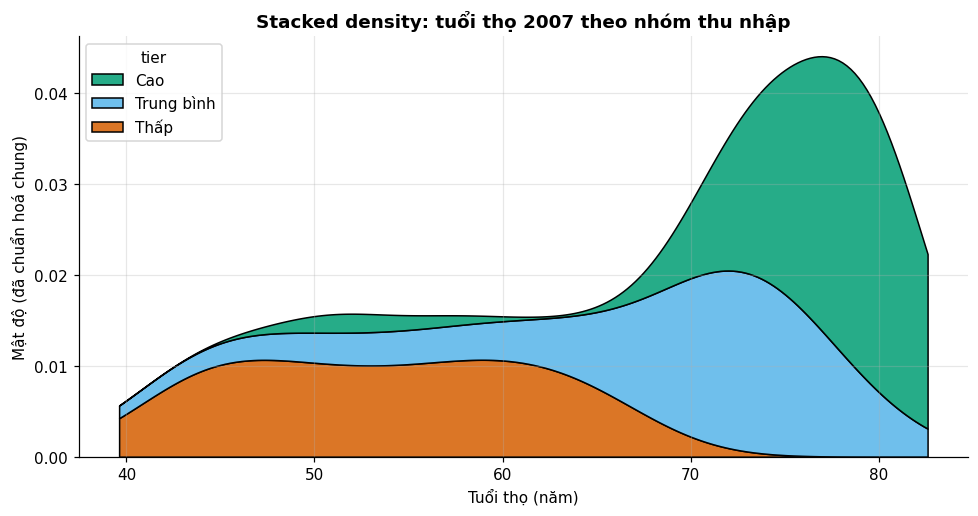

In [40]:
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.kdeplot(data=d07, x="lifeExp", hue="tier", hue_order=TIERS[::-1], multiple="stack", palette=TIER_COL,
            common_norm=True, linewidth=1, alpha=.85, ax=ax, cut=0)
ax.set(title="Stacked density: tuổi thọ 2007 theo nhóm thu nhập", xlabel="Tuổi thọ (năm)", ylabel="Mật độ (đã chuẩn hoá chung)")
show("5d_stacked_density")

**Nhận xét / đáp án:** Diện tích mỗi lớp tỉ lệ với số quốc gia của nhóm (do common_norm). Lớp giữa khó đọc vì nền thay đổi.

### 5e) Ridgeline plot  `[Nâng cao]`  _(Slide 58–59)_  — **1.5 điểm**

> Vẽ ridgeline plot phân phối tuổi thọ qua 12 năm (tự cài đặt bằng gaussian_kde + fill_between, KHÔNG dùng thư viện joypy). Mô tả xu thế dịch chuyển của phân phối theo thời gian và nêu hiện tượng thay đổi hình dạng (số đỉnh, độ lệch).

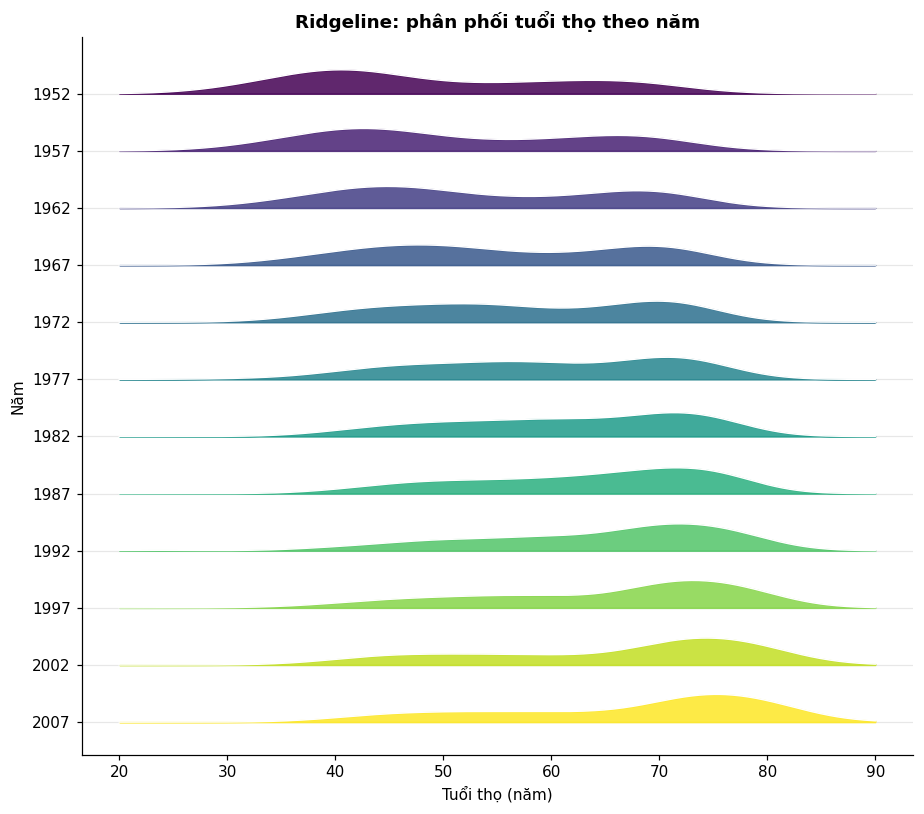

In [41]:
grid = np.linspace(20, 90, 400)
fig, ax = plt.subplots(figsize=(8.5, 7.5))
cmap_ = plt.cm.viridis
for i, y_ in enumerate(sorted(df["year"].unique())[::-1]):
    dens = stats.gaussian_kde(df[df["year"] == y_]["lifeExp"])(grid) * 12      # hệ số 12: nhân để các ridge chồng nhau nhẹ
    ax.fill_between(grid, i, i + dens, color=cmap_(1 - i / 11), alpha=.85, zorder=100 - i)
    ax.plot(grid, i + dens, color="white", lw=1, zorder=100 - i)
ax.set_yticks(range(12)); ax.set_yticklabels(sorted(df["year"].unique())[::-1]); ax.grid(axis="x")
ax.set(title="Ridgeline: phân phối tuổi thọ theo năm", xlabel="Tuổi thọ (năm)", ylabel="Năm")
show("5e_ridgeline")

**Nhận xét / đáp án:** Các ridge dịch dần sang phải; phân phối từ hai khối rõ (1952) dồn dần về một đỉnh ở vùng 70+ với đuôi trái ngắn lại.

### 5f) Violin, strip chart, sina plot  `[Nâng cao]`  _(Slide 60–63)_  — **1.5 điểm**

> Vẽ ba biểu đồ cho tuổi thọ theo năm (các năm 1952, 1972, 1992, 2007): violin plot, strip chart (chiếu dữ liệu xuống trục phụ thuộc, không jitter) và sina plot (violin + điểm rải theo mật độ).
>
> Câu hỏi tư duy: boxplot có phát hiện được phân phối hai đỉnh (bimodal) không? Violin khắc phục ra sao, và hạn chế khi dữ liệu thưa là gì (slide 61–62)?

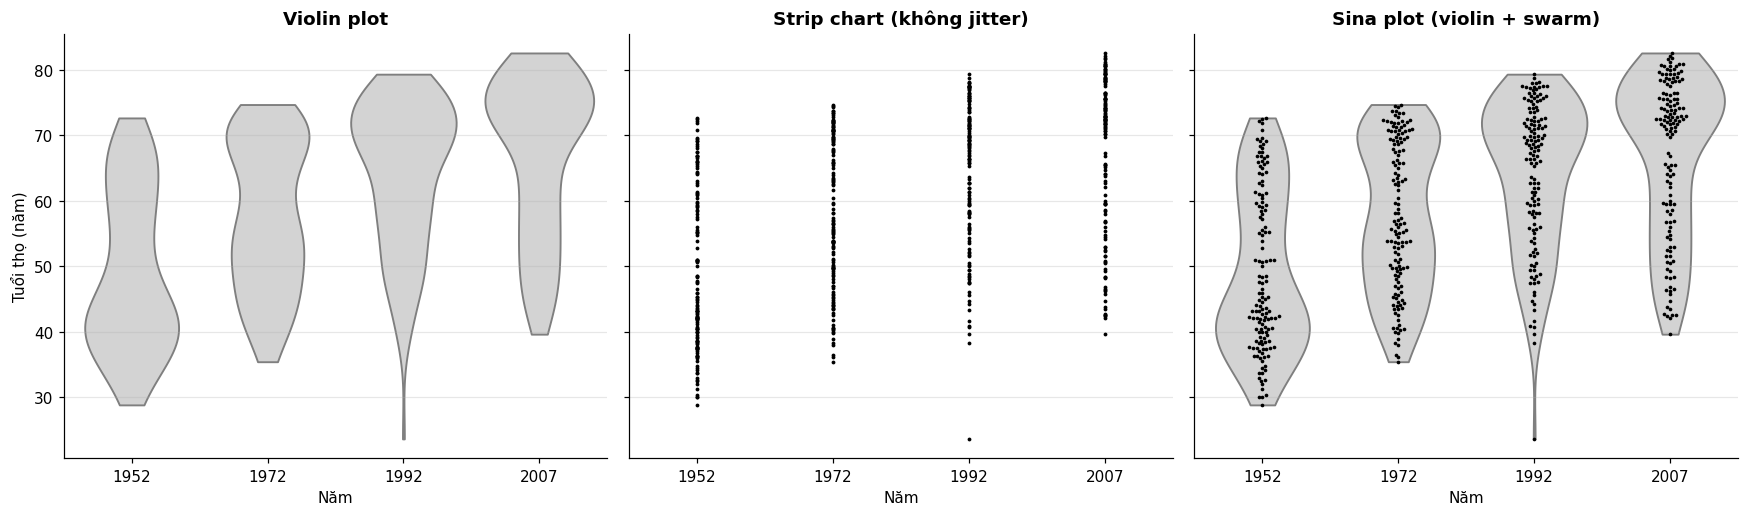

In [42]:
sel = df[df["year"].isin([1952, 1972, 1992, 2007])]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
sns.violinplot(data=sel, x="year", y="lifeExp", inner=None, cut=0, color="lightgray", ax=axs[0]); axs[0].set_title("Violin plot")
sns.stripplot(data=sel, x="year", y="lifeExp", jitter=False, size=2.5, color="k", ax=axs[1]); axs[1].set_title("Strip chart (không jitter)")
sns.violinplot(data=sel, x="year", y="lifeExp", inner=None, cut=0, color="lightgray", ax=axs[2])
sns.swarmplot(data=sel, x="year", y="lifeExp", size=2.4, color="k", ax=axs[2]); axs[2].set_title("Sina plot (violin + swarm)")
for a in axs: a.set_xlabel("Năm")
axs[0].set_ylabel("Tuổi thọ (năm)")
show("5f_violin_strip_sina")

**Nhận xét / đáp án:** Boxplot không thấy được hai đỉnh; violin cho thấy, nhưng dữ liệu thưa (142 điểm/năm) làm hình violin kém tin cậy — nên kết hợp điểm (strip/sina).

### 5g) Quantile dot plot  `[Nâng cao]`  _(Slide 47)_  — **1.5 điểm**

> Vẽ quantile dot plot tuổi thọ 2007 với 20 chấm (mỗi chấm = 5% số quốc gia, đặt tại các phân vị (k−0,5)/20). Dùng nó để trả lời bằng cách ĐẾM CHẤM: 'xác suất một quốc gia ngẫu nhiên có tuổi thọ dưới 60 là bao nhiêu?' và đối chiếu với tỉ lệ thực tế trong dữ liệu.

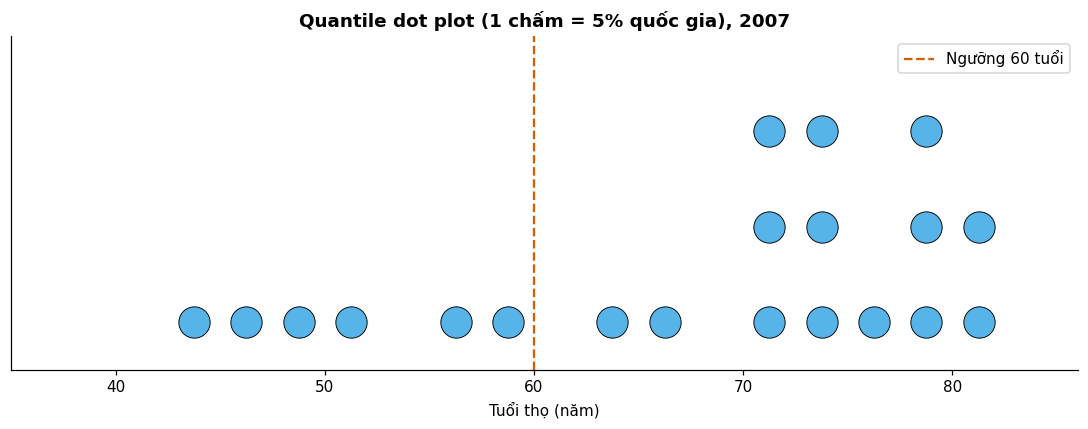

Số chấm < 60: 6 -> xấp xỉ 30% | thực tế: 30.3%


In [43]:
from collections import defaultdict
qd = np.quantile(x, (np.arange(20) + .5) / 20)
binw = 2.5; cnt = defaultdict(int); px, py = [], []
for qv in qd:
    bi = int(qv // binw); px.append((bi + .5) * binw); py.append(cnt[bi] + .5); cnt[bi] += 1
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(px, py, s=420, color=OKABE[1], edgecolor="k", lw=.6, zorder=3)
ax.axvline(60, color=OKABE[5], ls="--", label="Ngưỡng 60 tuổi")
ax.set(title="Quantile dot plot (1 chấm = 5% quốc gia), 2007", xlabel="Tuổi thọ (năm)", xlim=(35, 86), yticks=[], ylim=(0, max(py) + 1))
ax.legend(); ax.grid(False)
show("5g_quantile_dot")
print("Số chấm < 60:", int((qd < 60).sum()), "-> xấp xỉ", f"{(qd < 60).mean():.0%}", "| thực tế:", f"{(x < 60).mean():.1%}")

**Nhận xét / đáp án:** Có 6/20 chấm dưới 60 ≈ **30%**; thực tế 30,3%. Đếm chấm trực quan hơn đọc diện tích dưới đường cong.

### 5h) Stacked histogram (đối xứng)  `[Nâng cao]`  _(Slide 48)_  — **1.5 điểm**

> Vẽ histogram đối xứng (back-to-back): số quốc gia theo khoảng tuổi thọ (bin 5 năm) của 1952 bên trái và 2007 bên phải, giống dạng kim tự tháp tuổi giới của slide 48. Nhận xét cụ thể về sự dịch chuyển khối lượng phân phối.

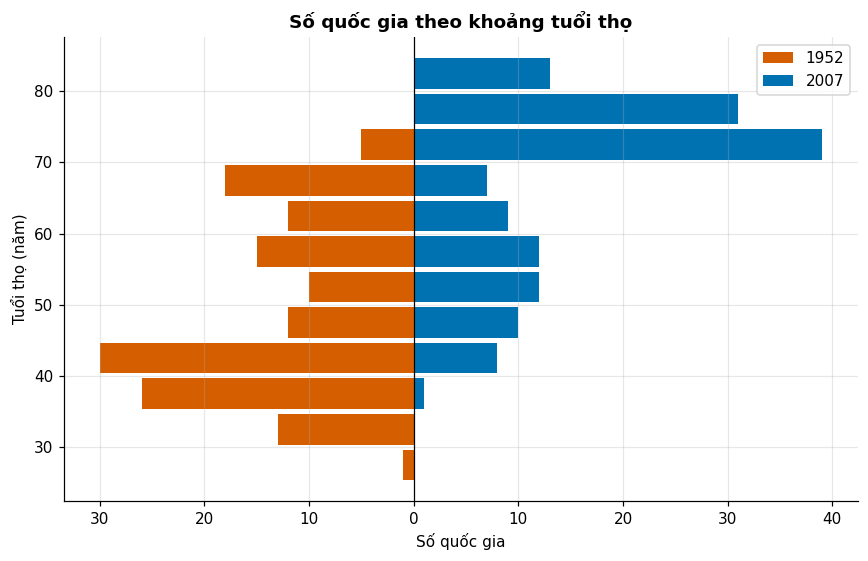

In [44]:
edges = np.arange(25, 90, 5)
c52, _ = np.histogram(df[df["year"] == 1952]["lifeExp"], edges); c07, _ = np.histogram(x, edges)
mid = edges[:-1] + 2.5
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(mid, -c52, height=4.3, color=OKABE[5], label="1952"); ax.barh(mid, c07, height=4.3, color=OKABE[4], label="2007")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{abs(v):.0f}"))
ax.axvline(0, color="k", lw=.8)
ax.set(title="Số quốc gia theo khoảng tuổi thọ", xlabel="Số quốc gia", ylabel="Tuổi thọ (năm)"); ax.legend()
show("5h_back_to_back_hist")

**Nhận xét / đáp án:** Khối lượng 1952 tập trung ở vùng 30–60 tuổi; 2007 dịch sang 65–80.

### 5i) Q-Q plot  `[Nâng cao]`  _(Slide 78)_  — **1.5 điểm**

> Vẽ Q-Q plot kiểm tra tính chuẩn của (i) lifeExp 2007 và (ii) log10(gdpPercap) 2007. Đường tham chiếu phải đi qua các tứ phân vị (KHÔNG phải đường hồi quy – slide 78). Kết hợp kiểm định Shapiro–Wilk và giải thích đuôi nào lệch khỏi đường tham chiếu.

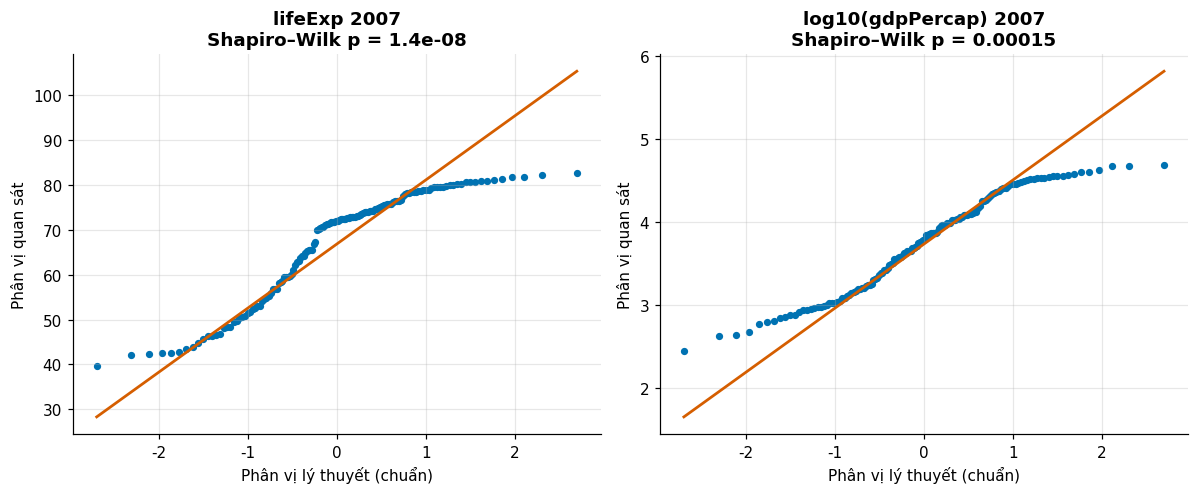

In [45]:
def qq(ax, data, title):
    data = np.sort(np.asarray(data)); n = len(data)
    th = stats.norm.ppf((np.arange(1, n + 1) - .5) / n)
    q1_, q3_ = np.percentile(data, [25, 75]); z1, z3 = stats.norm.ppf([.25, .75])
    slope = (q3_ - q1_) / (z3 - z1); inter = q1_ - slope * z1
    ax.scatter(th, data, s=14, color=OKABE[4]); ax.plot(th, inter + slope * th, color=OKABE[5], lw=1.8)
    ax.set(title=f"{title}\nShapiro–Wilk p = {stats.shapiro(data)[1]:.2g}", xlabel="Phân vị lý thuyết (chuẩn)", ylabel="Phân vị quan sát")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
qq(axs[0], d07["lifeExp"], "lifeExp 2007"); qq(axs[1], np.log10(d07["gdpPercap"]), "log10(gdpPercap) 2007")
show("5i_qqplot")

**Nhận xét / đáp án:** Điểm lệch khỏi đường tham chiếu ở đuôi trái (nhiều nước tuổi thọ thấp hơn chuẩn) → lệch trái, bác bỏ chuẩn theo Shapiro–Wilk; log10(gdpPercap) gần chuẩn hơn.

### 5j) Error bar  `[Nâng cao]`  _(Slide 50)_  — **1.5 điểm**

> Với tuổi thọ 2007, vẽ biểu đồ giống slide 50: dải mẫu (điểm rải) ở trên cùng, bên dưới là trung bình kèm các thanh sai số: ±1 SD, ±1 SE, khoảng tin cậy 80%, 95%, 99%. Vì sao SD rộng hơn SE rất nhiều và hai đại lượng này mô tả hai điều khác nhau?

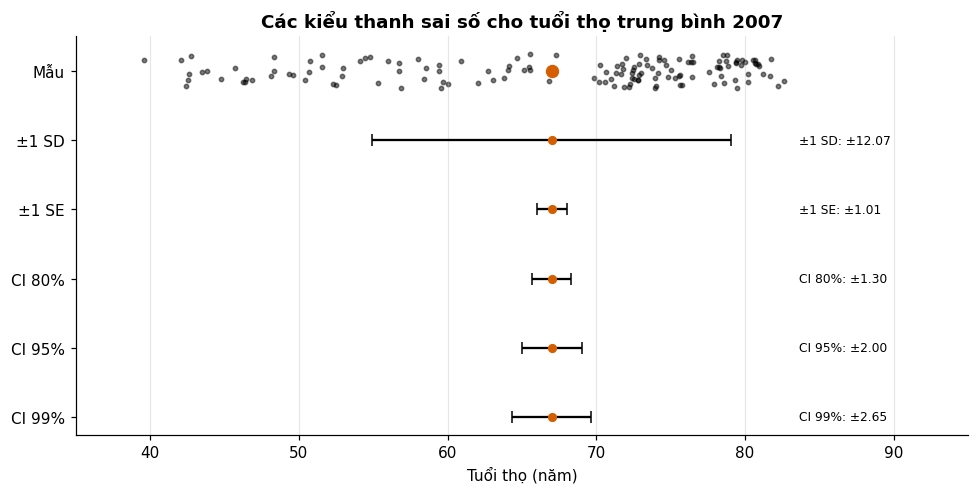

In [46]:
m, sd, n = x.mean(), x.std(ddof=1), len(x); se = sd / np.sqrt(n)
rows = [("±1 SD", sd), ("±1 SE", se)] + [(f"CI {int(l*100)}%", stats.t.ppf((1 + l) / 2, n - 1) * se) for l in (.8, .95, .99)]
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.scatter(x, np.full(n, 1) + rng.uniform(-.25, .25, n), s=8, color="k", alpha=.5)
ax.scatter([m], [1], color=OKABE[5], s=60, zorder=3, label=f"TB = {m:.2f}")
for i, (lab, h) in enumerate(rows, start=0):
    ax.errorbar(m, -i, xerr=h, fmt="o", color=OKABE[5], ecolor="k", capsize=4, ms=5)
    ax.text(x.max() + 1, -i, f"{lab}: ±{h:.2f}", va="center", fontsize=8)
ax.set_yticks([1] + [-i for i in range(5)]); ax.set_yticklabels(["Mẫu"] + [r[0] for r in rows]); ax.set_xlim(35, 95); ax.grid(axis="y", alpha=0)
ax.set(title="Các kiểu thanh sai số cho tuổi thọ trung bình 2007", xlabel="Tuổi thọ (năm)")
show("5j_error_bar")

**Nhận xét / đáp án:** SD mô tả độ phân tán của dữ liệu (~12,1), SE mô tả độ bất định của trung bình (SD/√n, nhỏ hơn √142≈12 lần). Khoảng tin cậy càng cao càng rộng.

### 5k) Graded error bar  `[Nâng cao]`  _(Slide 51)_  — **1.5 điểm**

> Vẽ graded error bar tuổi thọ trung bình 2007 theo nhóm thu nhập (tier): ba mức tin cậy 80/95/99% với độ dày nét giảm dần. Hai nhóm nào có khoảng tin cậy 95% chồng lên nhau không? Có thể kết luận 'khác biệt có ý nghĩa thống kê' chỉ từ việc chồng/không chồng hay không?

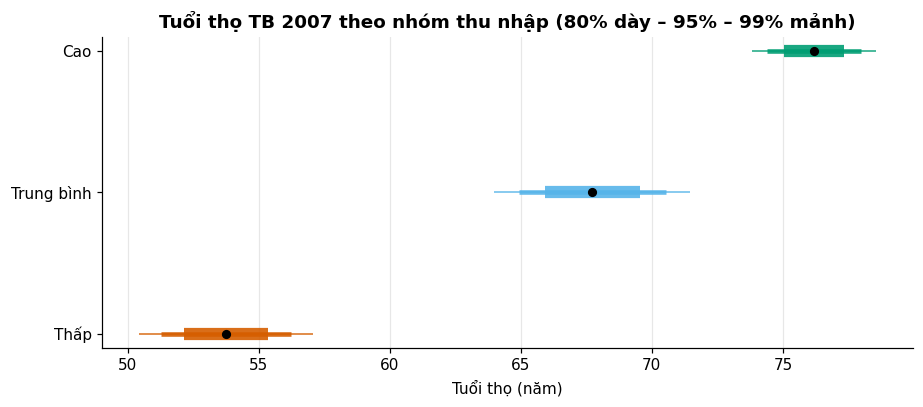

In [47]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for i, t in enumerate(TIERS):
    v_ = d07.loc[d07["tier"] == t, "lifeExp"]; m_, se_ = v_.mean(), v_.std(ddof=1) / np.sqrt(len(v_))
    for lv, lw in zip([.99, .95, .80], [1, 3, 8]):
        h = stats.t.ppf((1 + lv) / 2, len(v_) - 1) * se_
        ax.hlines(i, m_ - h, m_ + h, color=TIER_COL[t], lw=lw, alpha=.9)
    ax.plot(m_, i, "o", color="k", ms=5)
ax.set_yticks(range(3)); ax.set_yticklabels(TIERS)
ax.set(title="Tuổi thọ TB 2007 theo nhóm thu nhập (80% dày – 95% – 99% mảnh)", xlabel="Tuổi thọ (năm)")
ax.grid(axis="y", alpha=0)
show("5k_graded_error_bar")

**Nhận xét / đáp án:** Chồng/không chồng của CI không đồng nghĩa kết luận ý nghĩa thống kê; cần kiểm định so sánh trực tiếp (t-test, ANOVA).

### 5l) Span chart (range bar)  `[Nâng cao]`  _(Slide 49)_  — **1.5 điểm**

> Vẽ span chart (floating bar) khoảng [min, max] tuổi thọ của 8 nước Đông Nam Á trong toàn bộ giai đoạn 1952–2007, sắp xếp theo min. Nước nào có khoảng biến thiên rộng nhất, và vì sao khoảng này không phản ánh 'mức ổn định'?

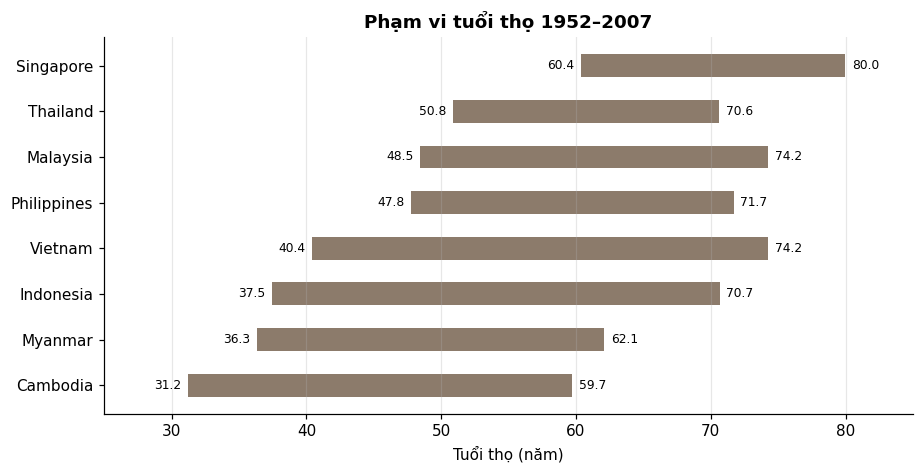

country
Vietnam        33.8
Indonesia      33.2
Cambodia       28.5
Malaysia       25.8
Myanmar        25.8
Philippines    23.9
Thailand       19.8
Singapore      19.6
dtype: float64


In [48]:
r = df[df["country"].isin(sea)].groupby("country")["lifeExp"].agg(["min", "max"]).sort_values("min")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.barh(r.index, r["max"] - r["min"], left=r["min"], height=.5, color="#8c7b6b")
for c_, (a, b) in r.iterrows():
    ax.text(a - .5, c_, f"{a:.1f}", ha="right", va="center", fontsize=8); ax.text(b + .5, c_, f"{b:.1f}", va="center", fontsize=8)
ax.set(title="Phạm vi tuổi thọ 1952–2007", xlabel="Tuổi thọ (năm)", xlim=(25, 85)); ax.grid(axis="y", alpha=0)
show("5l_span_chart")
print((r["max"] - r["min"]).sort_values(ascending=False).round(1))

**Nhận xét / đáp án:** Việt Nam (33,8 năm) và Indonesia (33,2) có khoảng biến thiên rộng nhất, Singapore (19,6) hẹp nhất. Khoảng min–max chỉ phản ánh hai điểm cực, không phải độ ổn định.

### 5m) So sánh bốn cách xem phân phối  `[Nâng cao]`  _(Slide 44, 56, 60, 72)_  — **1.5 điểm**

> Vẽ cùng dữ liệu lifeExp năm 1952 bằng bốn biểu đồ: histogram, density, violin, boxplot. Biểu đồ nào cho thấy rõ nhất cấu trúc phân phối nhiều đỉnh và biểu đồ nào che giấu nó? Rút ra quy tắc chọn biểu đồ phân phối.

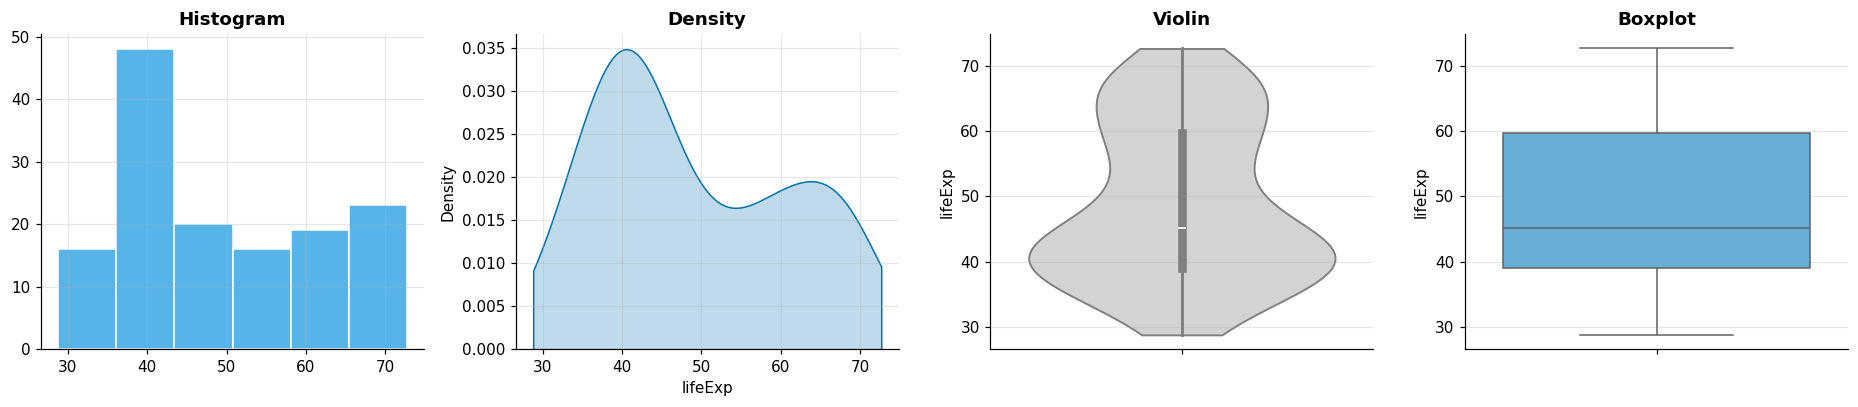

In [49]:
x52 = df[df["year"] == 1952]["lifeExp"]
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
axs[0].hist(x52, bins="fd", color=OKABE[1], edgecolor="white"); axs[0].set_title("Histogram")
sns.kdeplot(x52, fill=True, color=OKABE[4], ax=axs[1], cut=0); axs[1].set_title("Density")
sns.violinplot(y=x52, color="lightgray", cut=0, ax=axs[2]); axs[2].set_title("Violin")
sns.boxplot(y=x52, color=OKABE[1], ax=axs[3]); axs[3].set_title("Boxplot")
show("5m_four_views")

**Nhận xét / đáp án:** Histogram và violin lộ cấu trúc nhiều đỉnh, boxplot che giấu. Quy tắc: phân phối nhiều đỉnh → histogram/density/violin; so sánh nhiều nhóm → boxplot kèm điểm.

---
## Câu 6. Heatmap, correlogram, pie chart và biểu đồ tỉ lệ nhiều biến

### 6a) Heatmap  _(Slide 45, 23)_  — **1.0 điểm**

> Vẽ heatmap tuổi thọ theo quốc gia (Vietnam, Thailand, China, India, Japan, Brazil, Germany, United States) và năm.
>
> Yêu cầu: dùng thang mầu tuần tự (sequential – slide 23) cảm nhận đều (viridis), sắp xếp hàng theo tuổi thọ 1952, có ghi số. Nhận xét hai nước có biến đổi khác thường nhất.

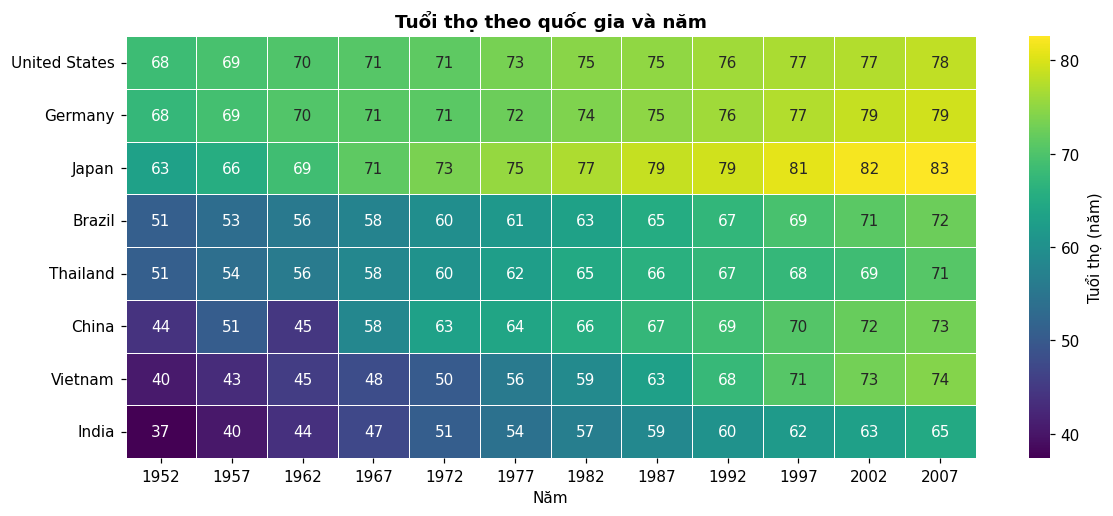

In [50]:
eight = ["Vietnam", "Thailand", "China", "India", "Japan", "Brazil", "Germany", "United States"]
hm = df[df["country"].isin(eight)].pivot(index="country", columns="year", values="lifeExp")
hm = hm.sort_values(1952, ascending=False)
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(hm, annot=True, fmt=".0f", cmap="viridis", linewidths=.5, cbar_kws={"label": "Tuổi thọ (năm)"}, ax=ax)
ax.set(title="Tuổi thọ theo quốc gia và năm", xlabel="Năm", ylabel=""); ax.grid(False)
show("6a_heatmap")

**Nhận xét / đáp án:** Việt Nam và Trung Quốc tăng nhanh nhất; Ấn Độ bắt đầu thấp nhất. Sắp hàng theo 1952 làm hội tụ theo thời gian lộ rõ.

### 6b) Correlogram  _(Slide 86)_  — **1.5 điểm**

> Tính ma trận hệ số tương quan Pearson giữa lifeExp, pop, gdpPercap năm 2007 và vẽ correlogram.
>
> Yêu cầu: chỉ vẽ nửa tam giác dưới, thang mầu phân kỳ (diverging) đối xứng quanh 0 với vmin = −1, vmax = +1. Tính lại với pop và gdpPercap lấy log10 và với hệ số Spearman, lập bảng so sánh. Vì sao corr(lifeExp, pop) gần 0 không có nghĩa 'không liên quan'?

,lifeExp,pop,gdpPercap
lifeExp,1.000,0.048,0.679
pop,0.048,1.000,-0.056
gdpPercap,0.679,-0.056,1.000


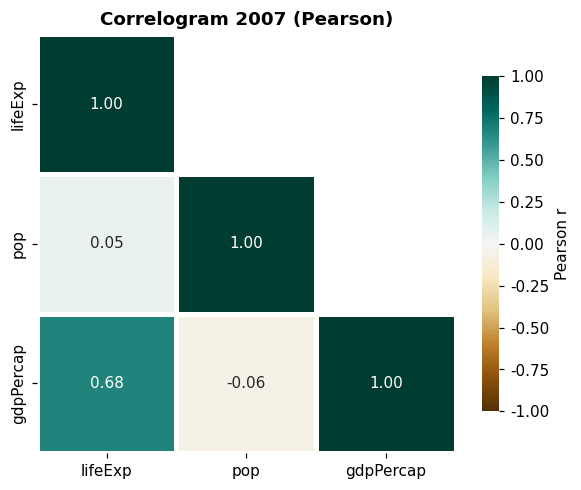

,Pearson (thô),Pearson (log),Spearman
lifeExp–pop,0.048,0.065,0.003
lifeExp–gdpPercap,0.679,0.809,0.857
pop–gdpPercap,-0.056,-0.046,-0.065


In [51]:
cols3 = ["lifeExp", "pop", "gdpPercap"]
corr = d07[cols3].corr(method="pearson")
display(corr.round(3))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="BrBG", vmin=-1, vmax=1, center=0, square=True,
            linewidths=2, linecolor="white", cbar_kws={"label": "Pearson r", "shrink": .8}, ax=ax)
ax.set_title("Correlogram 2007 (Pearson)"); ax.grid(False)
show("6b_correlogram")

lg = d07[cols3].assign(pop=np.log10(d07["pop"]), gdpPercap=np.log10(d07["gdpPercap"]))
cmp_ = pd.DataFrame({"Pearson (thô)": [corr.loc["lifeExp", "pop"], corr.loc["lifeExp", "gdpPercap"], corr.loc["pop", "gdpPercap"]],
                     "Pearson (log)": [lg.corr().loc["lifeExp", "pop"], lg.corr().loc["lifeExp", "gdpPercap"], lg.corr().loc["pop", "gdpPercap"]],
                     "Spearman": [d07[cols3].corr("spearman").loc["lifeExp", "pop"], d07[cols3].corr("spearman").loc["lifeExp", "gdpPercap"], d07[cols3].corr("spearman").loc["pop", "gdpPercap"]]},
                    index=["lifeExp–pop", "lifeExp–gdpPercap", "pop–gdpPercap"])
display(cmp_.round(3))

**Nhận xét / đáp án:** Pearson(lifeExp, gdpPercap) = 0,679 (log: 0,809; Spearman 0,857); (lifeExp, pop) ≈ 0,05; (pop, gdpPercap) ≈ −0,06. Tương quan gần 0 chỉ nói không có quan hệ **tuyến tính**/đơn điệu, và dân số không quyết định tuổi thọ.

### 6c) Pie chart và donut chart  _(Slide 64–65)_  — **1.5 điểm**

> Vẽ pie chart và donut chart tỷ lệ dân số của 5 quốc gia đông dân nhất năm 2007.
>
> Yêu cầu: làm CẢ HAI cách tính tỉ lệ — (i) chỉ trong 5 nước (tổng = 100%), (ii) so với tổng dân số của toàn bộ 142 nước trong dữ liệu (thêm phần 'Còn lại'). Hai cách trả lời hai câu hỏi khác nhau thế nào? Donut ghi tổng ở giữa.

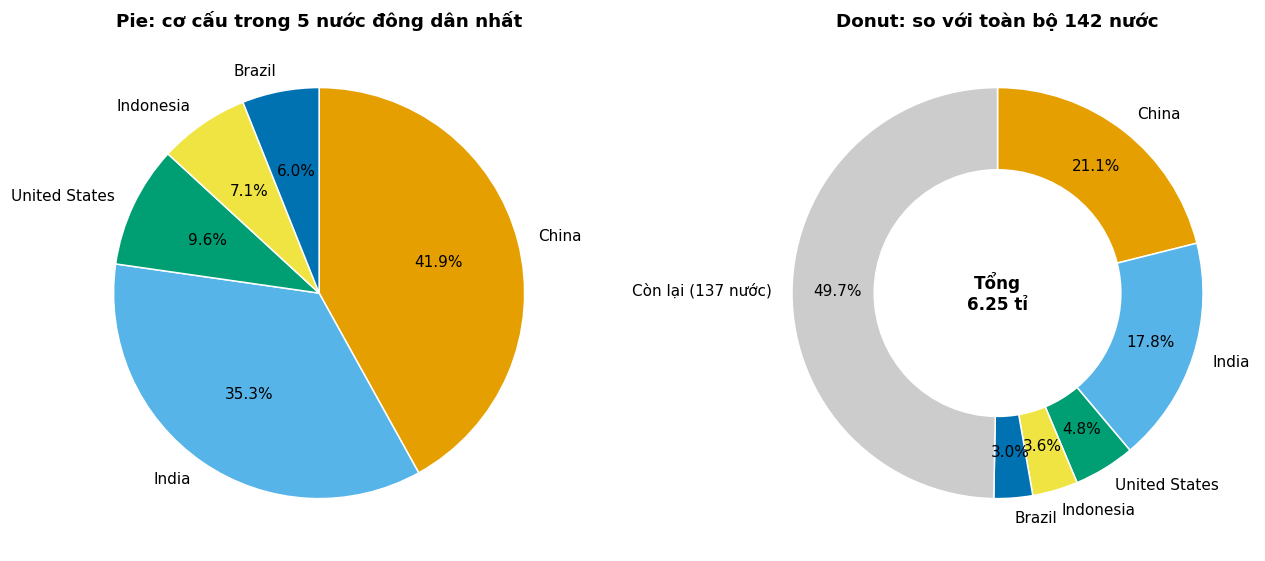

            country           pop  share_top5  share_all
299           China  1.318683e+09       0.419      0.211
707           India  1.110396e+09       0.353      0.178
1619  United States  3.011399e+08       0.096      0.048
719       Indonesia  2.235470e+08       0.071      0.036
179          Brazil  1.900106e+08       0.060      0.030


In [52]:
t5 = d07.nlargest(5, "pop")
rest = d07["pop"].sum() - t5["pop"].sum()
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))
axs[0].pie(t5["pop"], labels=t5["country"], autopct="%1.1f%%", startangle=90, counterclock=False,
           colors=OKABE[:5], wedgeprops=dict(edgecolor="white"))
axs[0].set_title("Pie: cơ cấu trong 5 nước đông dân nhất")
vals = list(t5["pop"]) + [rest]; labs = list(t5["country"]) + ["Còn lại (137 nước)"]
axs[1].pie(vals, labels=labs, autopct="%1.1f%%", startangle=90, counterclock=False, pctdistance=.78,
           colors=OKABE[:5] + ["#cccccc"], wedgeprops=dict(width=.4, edgecolor="white"))
axs[1].text(0, 0, f"Tổng\n{d07['pop'].sum()/1e9:.2f} tỉ", ha="center", va="center", fontsize=11, fontweight="bold")
axs[1].set_title("Donut: so với toàn bộ 142 nước")
show("6c_pie_donut")
print(t5[["country", "pop"]].assign(share_top5=lambda z: z["pop"] / z["pop"].sum(), share_all=lambda z: z["pop"] / d07["pop"].sum()).round(3))

**Nhận xét / đáp án:** Cách (i): China 41,9%, India 35,3%, Mỹ 9,6%, Indonesia 7,1%, Brazil 6,0% (tổng 5 nước = 100%). Cách (ii) so với 142 nước: China 21,1%, India 17,8%, ... Ba cách trả lời hai câu hỏi khác nhau: 'cơ cấu nội bộ top-5' và 'phần của top-5 trong tổng'.

### 6d) Heatmap thay đổi (thang phân kỳ)  `[Nâng cao]`  _(Slide 45, 23)_  — **1.5 điểm**

> Từ heatmap câu a, tạo heatmap MỨC THAY ĐỔI tuổi thọ giữa hai kỳ liên tiếp (năm). Vì sao phải đổi sang thang mầu phân kỳ có tâm 0, và điều gì xảy ra nếu vẫn dùng viridis? Chỉ ra ô có giá trị âm (nếu có) và giải thích bằng bối cảnh lịch sử.

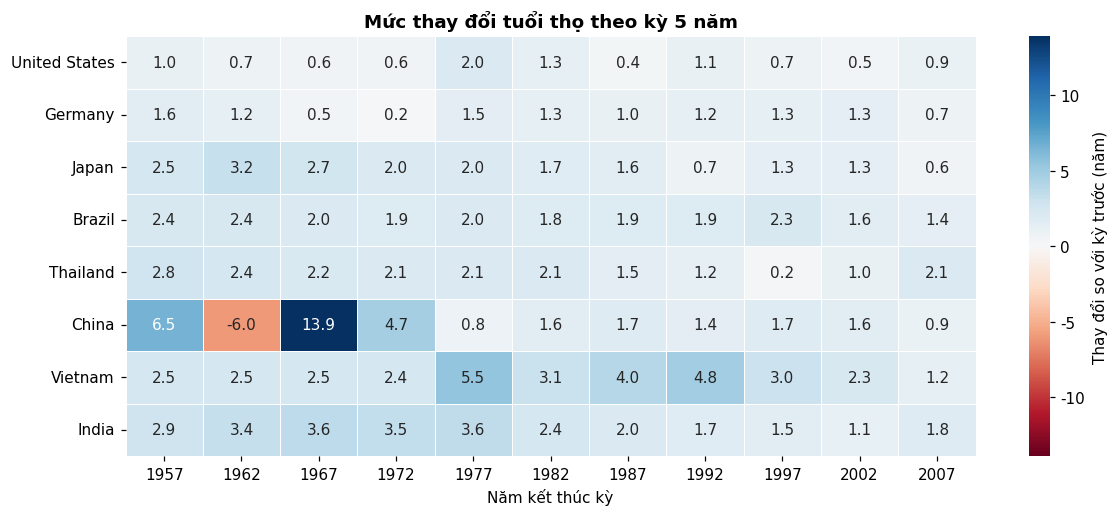

Số ô âm: 1


In [53]:
chg = hm.sort_index(axis=1).diff(axis=1).iloc[:, 1:].loc[hm.index]
fig, ax = plt.subplots(figsize=(11, 4.8))
lim = np.nanmax(np.abs(chg.values))
sns.heatmap(chg, annot=True, fmt=".1f", cmap="RdBu", center=0, vmin=-lim, vmax=lim, linewidths=.5,
            cbar_kws={"label": "Thay đổi so với kỳ trước (năm)"}, ax=ax)
ax.set(title="Mức thay đổi tuổi thọ theo kỳ 5 năm", xlabel="Năm kết thúc kỳ", ylabel=""); ax.grid(False)
show("6d_heatmap_change")
print("Số ô âm:", int((chg < 0).sum().sum()))

**Nhận xét / đáp án:** Thang phân kỳ có tâm 0 làm các mức giảm nổi bật; viridis không phân biệt tăng/giảm. Có **1 ô âm** (Trung Quốc 1962, nạn đói).

### 6e) Scatterplot matrix  `[Nâng cao]`  _(Slide 85)_  — **1.5 điểm**

> Vẽ scatterplot matrix cho lifeExp, log10(gdpPercap), log10(pop) năm 2007 tô mầu theo tier. Vì sao phải lấy log trước khi vẽ ma trận? Quan sát đường chéo (KDE) và cho biết cặp biến nào phân tách các nhóm rõ nhất.

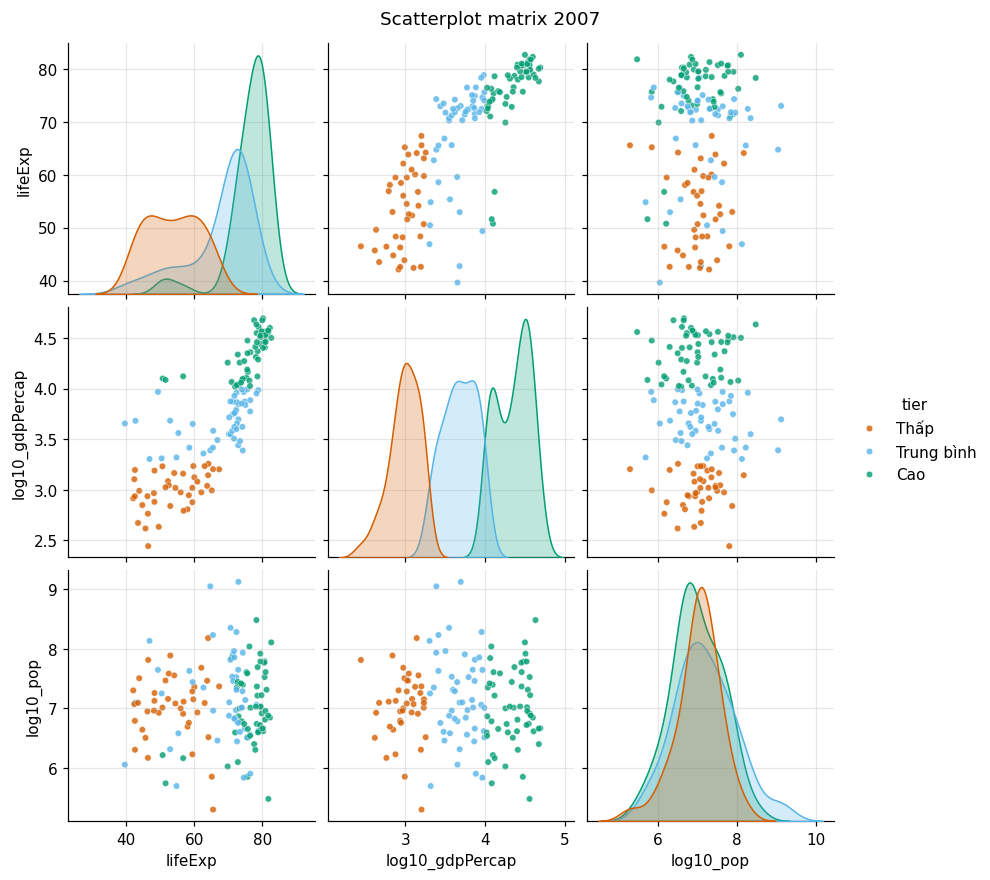

In [54]:
tmp = d07.assign(log10_gdpPercap=np.log10(d07["gdpPercap"]), log10_pop=np.log10(d07["pop"]))
g_ = sns.pairplot(tmp, vars=["lifeExp", "log10_gdpPercap", "log10_pop"], hue="tier", hue_order=TIERS,
                  palette=TIER_COL, diag_kind="kde", plot_kws=dict(s=18, alpha=.8), height=2.6)
g_.fig.suptitle("Scatterplot matrix 2007", y=1.02)
plt.savefig(OUT / "6e_scatter_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

**Nhận xét / đáp án:** Phải lấy log vì pop và gdpPercap lệch phải. Cặp lifeExp–log10 gdpPercap tách các nhóm rõ nhất.

### 6f) Parallel coordinates plot  `[Nâng cao]`  _(Slide 81, 25)_  — **1.5 điểm**

> Vẽ parallel coordinates cho lifeExp, log10(gdpPercap), log10(pop) năm 2007: toàn bộ quốc gia mầu xám nhạt, 8 nước Đông Nam Á mầu xanh, Việt Nam mầu nhấn đậm (accent color). Vì sao phải chuẩn hoá min–max từng trục? Thứ tự các trục ảnh hưởng thế nào tới khả năng phát hiện quan hệ?

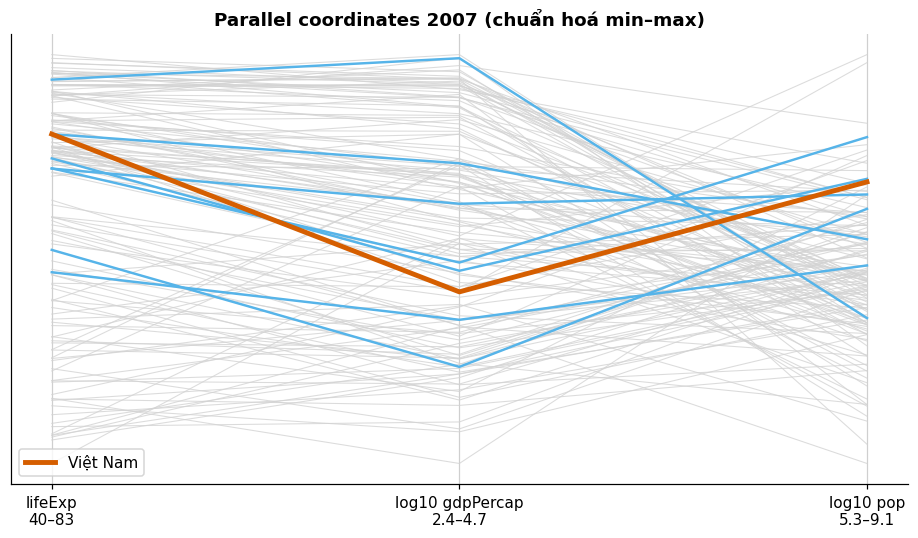

In [55]:
Z = d07.set_index("country")[["lifeExp", "gdpPercap", "pop"]].copy()
Z["gdpPercap"], Z["pop"] = np.log10(Z["gdpPercap"]), np.log10(Z["pop"])
lab = [f"lifeExp\n{Z['lifeExp'].min():.0f}–{Z['lifeExp'].max():.0f}", f"log10 gdpPercap\n{Z['gdpPercap'].min():.1f}–{Z['gdpPercap'].max():.1f}", f"log10 pop\n{Z['pop'].min():.1f}–{Z['pop'].max():.1f}"]
Zn = (Z - Z.min()) / (Z.max() - Z.min())
fig, ax = plt.subplots(figsize=(8.5, 5))
for c_ in Zn.index: ax.plot(range(3), Zn.loc[c_], color="lightgray", lw=.7, alpha=.8)
for c_ in sea: ax.plot(range(3), Zn.loc[c_], color=OKABE[1], lw=1.6)
ax.plot(range(3), Zn.loc["Vietnam"], color=OKABE[5], lw=3.2, label="Việt Nam")
ax.set_xticks(range(3)); ax.set_xticklabels(lab); ax.set_yticks([]); ax.grid(axis="x", alpha=.6); ax.legend()
ax.set_title("Parallel coordinates 2007 (chuẩn hoá min–max)")
show("6f_parallel_coordinates")

**Nhận xét / đáp án:** Chuẩn hoá min–max để các trục chung thang. Việt Nam: tuổi thọ cao so với thu nhập. Thứ tự trục quyết định cặp liền kề nào lộ quan hệ.

### 6g) Slopegraph  `[Nâng cao]`  _(Slide 82)_  — **1.5 điểm**

> Vẽ slopegraph tuổi thọ 1952 → 2007 cho 10 nước (8 nước ở câu a + Zimbabwe + Rwanda). Nhãn hai đầu không được chồng chữ (tự viết hàm giãn nhãn). Tô đỏ nước có tuổi thọ GIẢM, nhấn mầu riêng cho Việt Nam. Nước nào giảm và vì sao slopegraph hợp với dạng dữ liệu ghép cặp (paired data) này?

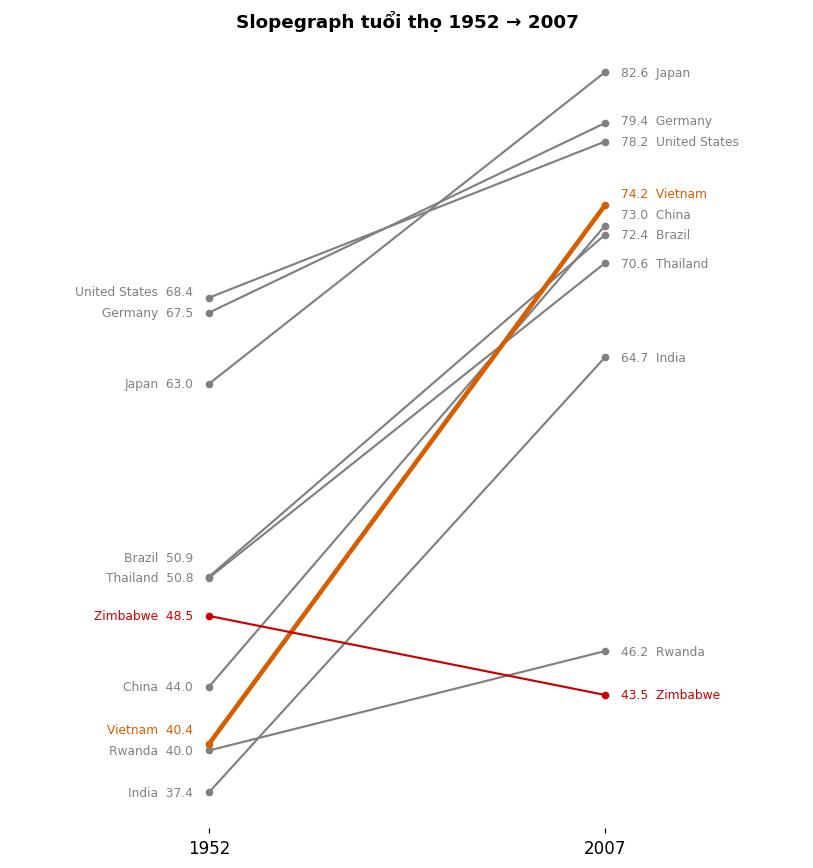

In [56]:
ten = eight + ["Zimbabwe", "Rwanda"]
sl = df[df["year"].isin([1952, 2007]) & df["country"].isin(ten)].pivot(index="country", columns="year", values="lifeExp")

def spread(vals, gap=1.3):
    """Giãn nhãn: đảm bảo khoảng cách tối thiểu `gap` giữa các nhãn liền kề."""
    order = np.argsort(vals); pos = np.array(vals, float)[order]
    for i in range(1, len(pos)):
        if pos[i] - pos[i - 1] < gap: pos[i] = pos[i - 1] + gap
    out = np.empty_like(pos); out[order] = pos; return out

yl, yr = spread(sl[1952].values), spread(sl[2007].values)
fig, ax = plt.subplots(figsize=(7.5, 8))
for i, c_ in enumerate(sl.index):
    col = OKABE[5] if c_ == "Vietnam" else ("#cc0000" if sl.loc[c_, 2007] < sl.loc[c_, 1952] else "gray")
    lw = 3 if c_ == "Vietnam" else 1.4
    ax.plot([0, 1], [sl.loc[c_, 1952], sl.loc[c_, 2007]], "-o", color=col, lw=lw, ms=4)
    ax.text(-.04, yl[i], f"{c_}  {sl.loc[c_, 1952]:.1f}", ha="right", va="center", fontsize=8, color=col)
    ax.text(1.04, yr[i], f"{sl.loc[c_, 2007]:.1f}  {c_}", ha="left", va="center", fontsize=8, color=col)
ax.set_xlim(-.5, 1.5); ax.set_xticks([0, 1]); ax.set_xticklabels(["1952", "2007"], fontsize=11); ax.set_yticks([])
ax.grid(False); ax.spines[["left", "bottom"]].set_visible(False); ax.set_title("Slopegraph tuổi thọ 1952 → 2007")
show("6g_slopegraph")

**Nhận xét / đáp án:** Chỉ **Zimbabwe** giảm (48,5 → 43,5). Slopegraph hợp dữ liệu ghép cặp ít mốc vì độ dốc thể hiện thay đổi từng đối tượng.

### 6h) Nested pies  `[Nâng cao]`  _(Slide 66)_  — **1.5 điểm**

> Vẽ nested pies cho 2 biến phân loại năm 2007: vòng trong là tier (số quốc gia), vòng ngoài là lifeGrp trong từng tier (mỗi vòng ngoài cùng tông mầu với vòng trong nhưng nhạt dần). Vì sao slide 66 khuyên 'nên giới hạn ở 2 biến độc lập, ít giá trị'?

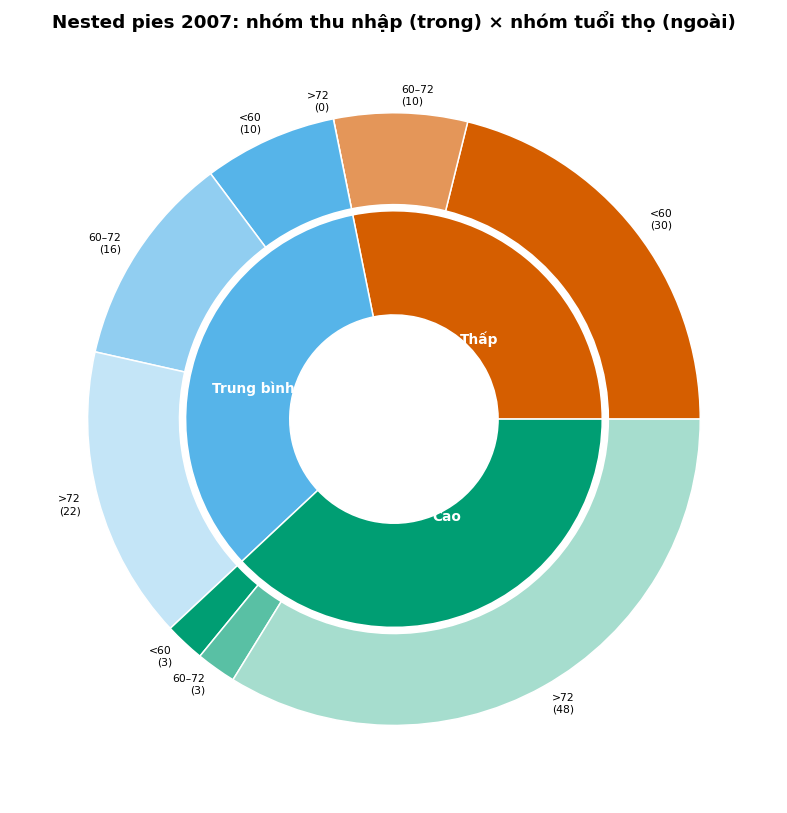

In [57]:
ct = pd.crosstab(d07["tier"], d07["lifeGrp"])
def blend(c, f): return tuple(np.array(mpl.colors.to_rgb(c)) * (1 - f) + f)
inner = ct.sum(axis=1); outer = ct.values.flatten()
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.pie(inner, radius=.68, labels=ct.index, labeldistance=.5, colors=[TIER_COL[t] for t in ct.index],
       wedgeprops=dict(width=.34, edgecolor="white"), textprops=dict(fontsize=9, color="white", fontweight="bold"))
ocol, olab = [], []
for t in ct.index:
    for j, g_ in enumerate(ct.columns):
        ocol.append(blend(TIER_COL[t], [.0, .35, .65][j])); olab.append(f"{g_}\n({ct.loc[t, g_]})")
ax.pie(outer, radius=1.0, labels=olab, labeldistance=1.06, colors=ocol, wedgeprops=dict(width=.3, edgecolor="white"), textprops=dict(fontsize=7))
ax.set_title("Nested pies 2007: nhóm thu nhập (trong) × nhóm tuổi thọ (ngoài)")
show("6h_nested_pies")

**Nhận xét / đáp án:** Nested pies: Thấp (30 nước <60, 10 nước 60–72), Trung bình (10/16/22), Cao (3/3/48). Nên giới hạn 2 biến, ít giá trị vì nhiều lát nhỏ khó đọc.

### 6i) Marimekko chart  `[Nâng cao]`  _(Slide 67)_  — **1.5 điểm**

> Vẽ Marimekko (mosaic) cho cùng bảng chéo ở câu h: chiều rộng cột tỉ lệ với số quốc gia của tier, chiều cao các lớp là tỉ lệ lifeGrp trong tier. Diện tích mỗi ô biểu diễn đại lượng nào? So sánh khả năng đọc với nested pies.

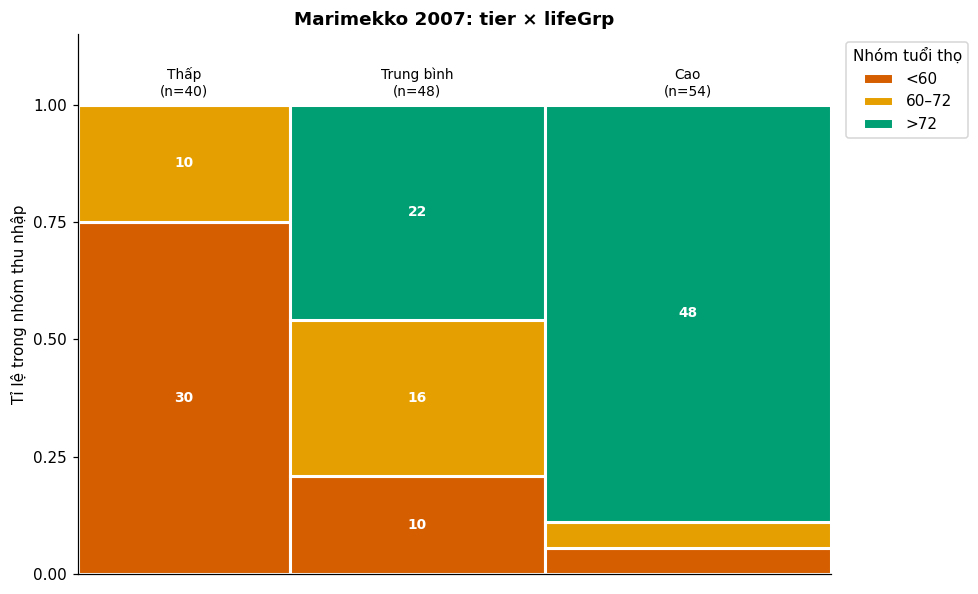

In [58]:
tot = ct.sum(axis=1); W = tot / tot.sum()
fig, ax = plt.subplots(figsize=(9, 5.5))
x0 = 0; pal_l = [OKABE[5], OKABE[0], OKABE[2]]
for t in ct.index:
    bottom = 0
    for j, g_ in enumerate(ct.columns):
        h = ct.loc[t, g_] / tot[t]
        ax.bar(x0, h, width=W[t], bottom=bottom, align="edge", color=pal_l[j], edgecolor="white", lw=2, label=g_ if t == ct.index[0] else None)
        if h > .06: ax.text(x0 + W[t] / 2, bottom + h / 2, str(ct.loc[t, g_]), ha="center", va="center", fontsize=9, color="white", fontweight="bold")
        bottom += h
    ax.text(x0 + W[t] / 2, 1.02, f"{t}\n(n={tot[t]})", ha="center", fontsize=9)
    x0 += W[t]
ax.set(xlim=(0, 1), ylim=(0, 1.15), yticks=[0, .25, .5, .75, 1], title="Marimekko 2007: tier × lifeGrp", ylabel="Tỉ lệ trong nhóm thu nhập", xticks=[])
ax.legend(title="Nhóm tuổi thọ", bbox_to_anchor=(1.01, 1), loc="upper left"); ax.grid(False)
show("6i_marimekko")

**Nhận xét / đáp án:** Diện tích ô Marimekko = số quốc gia trong tổ hợp tier × lifeGrp (rộng theo tier, cao theo tỉ lệ). Dễ so tỉ lệ hơn nested pies.

### 6j) Treemap  `[Nâng cao]`  _(Slide 68)_  — **1.5 điểm**

> Vẽ treemap hai cấp bằng thư viện squarify: cấp 1 chia diện tích theo tier, cấp 2 chia lần lượt theo lifeGrp, với giá trị là TỔNG DÂN SỐ (triệu người). Khác với Marimekko ở câu i, treemap chia diện tích theo biến nào? Nước/nhóm nào áp đảo bức tranh dân số và điều đó nói gì về việc 'đếm nước' và 'đếm người'?

In [59]:
import squarify
agg = d07.groupby(["tier", "lifeGrp"], observed=True)["pop"].sum().div(1e6)
tsum = agg.groupby(level=0).sum().sort_values(ascending=False)
Wd, Hd = 100, 60
r1 = squarify.squarify(squarify.normalize_sizes(tsum.values, Wd, Hd), 0, 0, Wd, Hd)
fig, ax = plt.subplots(figsize=(10, 6))
for rect, t in zip(r1, tsum.index):
    sub = agg[t].sort_values(ascending=False)
    r2 = squarify.squarify(squarify.normalize_sizes(sub.values, rect["dx"], rect["dy"]), rect["x"], rect["y"], rect["dx"], rect["dy"])
    for k, (rr, g_) in enumerate(zip(r2, sub.index)):
        ax.add_patch(plt.Rectangle((rr["x"], rr["y"]), rr["dx"], rr["dy"], facecolor=blend(TIER_COL[t], [0, .35, .65][list(ct.columns).index(g_)]), edgecolor="white", lw=2))
        if rr["dx"] > 6 and rr["dy"] > 4:
            ax.text(rr["x"] + rr["dx"] / 2, rr["y"] + rr["dy"] / 2, f"{g_}\n{sub[g_]:,.0f} tr", ha="center", va="center", fontsize=8)
    ax.text(rect["x"] + 1, rect["y"] + rect["dy"] - 1.5, f"{t} – {tsum[t]:,.0f} tr", fontsize=10, fontweight="bold", va="top")
ax.set(xlim=(0, Wd), ylim=(0, Hd), title="Treemap dân số 2007: tier → lifeGrp"); ax.axis("off")
show("6j_treemap")

ModuleNotFoundError: No module named 'squarify'

**Nhận xét / đáp án:** Treemap chia diện tích theo **tổng dân số**. Nhóm thu nhập trung bình ~4,0 tỉ người áp đảo (có China, India, Indonesia...). Đếm nước (Cao có nhiều nước nhất) và đếm người cho bức tranh khác nhau.

### 6k) Parallel sets plot  `[Nâng cao]`  _(Slide 69–71)_  — **0.0 điểm**

> ★Tự cài đặt parallel sets plot cho 142 quốc gia với 4 trục: nhóm tuổi thọ 1952 → tier 2007 → lifeGrp 2007 → nhóm quy mô dân số 2007 (<10 triệu, 10–100 triệu, >100 triệu). Mỗi dải mầu là MỘT TỔ HỢP đầy đủ 4 giá trị, tô mầu theo trục đầu. Chỉ ra 'dòng chảy' đáng chú ý nhất (ví dụ nhóm tuổi thọ thấp năm 1952 hiện nay nằm ở đâu?).

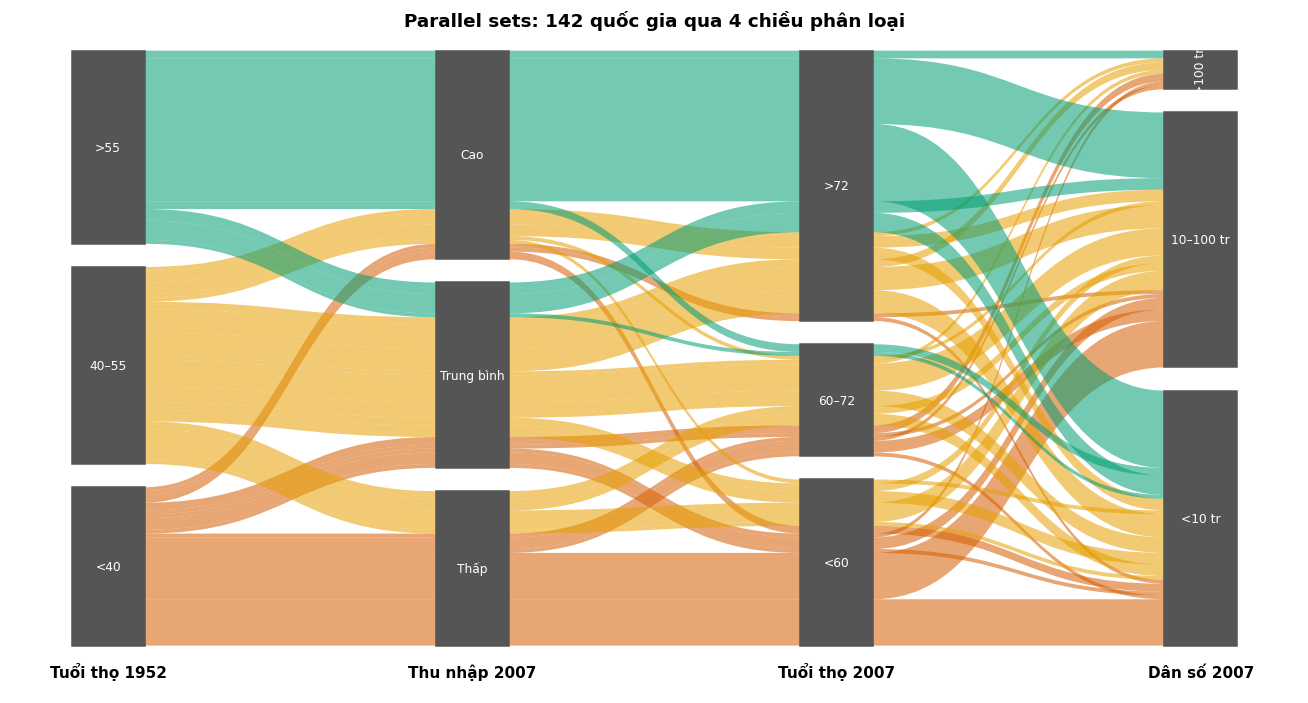

,Tuổi thọ 1952,Thu nhập 2007,Tuổi thọ 2007,Dân số 2007,n
34,>55,Cao,>72,<10 tr,20
35,>55,Cao,>72,10–100 tr,17
0,<40,Thấp,<60,<10 tr,12
1,<40,Thấp,<60,10–100 tr,12
20,40–55,Trung bình,60–72,10–100 tr,7


In [ ]:
from matplotlib.path import Path as MPath
from matplotlib.patches import PathPatch
l52 = df[df["year"] == 1952].set_index("country")["lifeExp"]
ps = d07.set_index("country").copy()
ps["Tuổi thọ 1952"] = pd.cut(l52.reindex(ps.index), [0, 40, 55, 100], labels=["<40", "40–55", ">55"])
ps["Dân số 2007"] = pd.cut(ps["pop"], [0, 1e7, 1e8, np.inf], labels=["<10 tr", "10–100 tr", ">100 tr"])
ps = ps.rename(columns={"tier": "Thu nhập 2007", "lifeGrp": "Tuổi thọ 2007"})
axcols = ["Tuổi thọ 1952", "Thu nhập 2007", "Tuổi thọ 2007", "Dân số 2007"]
combos = ps.groupby(axcols, observed=True).size().reset_index(name="n")      # đã sắp theo thứ tự thể loại (từ trục 1)
N = combos["n"].sum(); gap = 6
start, cur = [], []
for k_, col in enumerate(axcols):
    cats = list(ps[col].cat.categories); st = {}; pos = 0
    for c_ in cats:
        st[c_] = pos; pos += (combos.loc[combos[col] == c_, "n"].sum()) + gap
    start.append(st); cur.append(dict(st))
fig, ax = plt.subplots(figsize=(12, 6.5))
pal3 = {c_: col for c_, col in zip(ps["Tuổi thọ 1952"].cat.categories, [OKABE[5], OKABE[0], OKABE[2]])}
xs_ax = np.arange(len(axcols)) * 3; bw = .3
for _, row in combos.iterrows():
    ys = []
    for k_, col in enumerate(axcols):
        y0 = cur[k_][row[col]]; cur[k_][row[col]] += row["n"]; ys.append((y0, y0 + row["n"]))
    for k_ in range(len(axcols) - 1):
        xa, xb = xs_ax[k_] + bw, xs_ax[k_ + 1] - bw; xm = (xa + xb) / 2
        (a0, a1), (b0, b1) = ys[k_], ys[k_ + 1]
        verts = [(xa, a0), (xm, a0), (xm, b0), (xb, b0), (xb, b1), (xm, b1), (xm, a1), (xa, a1), (xa, a0)]
        codes = [MPath.MOVETO, MPath.CURVE4, MPath.CURVE4, MPath.CURVE4, MPath.LINETO, MPath.CURVE4, MPath.CURVE4, MPath.CURVE4, MPath.CLOSEPOLY]
        ax.add_patch(PathPatch(MPath(verts, codes), facecolor=pal3[row["Tuổi thọ 1952"]], alpha=.55, edgecolor="none"))
for k_, col in enumerate(axcols):
    for c_, y0 in start[k_].items():
        h = combos.loc[combos[col] == c_, "n"].sum()
        ax.add_patch(plt.Rectangle((xs_ax[k_] - bw, y0), 2 * bw, h, color="#555555"))
        ax.text(xs_ax[k_], y0 + h / 2, str(c_), ha="center", va="center", color="white", fontsize=8, rotation=90 if h < 12 else 0)
    ax.text(xs_ax[k_], -8, col, ha="center", fontweight="bold")
ax.set(xlim=(-.8, xs_ax[-1] + .8), ylim=(-12, N + 2 * gap + 4), title="Parallel sets: 142 quốc gia qua 4 chiều phân loại"); ax.axis("off")
show("6k_parallel_sets")
display(combos.sort_values("n", ascending=False).head(5))

**Nhận xét / đáp án:** Hai tổ hợp lớn nhất: (>55 năm 1952 → Cao → >72 → <10 triệu dân) gồm 20 nước và (… → 10–100 triệu) gồm 17 nước; nhóm <40 năm 1952 → Thấp → <60 gồm 12 nước <10 triệu và 12 nước 10–100 triệu: xuất phát thấp thường vẫn ở nhóm thu nhập thấp.

### 6l) Pie vs donut vs bar vs stacked bar  `[Nâng cao]`  _(Slide 64–65)_  — **1.5 điểm**

> Vẽ cùng dữ liệu 5 nước đông dân nhất (câu c, cách i) bằng bốn dạng: pie, donut, bar chart và một cột chồng 100%. Dạng nào giúp so sánh Indonesia với Brazil chính xác nhất? Phát biểu quy tắc: khi nào pie/donut có thể chấp nhận được?

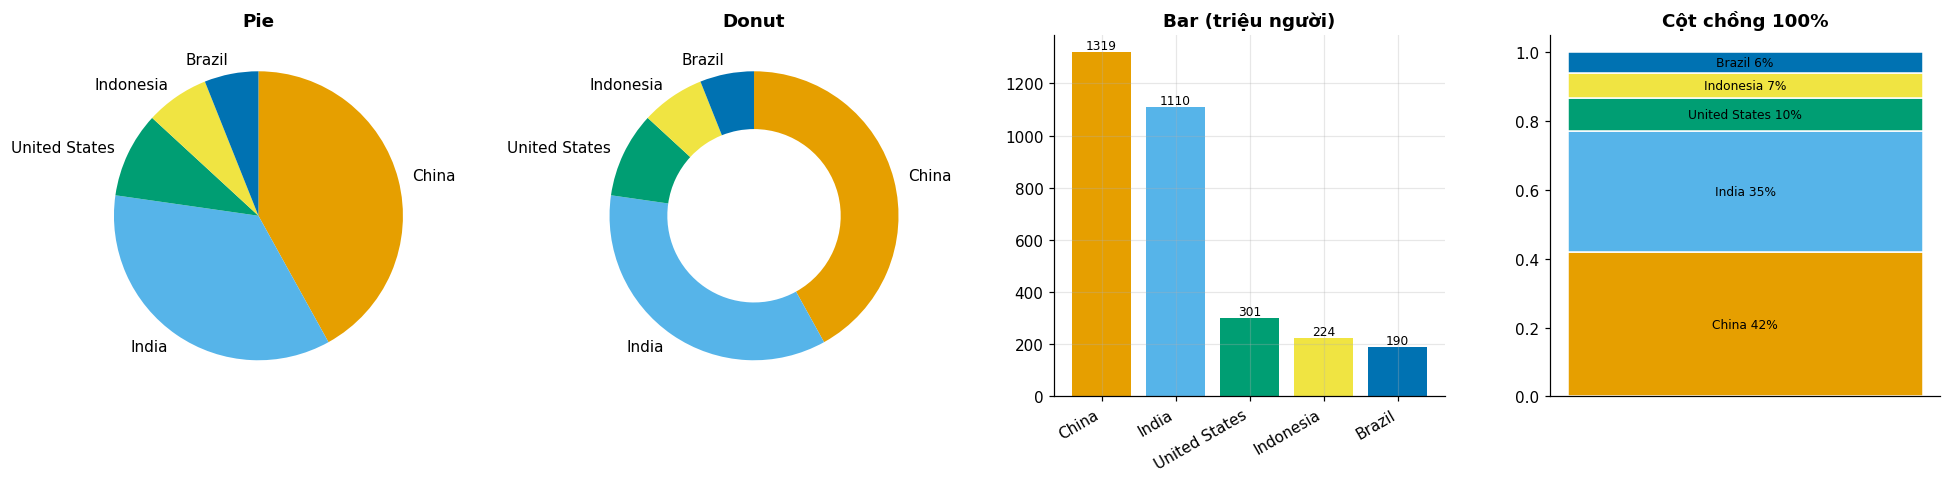

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.5))
axs[0].pie(t5["pop"], labels=t5["country"], startangle=90, counterclock=False, colors=OKABE[:5]); axs[0].set_title("Pie")
axs[1].pie(t5["pop"], labels=t5["country"], startangle=90, counterclock=False, colors=OKABE[:5], wedgeprops=dict(width=.4)); axs[1].set_title("Donut")
b_ = axs[2].bar(t5["country"], t5["pop"] / 1e6, color=OKABE[:5]); axs[2].bar_label(b_, fmt="%.0f", fontsize=8); axs[2].set_title("Bar (triệu người)")
plt.setp(axs[2].get_xticklabels(), rotation=30, ha="right")
bt = 0
for c_, v_, col in zip(t5["country"], t5["pop"] / t5["pop"].sum(), OKABE[:5]):
    axs[3].bar(0, v_, bottom=bt, color=col, edgecolor="white", width=.5); axs[3].text(0, bt + v_ / 2, f"{c_} {v_:.0%}", ha="center", va="center", fontsize=8); bt += v_
axs[3].set(title="Cột chồng 100%", xticks=[]); axs[3].grid(False)
show("6l_pie_vs_bar")

**Nhận xét / đáp án:** Bar/cột chồng 100% so sánh Indonesia–Brazil chính xác nhất (so độ dài). Pie/donut chấp nhận được khi ≤5 lát, mục tiêu là 'một phần của tổng'.

---
## Câu 7. Biểu đồ mở rộng: văn bản, xác suất, tài chính và bản đồ

### 7a) Word cloud  `[Mở rộng]`  _(Slide 46)_  — **1.5 điểm**

> Vẽ word cloud tên các quốc gia với kích thước chữ ~ dân số 2007 (tương tự 'tần số xuất hiện – TF' ở slide 46). Vẽ hai phiên bản: trọng số thô và trọng số căn bậc hai. Vì sao phiên bản thô gần như vô dụng và bản căn bậc hai cân bằng hơn? Nêu hạn chế của word cloud như một biểu đồ định lượng.

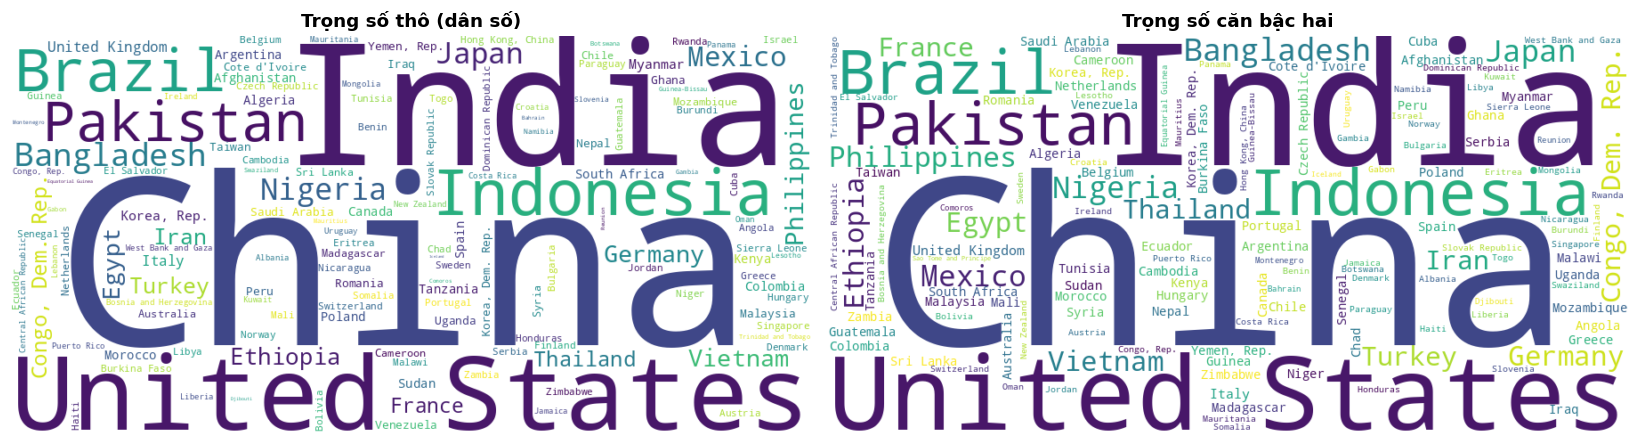

In [ ]:
from wordcloud import WordCloud
freq = dict(zip(d07["country"], d07["pop"]))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (title, f) in zip(axs, [("Trọng số thô (dân số)", freq), ("Trọng số căn bậc hai", {k: np.sqrt(v) for k, v in freq.items()})]):
    wc = WordCloud(width=900, height=450, background_color="white", colormap="viridis", random_state=7, prefer_horizontal=.9).generate_from_frequencies(f)
    ax.imshow(wc, interpolation="bilinear"); ax.set_title(title); ax.axis("off")
show("7a_wordcloud")

**Nhận xét / đáp án:** Trọng số thô bị China/India áp đảo, các nước còn lại gần như vô hình; căn bậc hai cân bằng hơn. Word cloud không đọc được giá trị chính xác, bị ảnh hưởng độ dài chữ.

### 7b) Frequency framing (waffle)  `[Mở rộng]`  _(Slide 84)_  — **1.5 điểm**

> Vẽ frequency framing: lưới 10×10 ô, mỗi ô là 1% quốc gia, tô đậm ô thuộc nhóm 'tuổi thọ ≥ 70' tại ba năm 1952, 1977, 2007 (vị trí ô đậm xáo ngẫu nhiên, seed cố định). Vì sao biểu diễn xác suất bằng ô đếm được dễ hiểu hơn con số '63%' đối với người không chuyên?

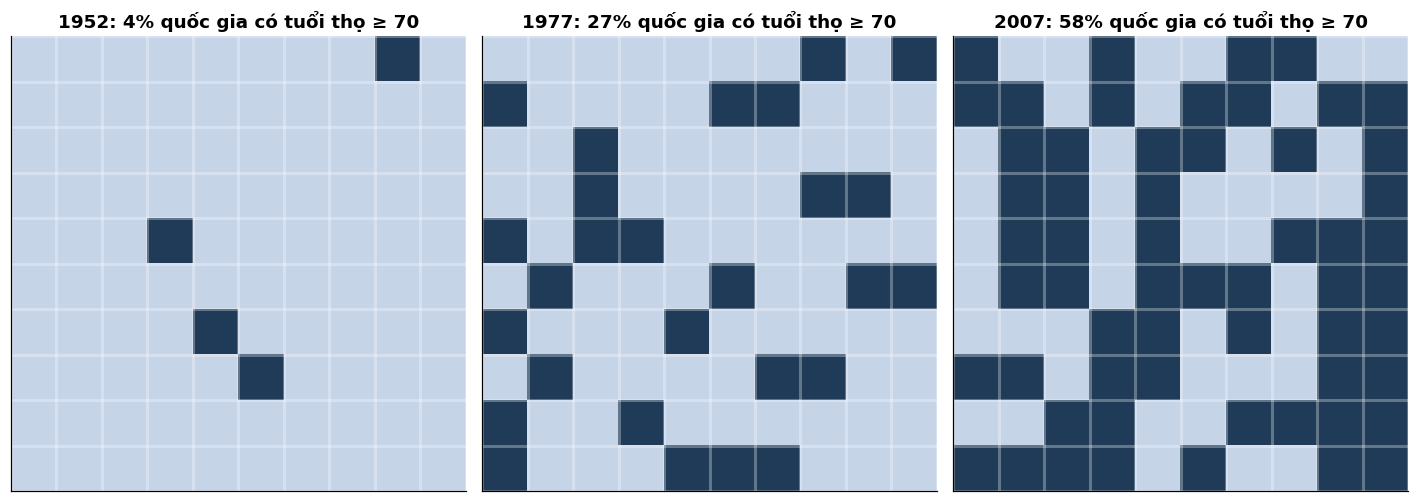

In [ ]:
rng = np.random.default_rng(42)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, y_ in zip(axs, [1952, 1977, 2007]):
    p_ = (df[df["year"] == y_]["lifeExp"] >= 70).mean(); k_ = int(round(p_ * 100))
    cells = np.zeros(100); cells[rng.choice(100, k_, replace=False)] = 1
    ax.imshow(cells.reshape(10, 10), cmap=mpl.colors.ListedColormap(["#c6d4e8", "#1f3b57"]), vmin=0, vmax=1)
    ax.set_xticks(np.arange(-.5, 10, 1), minor=True); ax.set_yticks(np.arange(-.5, 10, 1), minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    ax.tick_params(which="minor", length=0); ax.set_title(f"{y_}: {p_:.0%} quốc gia có tuổi thọ ≥ 70")
show("7b_frequency_framing")

**Nhận xét / đáp án:** Đếm ô dễ hiểu hơn con số %; ba lưới thể hiện sự gia tăng tỉ lệ nước có tuổi thọ ≥70.

### 7c) Candlestick chart  `[Mở rộng]`  _(Slide 52–53)_  — **1.5 điểm**

> Dữ liệu không có giá mở/đóng cửa, nên hãy tự đặt quy ước OHLC cho chuỗi 11 kỳ 5 năm: Open = trung vị tuổi thọ toàn cầu năm trước đó, Close = trung vị năm hiện tại, High/Low = max/min tuổi thọ năm hiện tại. Vẽ candlestick (nến xanh nếu Close ≥ Open, đỏ nếu ngược lại).
>
> Câu hỏi phản biện: quy ước này có ý nghĩa diễn giải như nến chứng khoán không? Vì sao dữ liệu chéo quốc gia (cross-section) khác với chuỗi giá nội phiên? Chọn biểu đồ nào hợp lý hơn?

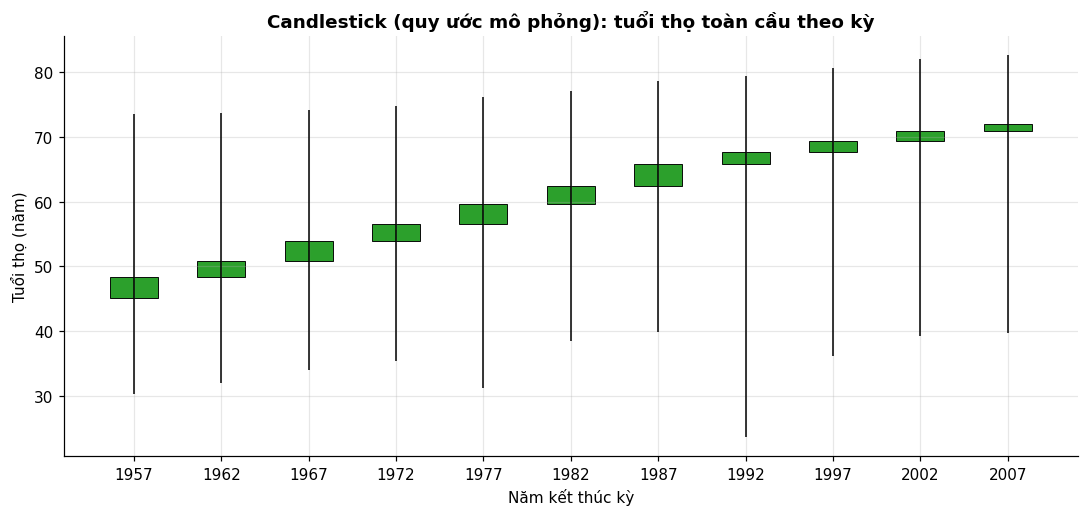

,open,close,high,low
year,,,,
1957,45.1,48.4,73.5,30.3
1962,48.4,50.9,73.7,32.0
1967,50.9,53.8,74.2,34.0
1972,53.8,56.5,74.7,35.4
1977,56.5,59.7,76.1,31.2
1982,59.7,62.4,77.1,38.4
1987,62.4,65.8,78.7,39.9
1992,65.8,67.7,79.4,23.6
1997,67.7,69.4,80.7,36.1


In [ ]:
yr_all = sorted(df["year"].unique())
med_ = df.groupby("year")["lifeExp"].median()
ohlc = pd.DataFrame({"open": med_.shift(1).reindex(yr_all[1:]), "close": med_.reindex(yr_all[1:]),
                     "high": df.groupby("year")["lifeExp"].max().reindex(yr_all[1:]),
                     "low": df.groupby("year")["lifeExp"].min().reindex(yr_all[1:])})
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, (y_, r) in enumerate(ohlc.iterrows()):
    col = "#2ca02c" if r["close"] >= r["open"] else "#d62728"
    ax.vlines(i, r["low"], r["high"], color="k", lw=1)
    ax.bar(i, abs(r["close"] - r["open"]), bottom=min(r["open"], r["close"]), width=.55, color=col, edgecolor="k", lw=.6)
ax.set_xticks(range(len(ohlc))); ax.set_xticklabels(ohlc.index)
ax.set(title="Candlestick (quy ước mô phỏng): tuổi thọ toàn cầu theo kỳ", xlabel="Năm kết thúc kỳ", ylabel="Tuổi thọ (năm)")
show("7c_candlestick")
display(ohlc.round(1))

**Nhận xét / đáp án:** Open/close là trung vị hai năm liên tiếp nên mọi nến xanh (trung vị luôn tăng). Quy ước này **không** có ý nghĩa như chuỗi giá nội phiên: dữ liệu là chéo quốc gia theo thời gian. Boxplot theo năm phù hợp hơn.

### 7d) OHLC chart  `[Mở rộng]`  _(Slide 54–55)_  — **1.0 điểm**

> Vẽ OHLC chart cho cùng bộ dữ liệu ở câu c (vạch đứng Low–High, vạch ngắn bên trái = Open, bên phải = Close; xanh/đỏ như câu c). So sánh OHLC với candlestick: thông tin nào giống hệt nhau, khác nhau ở khía cạnh nhận thức?

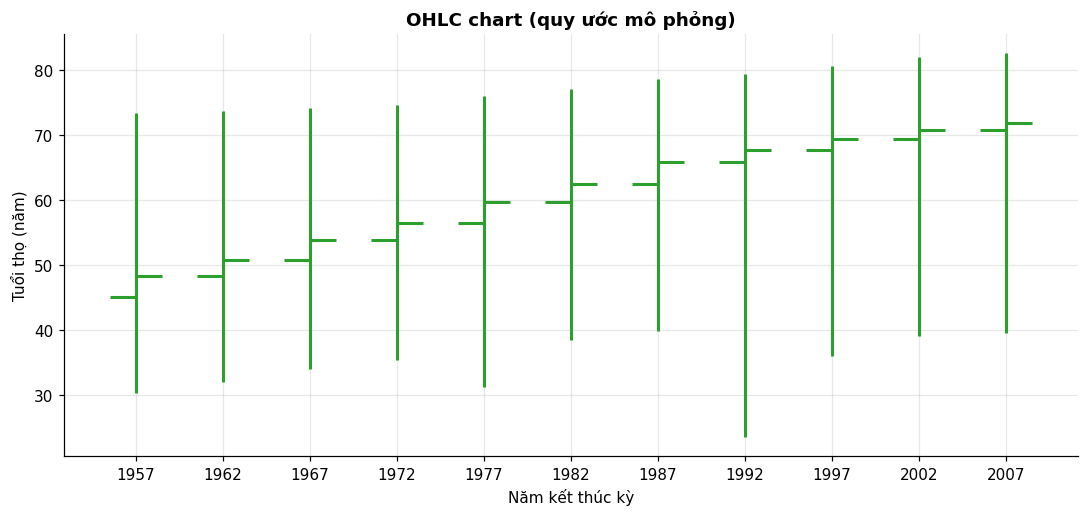

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for i, (y_, r) in enumerate(ohlc.iterrows()):
    col = "#2ca02c" if r["close"] >= r["open"] else "#d62728"
    ax.vlines(i, r["low"], r["high"], color=col, lw=2)
    ax.hlines(r["open"], i - .3, i, color=col, lw=2); ax.hlines(r["close"], i, i + .3, color=col, lw=2)
ax.set_xticks(range(len(ohlc))); ax.set_xticklabels(ohlc.index)
ax.set(title="OHLC chart (quy ước mô phỏng)", xlabel="Năm kết thúc kỳ", ylabel="Tuổi thọ (năm)")
show("7d_ohlc")

**Nhận xét / đáp án:** OHLC chứa đúng thông tin như candlestick; nến nhấn mạnh thân (Open–Close), OHLC gọn hơn khi có nhiều kỳ.

### 7e) Choropleth  `[Mở rộng]`  _(Slide 88, 24, 19)_  — **2.0 điểm**

> ★Vẽ choropleth bản đồ thế giới tô mầu tuổi thọ 2007 bằng thang mầu tuần tự (dữ liệu hình học tải từ GeoJSON công khai; ghép tên nước sang mã ISO3 bằng country_converter). Liệt kê các nước không ghép được. Nước không có dữ liệu tô xám.
>
> Câu hỏi tư duy: phép chiếu kinh–vĩ độ phẳng (slide 19) làm biến dạng diện tích thế nào? Choropleth có xu hướng 'phóng đại' những nước nào so với số dân thật?

Không ghép được với bản đồ: ['Bahrain', 'Comoros', 'Hong Kong, China', 'Mauritius', 'Reunion', 'Sao Tome and Principe', 'Singapore']


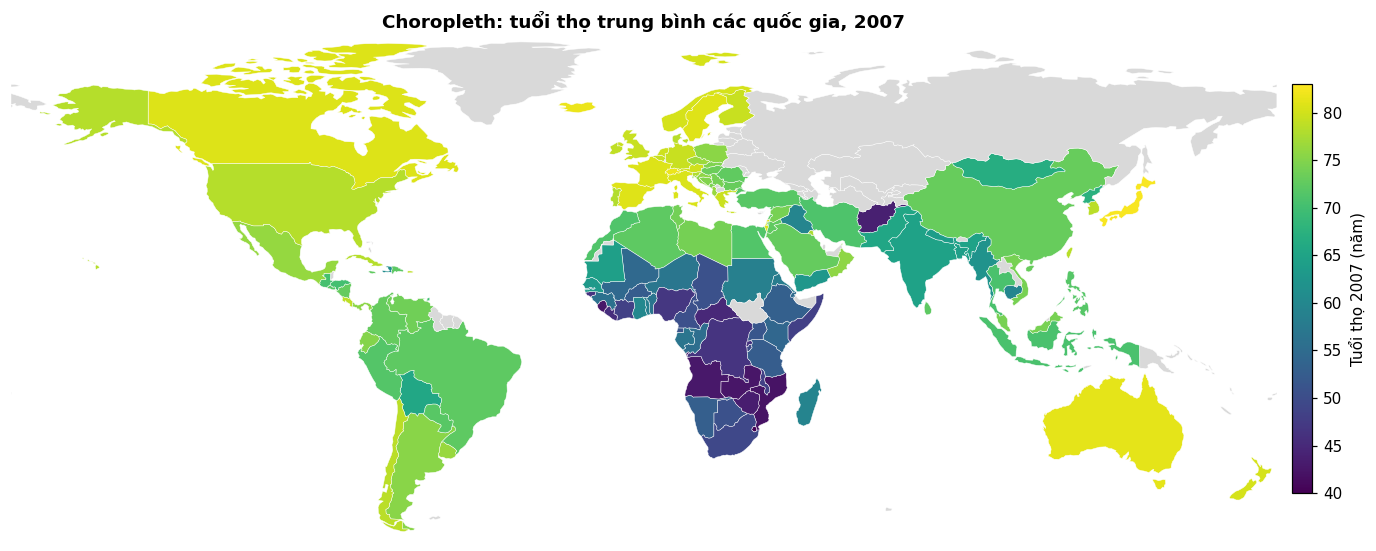

In [ ]:
import json, urllib.request
from shapely.geometry import shape
import country_converter as coco
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

GEO = OUT / "world.geo.json"
if not GEO.exists():
    urllib.request.urlretrieve("https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json", GEO)
geo = json.loads(GEO.read_text(encoding="utf-8"))
d07["iso3"] = coco.convert(d07["country"].tolist(), to="ISO3", not_found=None)
ids = {f["id"] for f in geo["features"]}
print("Không ghép được với bản đồ:", d07.loc[~d07["iso3"].isin(ids), "country"].tolist())

def polys(geom):
    g = shape(geom); return list(g.geoms) if g.geom_type == "MultiPolygon" else [g]

def draw_base(ax, color_of=None):
    patches, cols = [], []
    for f in geo["features"]:
        for p in polys(f["geometry"]):
            patches.append(MplPolygon(np.asarray(p.exterior.coords), closed=True))
            cols.append(color_of(f["id"]) if color_of else "#e3e3e3")
    ax.add_collection(PatchCollection(patches, facecolor=cols, edgecolor="white", linewidth=.3))
    ax.set(xlim=(-180, 180), ylim=(-58, 85), aspect="equal"); ax.axis("off")

val = d07.set_index("iso3")["lifeExp"].to_dict()
norm = mpl.colors.Normalize(40, 83); cm = plt.cm.viridis
fig, ax = plt.subplots(figsize=(14, 6.5))
draw_base(ax, lambda i: cm(norm(val[i])) if i in val else "#d9d9d9")
sm = plt.cm.ScalarMappable(norm=norm, cmap=cm); plt.colorbar(sm, ax=ax, shrink=.6, label="Tuổi thọ 2007 (năm)", pad=.01)
ax.set_title("Choropleth: tuổi thọ trung bình các quốc gia, 2007")
show("7e_choropleth")

**Nhận xét / đáp án:** Một số nước không ghép được: Bahrain, Comoros, Hong Kong, Mauritius, Reunion, São Tomé, Singapore (không có trên bản đồ GeoJSON). Phép chiếu phẳng phóng đại diện tích vĩ độ cao (Canada, Nga).

### 7f) Bubble map  `[Mở rộng]`  _(Slide 87)_  — **1.5 điểm**

> Vẽ bubble map: nền bản đồ xám nhạt, mỗi nước một bong bóng đặt tại tâm của (đa giác lớn nhất) lãnh thổ, diện tích bong bóng ~ dân số 2007, mầu theo tier. So sánh với choropleth ở câu e: biểu đồ nào đề cao các nước diện tích lớn, biểu đồ nào đề cao các nước đông dân?

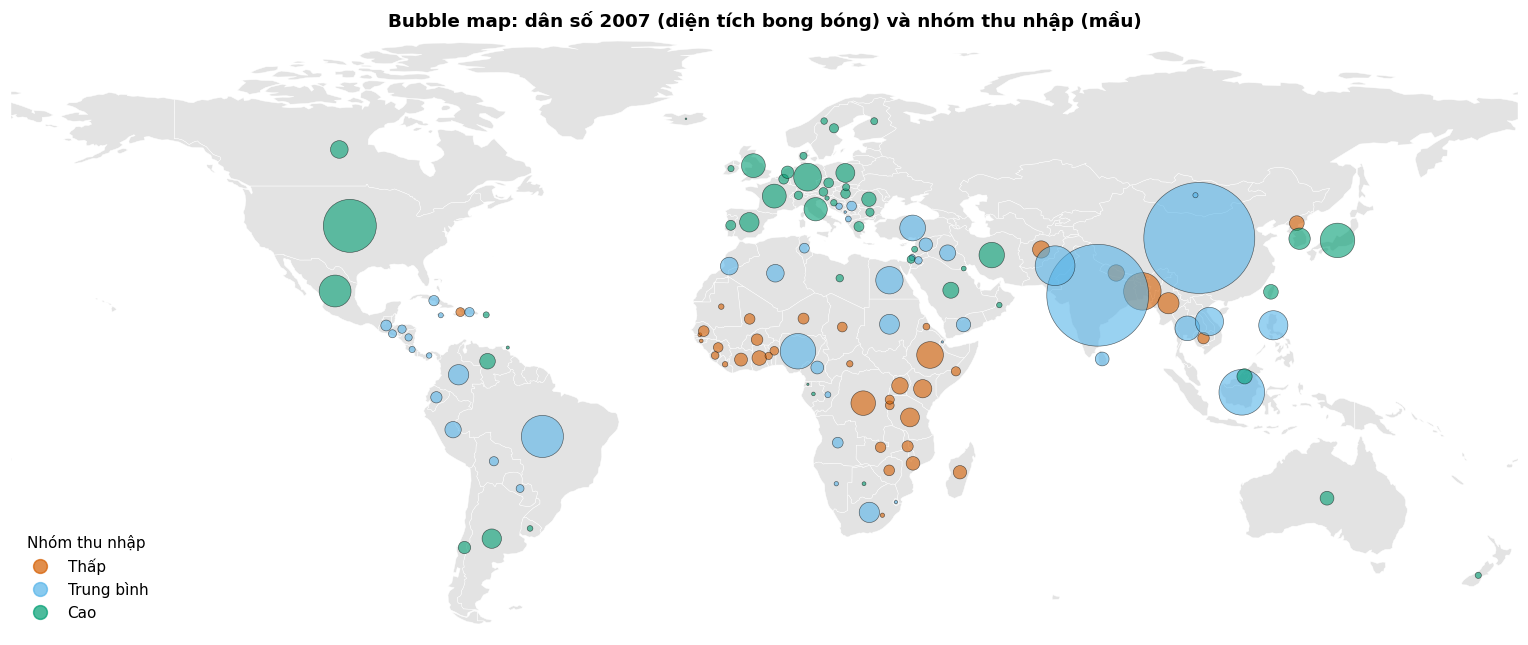

In [ ]:
cent = {}
for f in geo["features"]:
    big = max(polys(f["geometry"]), key=lambda p: p.area); cent[f["id"]] = (big.centroid.x, big.centroid.y)
mm = d07[d07["iso3"].isin(cent.keys())].copy()
mm["x"] = mm["iso3"].map(lambda i: cent[i][0]); mm["y"] = mm["iso3"].map(lambda i: cent[i][1])
fig, ax = plt.subplots(figsize=(14, 6.5))
draw_base(ax)
for t in TIERS:
    s_ = mm[mm["tier"] == t]
    ax.scatter(s_["x"], s_["y"], s=s_["pop"] / 1e6 * 4, color=TIER_COL[t], alpha=.6, edgecolor="k", lw=.4)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=TIER_COL[t], alpha=.7, ms=9) for t in TIERS], labels=TIERS,
          title="Nhóm thu nhập", loc="lower left", frameon=False)
ax.set_title("Bubble map: dân số 2007 (diện tích bong bóng) và nhóm thu nhập (mầu)")
show("7f_bubble_map")

**Nhận xét / đáp án:** Choropleth đề cao nước diện tích lớn; bubble map đề cao nước đông dân (China, India nổi bật).

---
## Câu 8. Sơ đồ (diagram) gắn với dữ liệu

### 8a) Tree diagram (dendrogram)  `[Mở rộng]`  _(Slide 89)_  — **1.5 điểm**

> Dựng tree diagram dạng dendrogram (phân cụm phân cấp Ward) cho 16 nước (8 nước Đông Nam Á + China, India, Japan, Brazil, Germany, United States, Rwanda, Zimbabwe) theo ba biến chuẩn hoá z-score: lifeExp, log10(gdpPercap), log10(pop). Vì sao bắt buộc chuẩn hoá? Cắt cây thành 3 cụm và mô tả mỗi cụm.

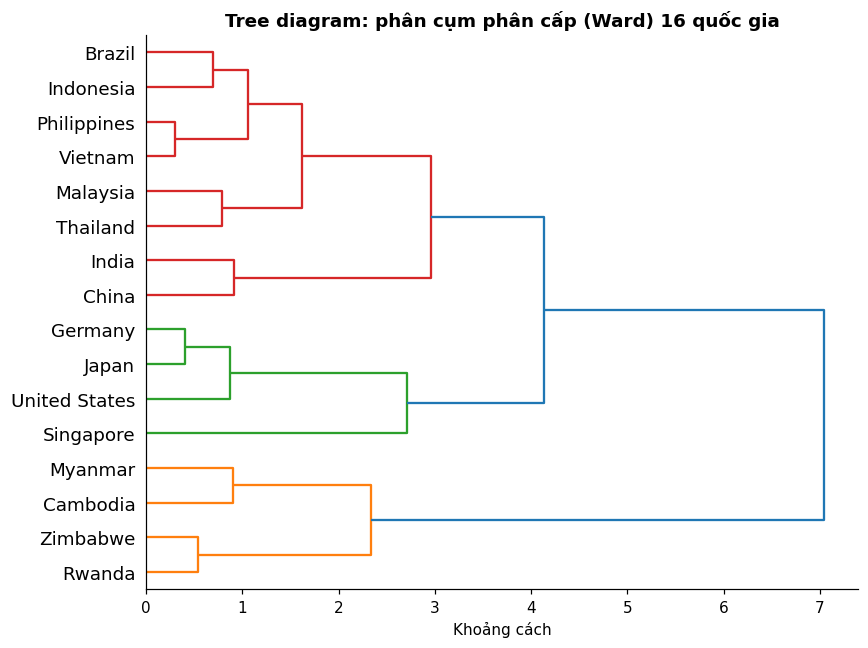

Cụm 1: Cambodia, Myanmar, Rwanda, Zimbabwe
Cụm 2: Singapore, Japan, Germany, United States
Cụm 3: Vietnam, Thailand, Indonesia, Malaysia, Philippines, China, India, Brazil


In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
sel16 = sea + ["China", "India", "Japan", "Brazil", "Germany", "United States", "Rwanda", "Zimbabwe"]
F = d07.set_index("country").loc[sel16, ["lifeExp", "gdpPercap", "pop"]].copy()
F["gdpPercap"], F["pop"] = np.log10(F["gdpPercap"]), np.log10(F["pop"])
Zs = stats.zscore(F.values, axis=0)
Lk = linkage(Zs, "ward")
fig, ax = plt.subplots(figsize=(8, 6))
dendrogram(Lk, labels=F.index.tolist(), orientation="right", color_threshold=Lk[-3, 2] + 1e-9, ax=ax)
ax.set(title="Tree diagram: phân cụm phân cấp (Ward) 16 quốc gia", xlabel="Khoảng cách"); ax.grid(False)
show("8a_dendrogram")
cl = pd.Series(fcluster(Lk, 3, "maxclust"), index=F.index)
for k_, g_ in cl.groupby(cl): print(f"Cụm {k_}: {', '.join(g_.index)}")

**Nhận xét / đáp án:** Chuẩn hoá z-score để biến có đơn vị lớn không chi phối khoảng cách. Ba cụm: (1) Cambodia, Myanmar, Rwanda, Zimbabwe; (2) Singapore, Japan, Germany, US; (3) Vietnam, Thailand, Indonesia, Malaysia, Philippines, China, India, Brazil.

### 8b) Network diagram  `[Mở rộng]`  _(Slide 90)_  — **1.5 điểm**

> Dựng network diagram với 16 nước ở câu a: mỗi nước nối với 2 nước gần nhất (khoảng cách Euclid trên dữ liệu chuẩn hoá) — đồ thị vô hướng; kích thước nút ~ dân số, mầu nút ~ tuổi thọ. Dựng thêm đồ thị CÓ HƯỚNG: mỗi nước chỉ mũi tên tới nước gần nhất. Hai đồ thị cho biết điều gì khác nhau?

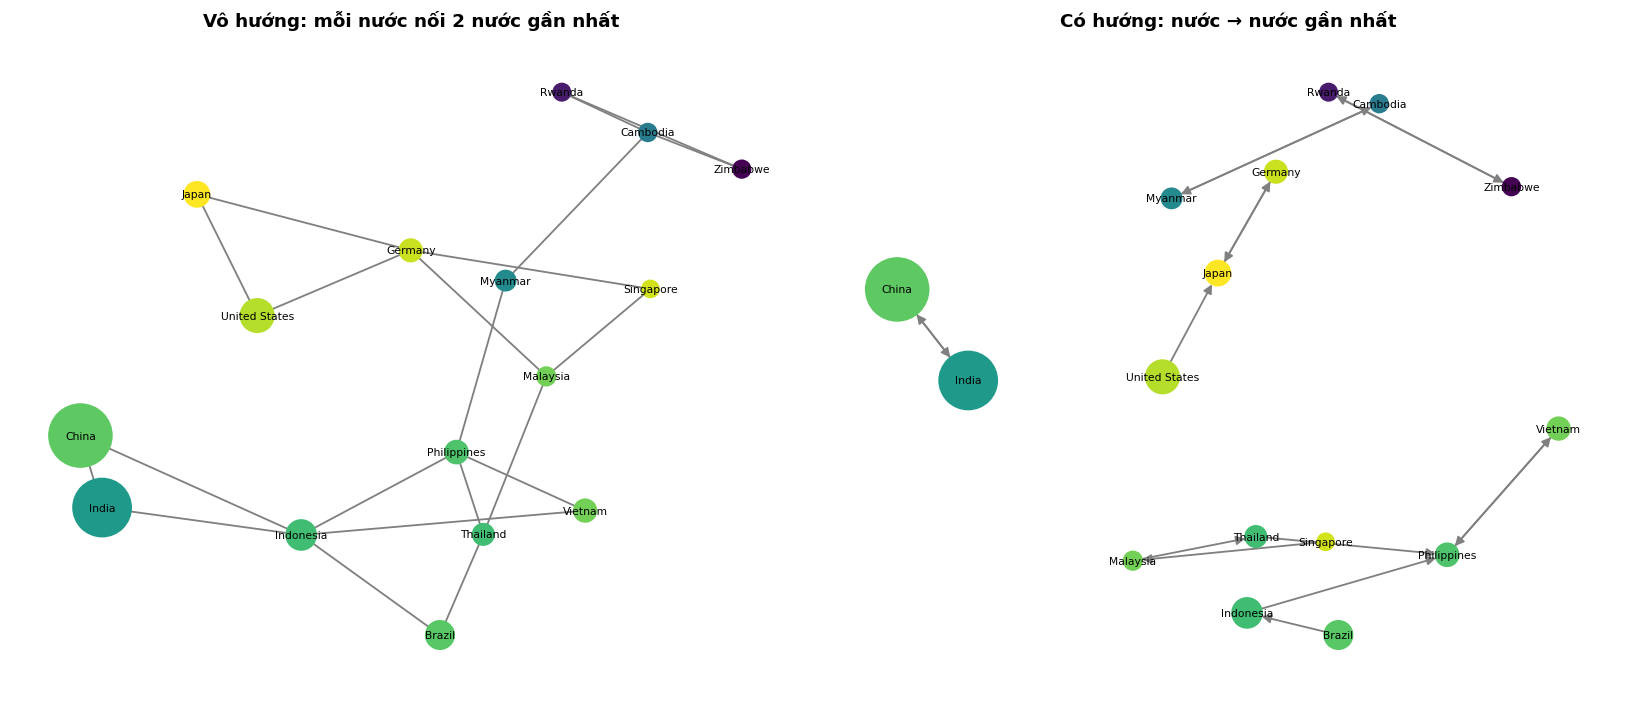

In [ ]:
import networkx as nx
from scipy.spatial.distance import cdist
D = cdist(Zs, Zs); np.fill_diagonal(D, np.inf); names = list(F.index)
G = nx.Graph(); DG = nx.DiGraph(); G.add_nodes_from(names); DG.add_nodes_from(names)
for i, nm in enumerate(names):
    order = np.argsort(D[i])
    for j in order[:2]: G.add_edge(nm, names[j])
    DG.add_edge(nm, names[order[0]])
nsz = [d07.set_index("country").loc[n_, "pop"] / 1e6 * 1.2 + 120 for n_ in names]
ncol = [d07.set_index("country").loc[n_, "lifeExp"] for n_ in names]
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, GG, ttl in [(axs[0], G, "Vô hướng: mỗi nước nối 2 nước gần nhất"), (axs[1], DG, "Có hướng: nước → nước gần nhất")]:
    pos = nx.spring_layout(GG.to_undirected(), seed=3, k=.9)
    nx.draw_networkx(GG, pos, ax=ax, node_size=nsz, node_color=ncol, cmap="viridis", font_size=7, edge_color="gray", width=1.2,
                     arrows=GG.is_directed(), arrowsize=12)
    ax.set_title(ttl); ax.axis("off")
show("8b_network")

**Nhận xét / đáp án:** Đồ thị vô hướng cho thấy cấu trúc láng giềng; đồ thị có hướng cho thấy 'nước gần nhất' (không đối xứng). China và India chỉ nối với nhau và tách khỏi phần còn lại vì dân số cực lớn.

### 8c) Venn diagram  `[Mở rộng]`  _(Slide 91)_  — **1.5 điểm**

> Dựng Venn diagram 3 tập trên dữ liệu 2007: A = tuổi thọ ≥ 75, B = gdpPercap ≥ 20.000, C = dân số ≥ 50 triệu. In ra số phần tử mỗi vùng giao, liệt kê nước thuộc A∩B∩C (nếu có) và nước thuộc A nhưng không thuộc B. Hình tròn Venn có biểu diễn đúng tỉ lệ diện tích không?

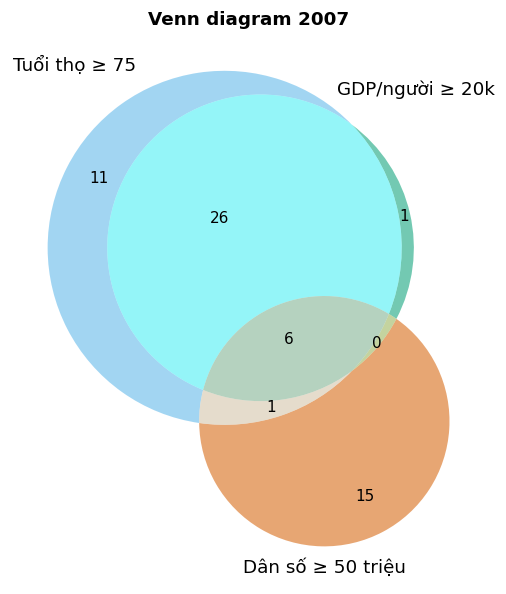

|A|, |B|, |C| = 44 33 22 | A∩B∩C: ['France', 'Germany', 'Italy', 'Japan', 'United Kingdom', 'United States'] | A−B: ['Albania', 'Argentina', 'Chile', 'Costa Rica', 'Croatia', 'Cuba', 'Mexico', 'Panama'] ...


In [ ]:
from matplotlib_venn import venn3
A = set(d07.loc[d07["lifeExp"] >= 75, "country"]); B = set(d07.loc[d07["gdpPercap"] >= 20000, "country"]); C = set(d07.loc[d07["pop"] >= 50e6, "country"])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
venn3([A, B, C], ("Tuổi thọ ≥ 75", "GDP/người ≥ 20k", "Dân số ≥ 50 triệu"), set_colors=(OKABE[1], OKABE[2], OKABE[5]), alpha=.55, ax=ax)
ax.set_title("Venn diagram 2007")
show("8c_venn")
print("|A|, |B|, |C| =", len(A), len(B), len(C), "| A∩B∩C:", sorted(A & B & C), "| A−B:", sorted(A - B)[:8], "...")

**Nhận xét / đáp án:**

|A| = 44, |B| = 33, |C| = 22; A∩B∩C = France, Germany, Italy, Japan, UK, US. Hình tròn Venn thường không đúng tỉ lệ diện tích (matplotlib-venn có điều chỉnh gần đúng).

### 8d) Flowchart diagram  `[Mở rộng]`  _(Slide 92)_  — **1.5 điểm**

> Vẽ flowchart (bằng matplotlib) mô tả đúng quy trình phân tích em đã làm ở Câu 1–6: Bắt đầu → Đọc dữ liệu → Kiểm tra chất lượng → [Có thiếu/trùng?] → (Có: Làm sạch) → Biến đổi (gdp, log, pd.cut) → Chọn loại biểu đồ theo loại biến → Vẽ → Nhận xét → Kết thúc. Dùng đúng ký hiệu: ô bầu dục (start/end), chữ nhật (process), hình thoi (decision).

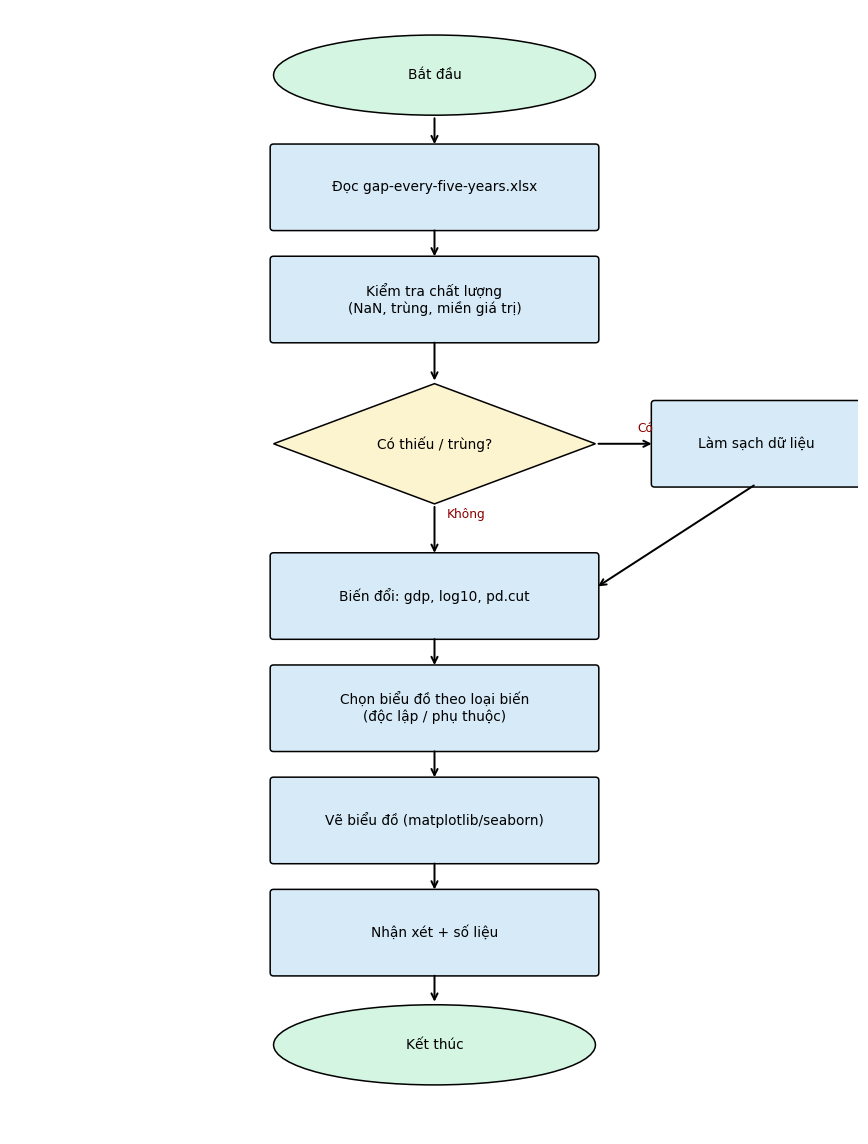

In [ ]:
from matplotlib.patches import FancyBboxPatch, Ellipse, Polygon
fig, ax = plt.subplots(figsize=(8, 10.5)); ax.set(xlim=(0, 10), ylim=(0, 14)); ax.axis("off")
def node(x, y, t, kind="r", w=3.8, h=1.0):
    if kind == "r": ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=.04", fc="#D6EAF8", ec="k"))
    elif kind == "o": ax.add_patch(Ellipse((x, y), w, h, fc="#D5F5E3", ec="k"))
    else: ax.add_patch(Polygon([[x, y + h/2 + .25], [x + w/2 + .4, y], [x, y - h/2 - .25], [x - w/2 - .4, y]], fc="#FCF3CF", ec="k"))
    ax.text(x, y, t, ha="center", va="center", fontsize=9)
def arr(x1, y1, x2, y2, t=""):
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", lw=1.3))
    if t: ax.text((x1 + x2) / 2 + .15, (y1 + y2) / 2 + .15, t, fontsize=8, color="darkred")
node(5, 13.2, "Bắt đầu", "o"); node(5, 11.8, "Đọc gap-every-five-years.xlsx"); node(5, 10.4, "Kiểm tra chất lượng\n(NaN, trùng, miền giá trị)")
node(5, 8.6, "Có thiếu / trùng?", "d", w=3.0); node(8.8, 8.6, "Làm sạch dữ liệu", w=2.4)
node(5, 6.7, "Biến đổi: gdp, log10, pd.cut"); node(5, 5.3, "Chọn biểu đồ theo loại biến\n(độc lập / phụ thuộc)"); node(5, 3.9, "Vẽ biểu đồ (matplotlib/seaborn)")
node(5, 2.5, "Nhận xét + số liệu"); node(5, 1.1, "Kết thúc", "o")
for a, b in [(13.2, 12.3), (11.8, 10.9), (10.4, 9.35)]: arr(5, a - .5 if a == 13.2 else a - .5, 5, b)
arr(5, 7.85, 5, 7.2, "Không"); arr(6.9, 8.6, 7.6, 8.6, "Có"); arr(8.8, 8.1, 6.9, 6.8); arr(5, 6.2, 5, 5.8); arr(5, 4.8, 5, 4.4); arr(5, 3.4, 5, 3.0); arr(5, 2.0, 5, 1.6)
show("8d_flowchart")

**Nhận xét / đáp án:** Hình thoi dùng cho quyết định, chữ nhật cho xử lý, bầu dục cho bắt đầu/kết thúc.

### 8e) Mindmap  `[Mở rộng]`  _(Slide 93)_  — **1.5 điểm**

> Vẽ mindmap top-down (bằng matplotlib) cho bộ dữ liệu Gapminder: nút gốc là bộ dữ liệu, 6 nhánh cấp 1 là 6 biến (country, year, lifeExp, pop, gdpPercap, gdp dẫn xuất) và mỗi nhánh có 3 nút lá là các biểu đồ phù hợp nhất cho biến đó. Giải thích từng lựa chọn gắn với loại biến.

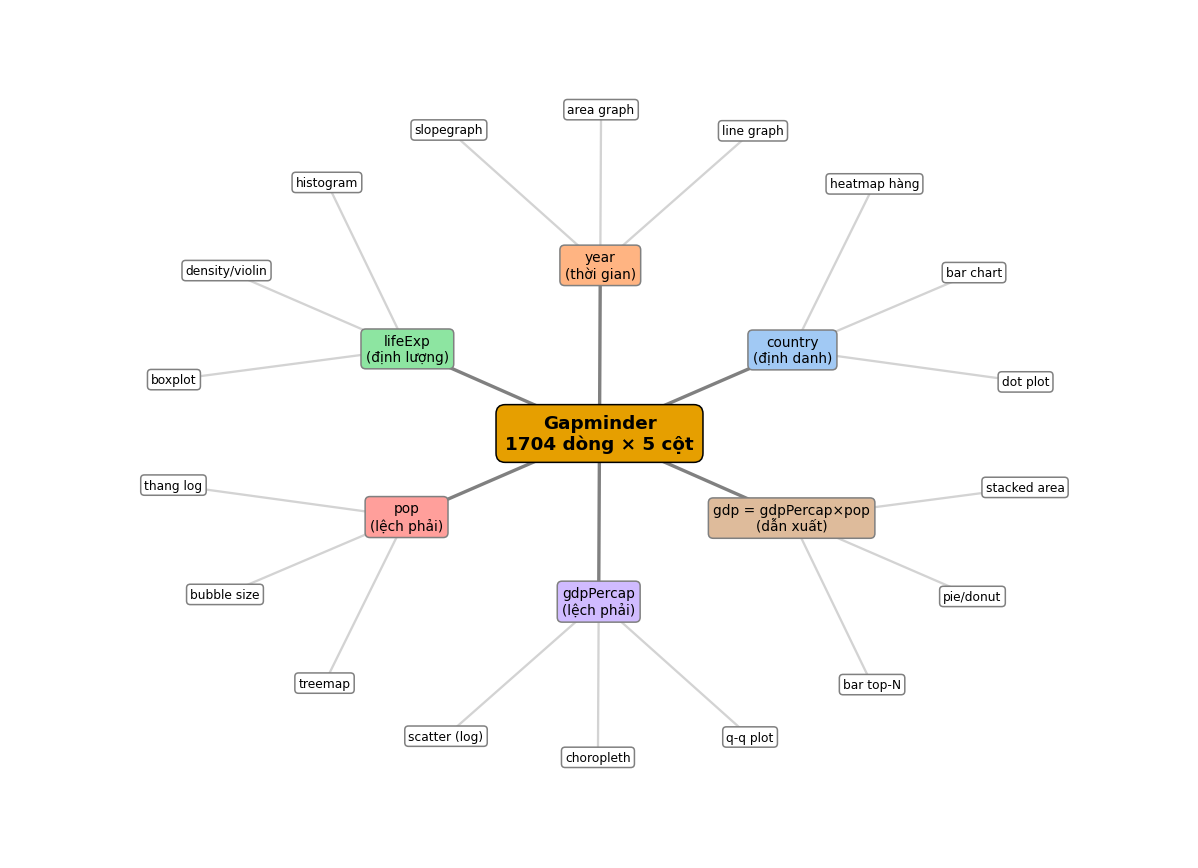

In [ ]:
import math
branches = {"country\n(định danh)": ["dot plot", "bar chart", "heatmap hàng"],
            "year\n(thời gian)": ["line graph", "area graph", "slopegraph"],
            "lifeExp\n(định lượng)": ["histogram", "density/violin", "boxplot"],
            "pop\n(lệch phải)": ["thang log", "bubble size", "treemap"],
            "gdpPercap\n(lệch phải)": ["scatter (log)", "choropleth", "q-q plot"],
            "gdp = gdpPercap×pop\n(dẫn xuất)": ["bar top-N", "pie/donut", "stacked area"]}
pal6 = sns.color_palette("pastel", 6)
fig, ax = plt.subplots(figsize=(11, 8)); ax.set(xlim=(-9, 9), ylim=(-6.8, 6.8)); ax.axis("off")
ax.text(0, 0, "Gapminder\n1704 dòng × 5 cột", ha="center", va="center", fontsize=12, fontweight="bold", bbox=dict(boxstyle="round,pad=.5", fc=OKABE[0]))
for i, (b, leaves) in enumerate(branches.items()):
    a = 2 * math.pi * i / 6 + .52; bx, by = 3.4 * math.cos(a), 2.7 * math.sin(a)
    ax.plot([0, bx], [0, by], color="gray", lw=2.2, zorder=1)
    ax.text(bx, by, b, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=.35", fc=pal6[i], ec="gray"), zorder=3)
    for j, l in enumerate(leaves):
        a2 = a + (j - 1) * .36; lx, ly = 6.6 * math.cos(a2), 5.2 * math.sin(a2)
        ax.plot([bx, lx], [by, ly], color="lightgray", zorder=1)
        ax.text(lx, ly, l, ha="center", va="center", fontsize=8, bbox=dict(boxstyle="round", fc="white", ec="gray"), zorder=3)
show("8e_mindmap")

**Nhận xét / đáp án:** Biến định danh → dot/bar/heatmap; thời gian → line/area/slope; định lượng → histogram/density/boxplot; biến lệch phải → thang log, kích thước bubble.

### 8f) Gantt chart  `[Mở rộng]`  _(Slide 94)_  — **1.5 điểm**

> Vẽ Gantt chart kế hoạch thực hiện bài thực hành này: ít nhất 7 công việc, thanh kế hoạch (xám gạch chéo) và thanh thực tế (xanh, mảnh hơn) chồng lên nhau, kim cương đánh dấu mốc kết thúc; đánh dấu đỏ và ghi số ngày trễ cho mọi công việc trễ so với kế hoạch.

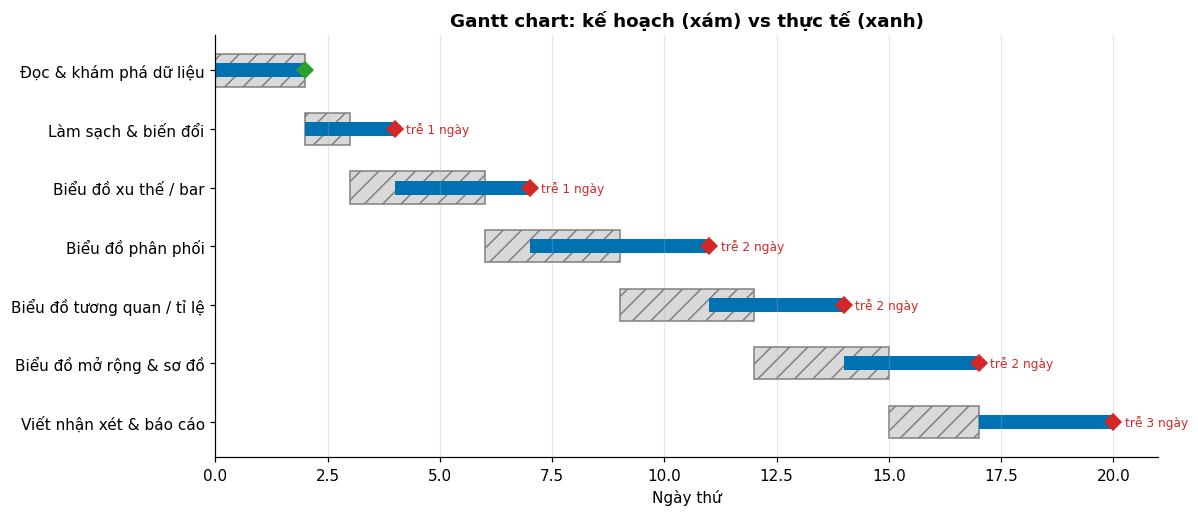

In [ ]:
tasks = [("Đọc & khám phá dữ liệu", 0, 2, 0, 2), ("Làm sạch & biến đổi", 2, 1, 2, 2), ("Biểu đồ xu thế / bar", 3, 3, 4, 3),
         ("Biểu đồ phân phối", 6, 3, 7, 4), ("Biểu đồ tương quan / tỉ lệ", 9, 3, 11, 3), ("Biểu đồ mở rộng & sơ đồ", 12, 3, 14, 3),
         ("Viết nhận xét & báo cáo", 15, 2, 17, 3)]
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (n_, ps_, pdur, as_, adur) in enumerate(tasks[::-1]):
    ax.barh(i, pdur, left=ps_, height=.55, color="#d9d9d9", hatch="//", edgecolor="gray")
    ax.barh(i, adur, left=as_, height=.24, color=OKABE[4])
    late = (as_ + adur) - (ps_ + pdur)
    ax.plot(as_ + adur, i, "D", color="#d62728" if late > 0 else "#2ca02c", ms=7)
    if late > 0: ax.text(as_ + adur + .25, i, f"trễ {late} ngày", va="center", fontsize=8, color="#d62728")
ax.set_yticks(range(len(tasks))); ax.set_yticklabels([t[0] for t in tasks[::-1]]); ax.set(xlabel="Ngày thứ", title="Gantt chart: kế hoạch (xám) vs thực tế (xanh)")
ax.grid(axis="y", alpha=0)
show("8f_gantt")

**Nhận xét / đáp án:** Công việc có kim cương đỏ là trễ kế hoạch; kế hoạch (xám) và thực tế (xanh) chồng lên nhau để so sánh.

### 8g) Fishbone diagram  `[Mở rộng]`  _(Slide 95)_  — **1.5 điểm**

> Vẽ fishbone (sơ đồ xương cá) cho 'vấn đề': các nước có tuổi thọ < 55 năm 2007. Có 6 nhánh nguyên nhân; nhánh dựa trên dữ liệu phải chứa số liệu tính được (số nước, gdpPercap trung vị của nhóm so với phần còn lại, mức tăng tuổi thọ từ 1952), các nhánh còn lại ghi rõ là GIẢ THUYẾT cần dữ liệu ngoài. Vì sao fishbone chỉ liệt kê nguyên nhân tiềm năng chứ không chứng minh quan hệ nhân quả?

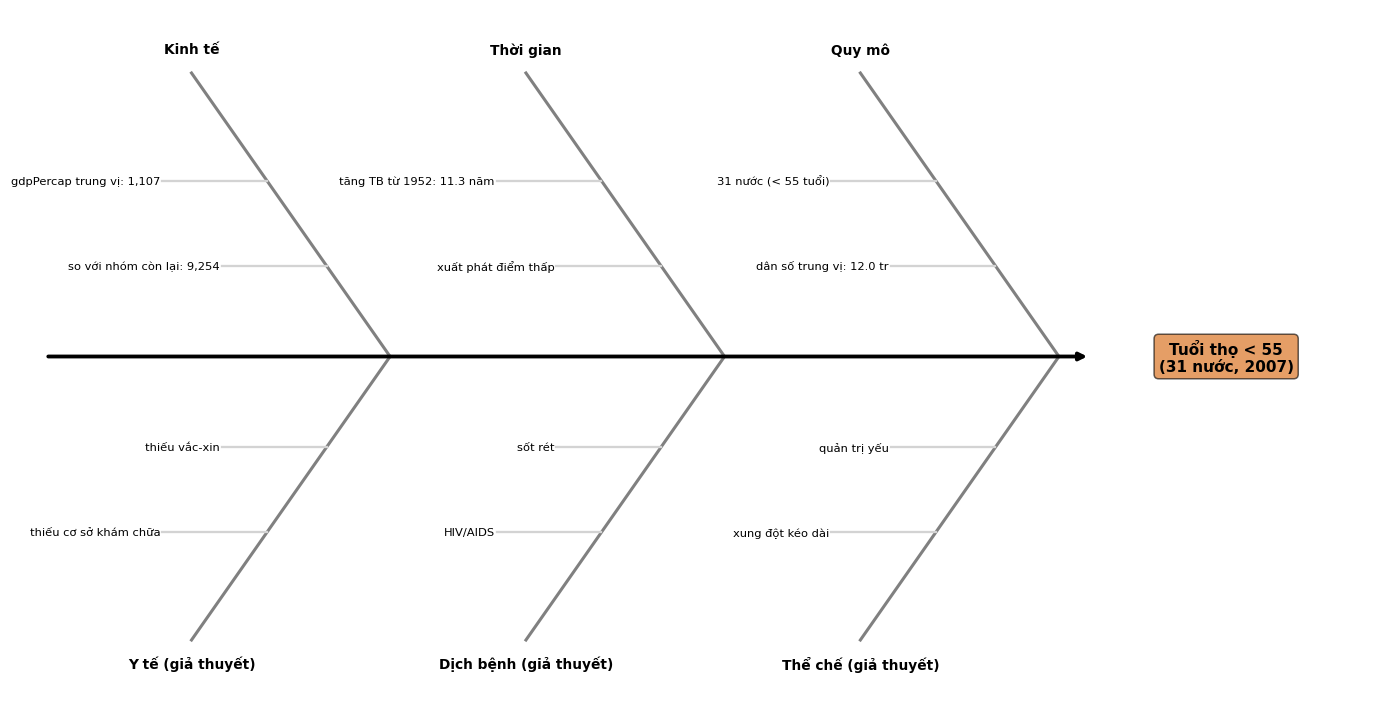

In [ ]:
low = d07[d07["lifeExp"] < 55]; rest_ = d07[d07["lifeExp"] >= 55]
gain = (low.set_index("country")["lifeExp"] - df[(df["year"] == 1952) & df["country"].isin(low["country"])].set_index("country")["lifeExp"]).median()
cats = [("Kinh tế", [f"gdpPercap trung vị: {low['gdpPercap'].median():,.0f}", f"so với nhóm còn lại: {rest_['gdpPercap'].median():,.0f}"]),
        ("Thời gian", [f"tăng TB từ 1952: {gain:.1f} năm", "xuất phát điểm thấp"]),
        ("Quy mô", [f"{len(low)} nước (< 55 tuổi)", f"dân số trung vị: {low['pop'].median()/1e6:.1f} tr"]),
        ("Y tế (giả thuyết)", ["thiếu cơ sở khám chữa", "thiếu vắc-xin"]),
        ("Dịch bệnh (giả thuyết)", ["HIV/AIDS", "sốt rét"]),
        ("Thể chế (giả thuyết)", ["xung đột kéo dài", "quản trị yếu"])]
fig, ax = plt.subplots(figsize=(13, 6.6)); ax.set(xlim=(0, 13), ylim=(-4.4, 4.4)); ax.axis("off")
ax.annotate("", (10.2, 0), (.2, 0), arrowprops=dict(arrowstyle="-|>", lw=2.5))
ax.text(11.5, 0, f"Tuổi thọ < 55\n({len(low)} nước, 2007)", ha="center", va="center", fontweight="bold", bbox=dict(boxstyle="round", fc=OKABE[5], alpha=.6))
for i, (c_, causes) in enumerate(cats):
    top = i < 3; x0 = 2.6 + (i % 3) * 3.2; y1 = 3.6 if top else -3.6
    ax.plot([x0 - 1.0, x0 + .9], [y1, 0], color="gray", lw=2)
    ax.text(x0 - 1.0, y1 + (.3 if top else -.3), c_, ha="center", va="center", fontweight="bold", fontsize=9)
    for k, cz in enumerate(causes):
        f = .62 - .3 * k; yy = y1 * f; xx = (x0 - 1.0) + 1.9 * (1 - f)
        ax.plot([xx - 1.0, xx], [yy, yy], color="lightgray"); ax.text(xx - 1.02, yy, cz, ha="right", va="center", fontsize=7.5)
show("8g_fishbone")

**Nhận xét / đáp án:** Fishbone chỉ liệt kê nguyên nhân tiềm năng theo nhóm; không có kiểm định nhân quả. Nhánh Kinh tế dựa trên dữ liệu; các nhánh còn lại là giả thuyết cần dữ liệu ngoài.

---
## Câu 9. Tổng hợp, phản biện và gỡ lỗi

### 9a) Gỡ lỗi (debug)  `[Nâng cao]`  — **2.0 điểm**

> ★Đoạn mã sau định vẽ 'top 10 GDP/người 2007', 'tỉ lệ dân số' và 'tương quan' nhưng chứa ít nhất 6 lỗi (kỹ thuật + trực quan hoá). Tìm tất cả, giải thích từng lỗi và viết lại đoạn mã đúng:
>
> ```python
> df = pd.read_excel("gap-every-five-years.xlsx")
> df["gdp"] = df.gdpPercap * df.pop                       # (1)
> d = df[df.year == "2007"]                               # (2)
> top = d.sort_values("gdpPercap").head(10)               # (3)
> plt.bar(top.country, top.gdpPercap)
> plt.ylim(20000, 50000)                                  # (4)
> plt.pie(d.pop[:142], labels=d.country)                  # (5)
> sns.heatmap(df.corr(), cmap="jet")                      # (6)
> ```

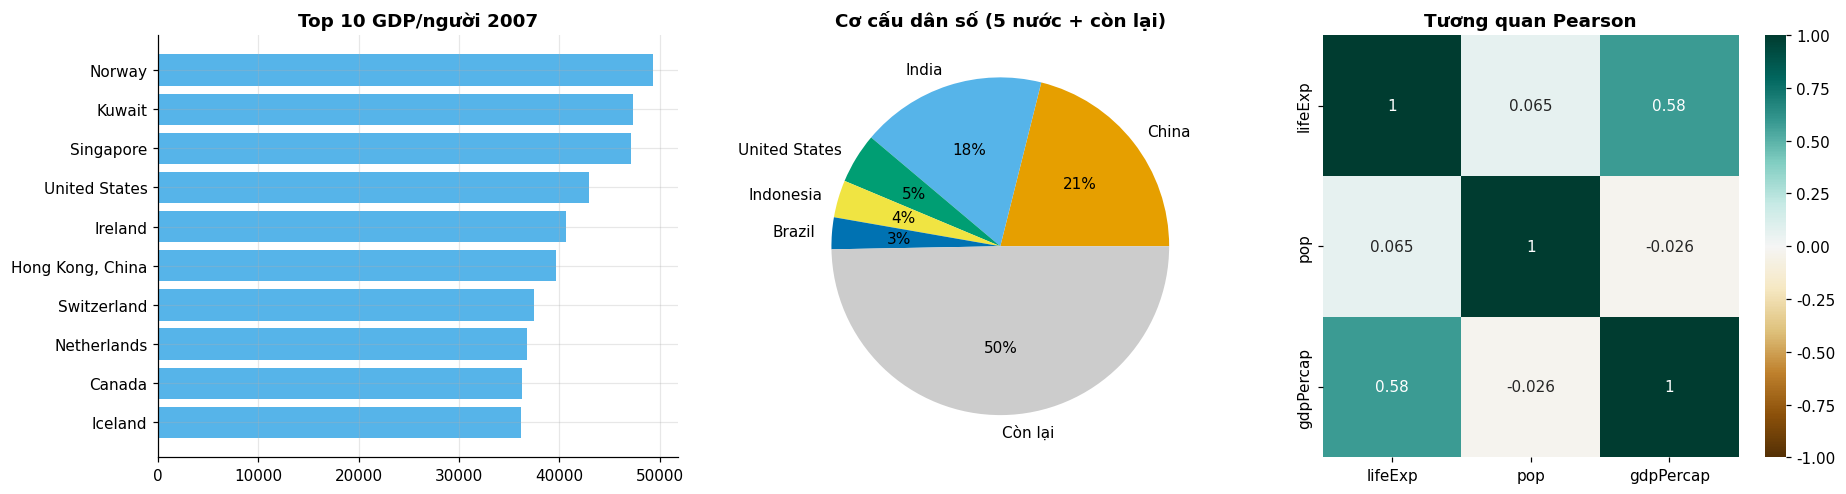

In [ ]:
df = pd.read_excel(DATA)
df["gdp"] = df["gdpPercap"] * df["pop"]                      # (1) df.pop là phương thức -> dùng df["pop"]
d = df[df["year"] == 2007]                                   # (2) year là int, không phải chuỗi "2007"
top = d.nlargest(10, "gdpPercap")                            # (3) sort tăng dần + head() cho 10 nước THẤP nhất
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
axs[0].barh(top["country"][::-1], top["gdpPercap"][::-1], color=OKABE[1])   # (4) thanh luôn bắt đầu từ 0 (không ylim 20000)
axs[0].set_title("Top 10 GDP/người 2007")
t5_ = d.nlargest(5, "pop"); vals_ = list(t5_["pop"]) + [d["pop"].sum() - t5_["pop"].sum()]
axs[1].pie(vals_, labels=list(t5_["country"]) + ["Còn lại"], autopct="%1.0f%%", colors=OKABE[:5] + ["#ccc"])   # (5) không pie 142 lát
axs[1].set_title("Cơ cấu dân số (5 nước + còn lại)")
sns.heatmap(df[["lifeExp", "pop", "gdpPercap"]].corr(), annot=True, cmap="BrBG", vmin=-1, vmax=1, center=0, ax=axs[2])  # (6) chỉ cột số, thang phân kỳ cố định
axs[2].set_title("Tương quan Pearson"); axs[2].grid(False)
show("9a_debug_fixed")

**Nhận xét / đáp án:** Sáu lỗi: (1) `df.pop` là phương thức; (2) so `year == "2007"` (int vs str) cho kết quả rỗng; (3) sort tăng dần + head() lấy 10 nước thấp nhất; (4) cột trục cắt gây hiểu lầm; (5) `d.pop` lỗi như (1) và pie 142 lát không đọc được; (6) `df.corr()` gồm cột chuỗi `country` gây lỗi, và thang `jet` không có tâm 0, thiếu vmin/vmax.

### 9b) Phê bình biểu đồ xấu – tốt  `[Nâng cao]`  _(Slide 21–25, 36, 45)_  — **2.0 điểm**

> ★Dựng 3 cặp biểu đồ 'XẤU vs TỐT' từ chính dữ liệu: (i) cột trục cắt vs cột trục từ 0, (ii) heatmap thang 'jet' (cầu vồng) vs viridis, (iii) pie 12 lát vs bar ngang đã sắp xếp (12 nước đông dân nhất 2007). Với mỗi cặp ghi một câu giải thích nguyên lý nhận thức bị vi phạm.

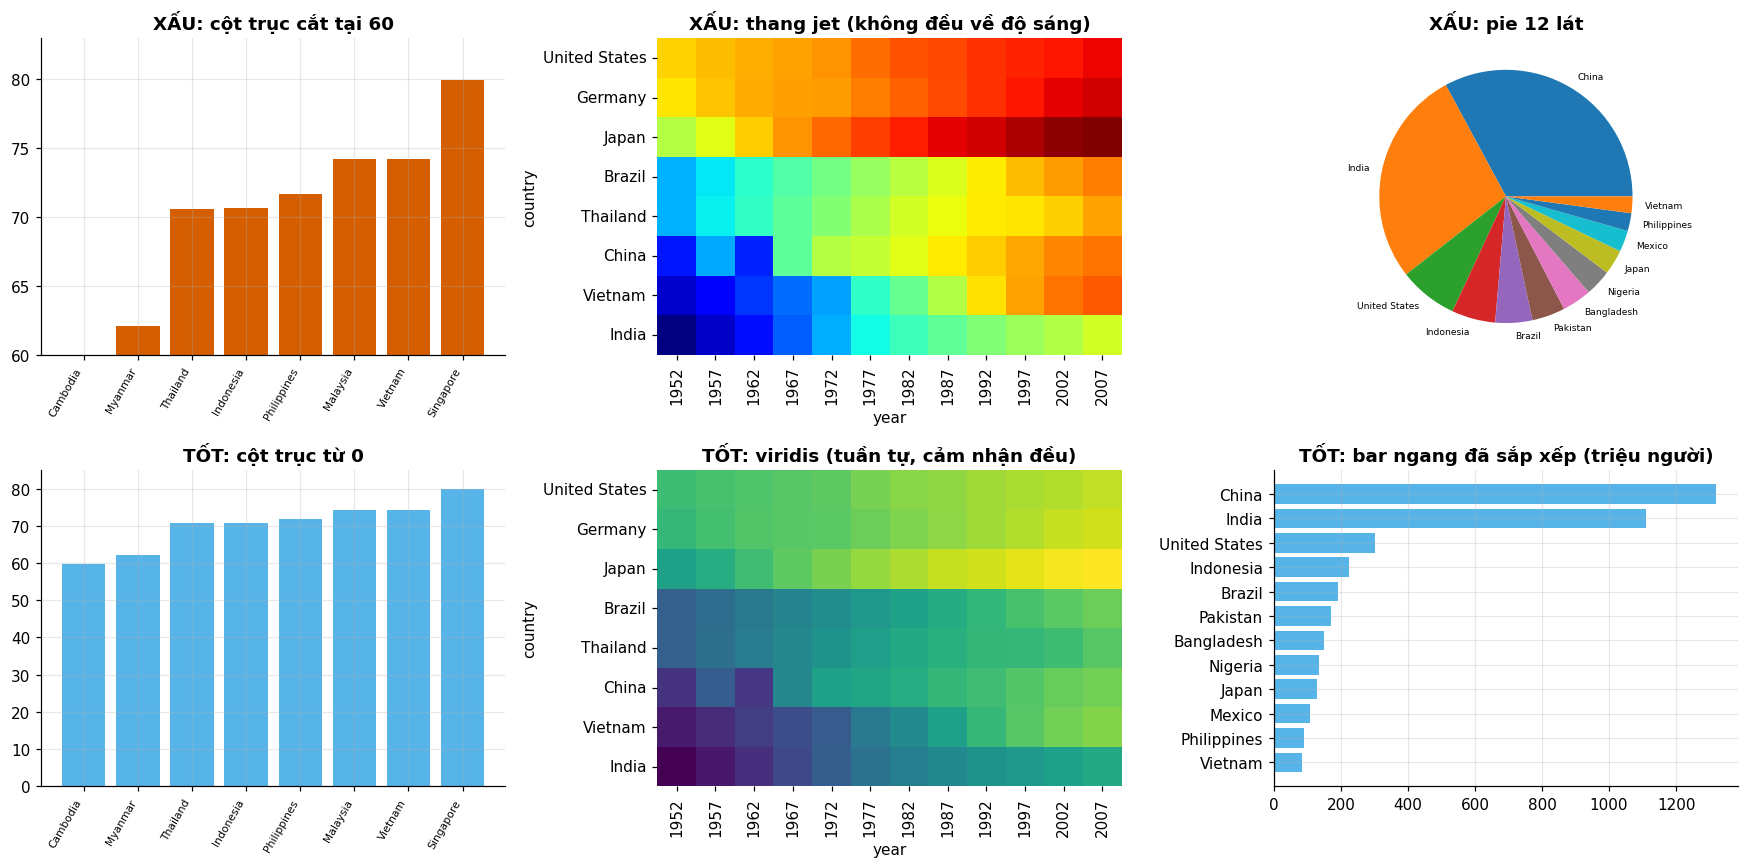

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(16, 8))
t12 = d07.nlargest(12, "pop")
dd2 = d07[d07["country"].isin(sea)].sort_values("lifeExp")
axs[0, 0].bar(dd2["country"], dd2["lifeExp"], color=OKABE[5]); axs[0, 0].set(ylim=(60, 83), title="XẤU: cột trục cắt tại 60"); plt.setp(axs[0, 0].get_xticklabels(), rotation=60, ha="right", fontsize=7)
axs[1, 0].bar(dd2["country"], dd2["lifeExp"], color=OKABE[1]); axs[1, 0].set(ylim=(0, 85), title="TỐT: cột trục từ 0"); plt.setp(axs[1, 0].get_xticklabels(), rotation=60, ha="right", fontsize=7)
sns.heatmap(hm, cmap="jet", cbar=False, ax=axs[0, 1]); axs[0, 1].set_title("XẤU: thang jet (không đều về độ sáng)")
sns.heatmap(hm, cmap="viridis", cbar=False, ax=axs[1, 1]); axs[1, 1].set_title("TỐT: viridis (tuần tự, cảm nhận đều)")
axs[0, 2].pie(t12["pop"], labels=t12["country"], textprops=dict(fontsize=6)); axs[0, 2].set_title("XẤU: pie 12 lát")
axs[1, 2].barh(t12["country"][::-1], t12["pop"][::-1] / 1e6, color=OKABE[1]); axs[1, 2].set(title="TỐT: bar ngang đã sắp xếp (triệu người)")
for a in axs[:, 1]: a.grid(False)
show("9b_bad_vs_good")

**Nhận xét / đáp án:** (i) Trục cắt vi phạm 'độ dài ∝ giá trị'; (ii) jet không đều về độ sáng nên tạo ranh giới giả; (iii) pie 12 lát vi phạm so sánh góc/diện tích, bar đã sắp xếp so sánh độ dài trên trục chung.

### 9c) Chọn biểu đồ theo loại biến  `[Nâng cao]`  _(Slide 27–28)_  — **2.0 điểm**

> ★Cho 5 tình huống, hãy xác định biến độc lập/phụ thuộc, loại biến (định danh, thứ tự, định lượng rời rạc/liên tục) rồi chọn biểu đồ phù hợp nhất, nêu 1 lựa chọn bị loại và lý do: (1) Tuổi thọ 142 nước năm 2007 — phân phối ra sao? (2) Việt Nam so với Thái Lan qua 12 năm. (3) 5 nước chiếm bao nhiêu % dân số thế giới? (4) Quan hệ GDP/người – tuổi thọ có thêm quy mô dân số. (5) Nhóm thu nhập nào hội tụ tuổi thọ nhanh nhất từ 1952 đến 2007?

**Nhận xét / đáp án:**

| Tình huống | Biến độc lập → phụ thuộc | Biểu đồ chọn | Loại bỏ vì |
|---|---|---|---|
| (1) Phân phối lifeExp 2007 | lifeExp (liên tục) → tần số/mật độ | Histogram (FD) + density, thêm boxplot nếu so nhóm | Bar chart: dữ liệu liên tục, thanh không được cách nhau |
| (2) VN so TL qua thời gian | year (rời rạc, có thứ tự) → lifeExp | Line graph 2 mầu, gắn nhãn trực tiếp | Radar: dữ liệu không có chu kỳ |
| (3) Tỉ lệ dân số | quốc gia (định danh) → pop | Bar ngang đã sắp xếp (hoặc donut ≤ 5 lát có 'Còn lại') | Pie 142 lát: không đọc được |
| (4) GDP – tuổi thọ – dân số | gdpPercap (log) → lifeExp; pop = kích thước | Bubble chart, trục x log | Scatter đơn thuần: mất chiều dân số |
| (5) Hội tụ theo nhóm thu nhập | year × tier → lifeExp | Line/ribbon (TB ± CI) theo tier hoặc ridgeline theo năm | Stacked bar: không thấy xu thế |

### 9d) Lý thuyết: hệ trục, mầu, gestalt  `[Nâng cao]`  _(Slide 12–25, 5–7)_  — **2.0 điểm**

> ★Trả lời ngắn gọn (mỗi ý 2–4 câu): (i) Phân biệt thang tuyến tính và thang log bằng ví dụ 'mỗi bước +c' và 'mỗi bước ×c'; khi nào dùng log? (ii) Phân biệt ba vai trò của mầu: phân nhóm, biểu diễn giá trị, nhấn mạnh — mỗi vai trò dùng loại thang mầu nào và cho ví dụ ngay trong bài này? (iii) Vì sao hệ toạ độ cực chỉ nên dùng cho dữ liệu có tính chu kỳ? (iv) 'Less is more' (slide 7) áp dụng vào việc gỡ bỏ yếu tố nào trong biểu đồ của em? (v) Giải thích 'biểu đồ có tính trực quan, hình ảnh tổng quan, khả năng diễn đạt phong phú' (slide 5–7) bằng một biểu đồ cụ thể em đã vẽ.

**Nhận xét / đáp án:**

- **(i) Tuyến tính vs log**: thang tuyến tính cộng một hằng số mỗi bước (0, 25, 50, 75, 100); thang log nhân/chia một hằng số mỗi bước (1, 10, 100…, cách đều nhau trên trục). Dùng log khi dữ liệu là tỉ số/tốc độ tăng hoặc trải trên nhiều bậc độ lớn (gdpPercap, pop): ở Câu 4b điểm không còn dồn về góc trái và quan hệ với lifeExp thành gần tuyến tính.
- **(ii) Ba vai trò của mầu**: *phân nhóm* → thang phân loại (Okabe-Ito: các nước, tier); *biểu diễn giá trị định lượng* → thang tuần tự (viridis: heatmap 6a, choropleth 7e) hoặc phân kỳ khi có tâm 0 (6b, 6d); *nhấn mạnh* → xám + một mầu nổi (accent: Việt Nam ở 4a, 6f, 6g).
- **(iii) Toạ độ cực**: trục góc phải 'khép vòng' mới có nghĩa (tháng trong năm, giờ trong ngày). Với năm 1952→2007 (Câu 2d) điểm cuối nối về điểm đầu, tạo ra quan hệ liền kề không có thật; ngoài ra bán kính/diện tích khó so sánh hơn độ dài trên trục thẳng.
- **(iv) Less is more**: bỏ viền trên/phải, lưới đậm, chú giải thừa (nhãn trực tiếp thay chú giải), bỏ hiệu ứng 3D; bỏ thanh mầu thừa khi mầu trùng với trục y.
- **(v) Trực quan – tổng quan – diễn đạt**: bubble chart 4f mã hoá 4 biến (x, y, kích thước, mầu) trong một khung hình; người xem nắm ngay hình dạng tổng thể (quan hệ cong, nhóm thu nhập cao tách biệt) mà bảng 142 dòng không cho thấy.